# Detection and prediction of pump-and-dump schemes on cryptocurrency markets

**Time series, machine learning and deep learning — complete report**

*Module Projet mathématiques, spécialité Infini, 2026–2027. Reproduction and extension of Hu et al. (SIGMOD 2023) [A1]
with the method of Pacheco et al. (ICWSM 2021) [A2], on the data of the authors' repository [3].*

---

## Introduction

A **pump-and-dump** (P&D) is a market manipulation: organisers discreetly buy an illiquid asset, push its price up
through a coordinated campaign (the *pump*), then sell at the top to participants who arrived too late (the *dump*).
[A1] collects 709 such events organised by Telegram channels between 2019 and 2022 and shows that the target coin can
be predicted one hour before the announcement.

The project plays the role of a **market-surveillance service**. Its objectives are to (O1) understand the mechanisms
and signatures of a P&D, (O2) read and reproduce published results, (O3) run an event study, (O4) model financial
series and detect anomalies, (O5) evaluate a highly imbalanced ranking problem without temporal leakage, and (O6)
compare machine-learning and deep-learning models.

**Notation.** $P_{c,t}$ is the price, $V_{c,t}$ the volume and $r_{c,t}=\log P_{c,t}-\log P_{c,t-1}$ the log-return of
coin $c$. An event is $e=(h,c^\star,\tau)$ with channel $h$, target $c^\star$ and pump time $\tau$; $\mathcal H_h(\tau)$ is
the channel's history. For $N$ test events, with $\rho_i$ the rank of the true target among about 200 candidates,
$\mathrm{HR}@k=\frac1N\sum_{i=1}^N\mathbf 1\{\rho_i\le k\}$.

**Protocol.** Chronological split identical to [A1] (train before 2021-01-19, validation until 2021-05-10, test
afterwards); every variable of event $i$ is computable at $\tau_i-1$ h; hyperparameters are chosen on validation and the
test set is used once; results are averaged over several random seeds with their standard deviation.

**How this report was produced.** Each section below is an independent notebook (`notebooks/`) that loads the raw
data itself; the market data are re-downloaded from Binance's public archive. The code is hidden in this PDF and
visible in the per-step PDFs. Numbers come from the **QUICK** configuration (reduced numbers of seeds, permutation
draws and tuning trials) unless the run was made with `PND_QUICK=0`; every statement printed next to a result is
generated from the computed values.

**Ethics.** The project serves detection and investor protection; using the models to take part in a P&D is
forbidden. Channel identifiers are anonymised (`Ch-001`, ...). The repository's data have no licence and are not
redistributed.


# Part I — Expertise of the phenomenon

## I.0 — Data acquisition and audit

**Role E1 (data and repository).** This notebook gathers every data source used by the project, re-downloads the
market data from Binance's public archive instead of trusting copies, and audits the authors' P&D log against the
figures quoted by the brief and by the paper [A1] (Hu et al., SIGMOD 2023).

| Source | What it contains | How it is obtained here |
|---|---|---|
| `Data/Telegram/Labeled/PD_logs_cleaned.txt` | one row per (channel, pump): channel id, session id, coin, exchange, pair, timestamp | authors' file, read-only |
| Binance spot klines (1 h, 1 min) | OHLCV, quote volume, taker-buy volume, trade count | **downloaded** from `data.binance.vision` (monthly archives, cached) |
| `coinDate2Statistics_pred3d.json` | CoinGecko snapshot of each pump target 3 days before the pump | authors' file |
| `neg_coin_gecko_statistics.txt` | the same statistics for the non-target (candidate) coins | authors' file |
| `neg_binance_required_file_name.txt` | the (symbol, month) pairs the authors used as negatives | authors' file, defines the coin universe |
| `Data/Telegram/raw/*.pkl` | raw channel posts (Telethon dictionaries) | authors' files, used in II.D |

Every later notebook re-loads what it needs through `pnd_paper` (no notebook reads another notebook's output);
downloads go to a shared cache so they happen once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pnd_paper import settings
from pnd_paper.data import pd_log, binance, universe, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES

settings.seed_everything()
R = Reporter("I0_data_acquisition")
md(f"Run mode: **{'QUICK' if settings.QUICK else 'FULL'}** (set `PND_QUICK=0` for the full sizes).")

Run mode: **QUICK** (set `PND_QUICK=0` for the full sizes).

### 1. The P&D log

**Definition.** A *sample* is a row of the log, i.e. a pair (channel $h$, pump announcement). An *event*
$e=(h, c^\star, \tau)$ in the brief's notation is a pump of coin $c^\star$ announced by channel $h$ at time $\tau$.
Several channels often relay the **same** pump (same coin, same exchange, same minute); [A1] calls the set of
rows describing the same pump an *event* and reports 1 335 samples for 709 events.

We audit the figures quoted by the brief: 1 335 rows, 108 channels, 277 coins, 75 % of rows on Binance and 91 % with
a BTC quote.

In [2]:
log = pd_log.load_pd_log()
audit = pd.DataFrame({
    "brief": [1335, 108, 277, 0.75, 0.91],
    "paper [A1]": [1335, 108, 278, np.nan, np.nan],
    "observed": [len(log), log.channel_id.nunique(), log.coin.nunique(), (log.exchange == "binance").mean(), (log.pair == "BTC").mean()],
}, index=["rows (samples)", "channels", "coins", "share Binance", "share BTC pair"])
R.table(audit, "audit_vs_brief")
show(audit)

,brief,paper [A1],observed
rows (samples),1335,1335,1335
channels,108,108,108
coins,277,278,277
share Binance,0.75,nan,0.7513
share BTC pair,0.91,nan,0.9071


#### From samples to events

Two rows belong to the same pump when they share the coin, the exchange and the announcement time up to a tolerance
$\delta$. Let $G_\delta$ be the graph whose vertices are rows and whose edges join rows with the same
(coin, exchange) and $|\tau_a-\tau_b|\le\delta$; events are the connected components of $G_\delta$. We report the
number of events for several $\delta$ to see which convention reproduces the paper's 709.

In [3]:
def count_events(df, delta):
    n = 0
    for _, g in df.sort_values("timestamp").groupby(["coin", "exchange"]):
        gaps = g.timestamp.diff() > delta
        n += 1 + int(gaps.sum())
    return n

deltas = {"same minute": pd.Timedelta(minutes=1), "1 hour": pd.Timedelta(hours=1), "12 hours": pd.Timedelta(hours=12),
          "1 day": pd.Timedelta(days=1), "3 days": pd.Timedelta(days=3)}
ev_counts = pd.DataFrame({"events": {k: count_events(log, d) for k, d in deltas.items()}})
ev_counts["Binance events"] = {k: count_events(log[log.exchange == "binance"], d) for k, d in deltas.items()}
R.table(ev_counts, "events_by_tolerance")
show(ev_counts)

,events,Binance events
same minute,779,516
1 hour,704,446
12 hours,698,440
1 day,691,437
3 days,680,430


The paper's modelling set keeps the Binance rows with a BTC quote (948 positive samples, §6.1). We keep the same
population and drop exact duplicates (same channel, same coin, same minute), which gives the **event table** used
by every Binance-based notebook.

In [4]:
ev = pd_log.binance_btc_events(log)
split_counts = ev.split.value_counts().reindex(["train", "valid", "test"])
md(f"Binance/BTC samples after de-duplication: **{len(ev)}** (paper: 948). "
   f"Split by the paper's dates (train $\\tau<$ 2021-01-19 $\\le$ valid $<$ 2021-05-10 $\\le$ test): "
   f"train = {split_counts['train']}, valid = {split_counts['valid']}, test = {split_counts['test']} "
   f"(paper: 648 / 100 / 200).")
R.table(ev.drop(columns=["channel_id"]), "binance_btc_events", index=False)

Binance/BTC samples after de-duplication: **981** (paper: 948). Split by the paper's dates (train $\tau<$ 2021-01-19 $\le$ valid $<$ 2021-05-10 $\le$ test): train = 655, valid = 100, test = 226 (paper: 648 / 100 / 200).

WindowsPath('C:/Users/Dr.Console/Desktop/Pump-and-Dump-Detection-on-Cryptocurrency-master/results/I0_data_acquisition/tables/binance_btc_events.csv')

### 2. Binance hourly klines

The coin universe $\mathcal U$ is the set of BTC-quoted symbols that the authors used as negatives
(`neg_binance_required_file_name.txt`) together with every pump target. For each symbol we download all monthly
hourly archives between November 2018 and February 2022 (the first month leaves room for the 30-day estimation
window of I.3). A missing archive (HTTP 404) means the symbol was not trading that month.

In [5]:
symbols = universe.universe(ev) + ["BTCUSDT"]
panels = binance.build_hourly_panel(symbols, universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]
rep = pd.read_csv(settings.CACHE / "panels" / "hourly" / "download_report.csv")
coverage = pd.DataFrame({
    "symbols requested": [len(symbols)],
    "symbols with data": [int(close_.notna().any().sum())],
    "monthly archives requested": [len(rep)],
    "archives found": [int(rep.found.sum())],
    "hours in panel": [len(close_)],
    "non-missing hourly bars": [int(close_.notna().sum().sum())],
})
R.table(coverage.T.rename(columns={0: "value"}), "hourly_coverage")
show(coverage.T.rename(columns={0: "value"}))

,value
symbols requested,503
symbols with data,390
monthly archives requested,20120
archives found,8531
hours in panel,29184
non-missing hourly bars,6093862


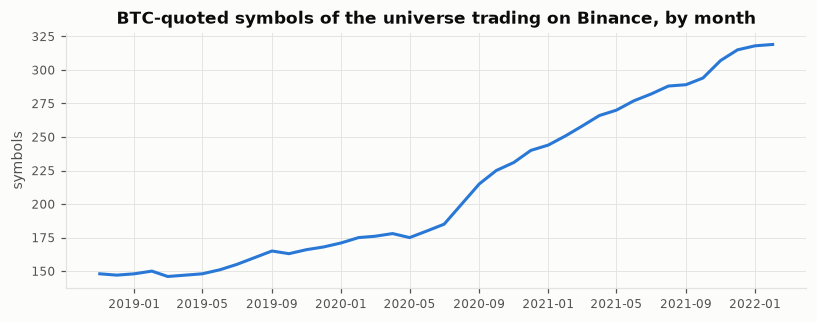

In [6]:
listed = close_.drop(columns="BTCUSDT").notna().resample("MS").max().sum(axis=1)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(listed.index, listed.values, color=SERIES[0])
ax.set_title("BTC-quoted symbols of the universe trading on Binance, by month")
ax.set_ylabel("symbols")
R.fig(fig, "universe_size")
close(fig)

#### Candidate sets

For event $i$ the candidate set $\mathcal C_i\subset\mathcal U$ holds the symbols trading during the 72 hours that
precede $\tau_i-1\,$h: the bar at $\tau_i-1\,$h exists and at least 60 of the previous 72 hourly bars exist. This is
the paper's "other eligible coins listed on Binance at the time of pump events". An event is usable when its
target belongs to $\mathcal C_i$.

Events whose target has hourly data at $\tau-1$h: **947 / 981**. Candidate set size $|\mathcal C_i|$: median 176, range [145, 314] (paper: about 206 negatives per positive on average). Positive ratio $1/|\mathcal C_i|$ averaged: 0.0052 (paper: 0.0048).

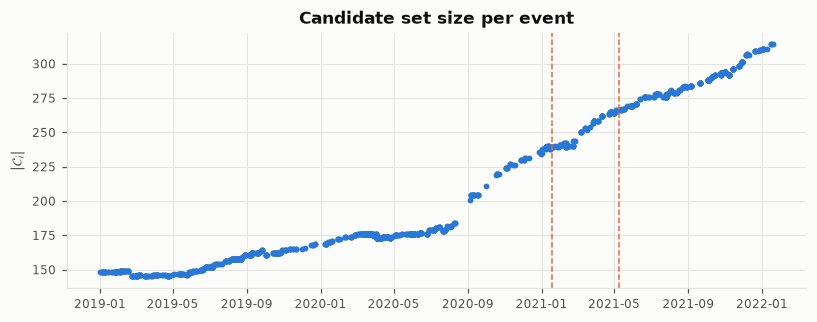

In [7]:
cands = universe.candidate_sets(ev, close_)
has_t = cands.groupby("event_id").label.max()
sizes = cands.groupby("event_id").size()
md(f"Events whose target has hourly data at $\\tau-1$h: **{int(has_t.sum())} / {len(ev)}**. "
   f"Candidate set size $|\\mathcal C_i|$: median {sizes.median():.0f}, range [{sizes.min()}, {sizes.max()}] "
   f"(paper: about 206 negatives per positive on average). Positive ratio "
   f"$1/|\\mathcal C_i|$ averaged: {(1 / sizes).mean():.4f} (paper: 0.0048).")
fig, ax = plt.subplots(figsize=(7.5, 3))
t = ev.set_index("event_id").timestamp.reindex(sizes.index)
ax.scatter(t, sizes.values, s=8, color=SERIES[0])
ax.set_title("Candidate set size per event")
ax.set_ylabel(r"$|\mathcal{C}_i|$")
for d in (settings.TRAIN_END, settings.VALID_END):
    ax.axvline(d, color=SERIES[1], lw=1, ls="--")
R.fig(fig, "candidate_set_size")
close(fig)

### 3. CoinGecko statistics

The authors queried CoinGecko's `/coins/{id}/history` endpoint three days before each pump. We check how many
targets and candidates are covered and the rate of missing values per field; missingness that differs between
targets and candidates would leak the label into a classifier, so it is examined here and handled in II.B.

In [8]:
gk = coingecko.load_all()
miss = gk.groupby("source")[coingecko.COLUMNS].apply(lambda d: d.isna().mean()).T
miss.columns = [f"missing share ({c})" for c in miss.columns]
R.table(miss, "coingecko_missingness")
show(miss, "{:.3f}")

,missing share (candidates),missing share (targets)
market_cap_usd,0.030,0.174
market_cap_btc,0.030,0.174
price_usd,0.000,0.049
price_btc,0.000,0.049
volume_usd,0.000,0.049
volume_btc,0.000,0.049
twitter_followers,0.156,0.214
reddit_subscribers,0.256,0.346
alexa_rank,0.035,0.149


### 4. Known data findings

The re-implementation of the authors' code (see `QUIRKS.md`) found two facts that matter for the analyses below:

* **Q37** — the shipped cleaned log differs from what the authors' cleaning script produces by 22 manual edits
  (exchange case, one coin, one dropped row). The log is nevertheless used as is: it is the authors' ground truth.
* **Binance audit** — on the first 100 rows, 99 archives exist and 93 of 99 pumps show a price spike of at least
  5 % within an hour of the announced time, so the timestamps are reliable at the hourly scale used here.

### 5. Summary

The data reproduce the brief's description of the log exactly. The paper's 709 events correspond to a de-duplication
of the 1 335 rows over relayed announcements; the Binance/BTC modelling population (981 de-duplicated rows here,
948 in the paper) is close to the paper's, and our split sizes differ from the paper's 648/100/200 because the paper
applies further filters that it does not describe.

## I.1 — Literature synthesis

**Role E2 (bibliography and report).** The brief asks four questions, answered from [A1] (Hu et al., SIGMOD 2023)
and [A2] (Pacheco et al., ICWSM 2021) and illustrated, where possible, with the data of this repository:

1. Why do organisers target mid-capitalisation coins?
2. What do intra-channel homogeneity and inter-channel heterogeneity of targets mean?
3. How does [A1] handle the cold start?
4. What do the European regulations MAR and MiCA provide on market manipulation?

**The pump-and-dump scheme in brief** ([A1] §2, [4]). Organisers announce the exchange and the time in advance but
keep the target secret. Insiders (organisers, VIP members who pay for early access) buy before the announcement (the
*pre-pump*, which [A1] dates to up to about 60 hours before). At the announced minute the coin is revealed; members
rush in, and the price can multiply within a minute (+250 % for NAS on Binance on 22 August 2021). Insiders then
sell into the buying wave (the *dump*), and the price collapses within minutes, leaving late buyers with the loss.

In [1]:
import pandas as pd

from pnd_paper.data import pd_log, coingecko
from pnd_paper.report import Reporter, md, show

R = Reporter("I1_literature_synthesis")
log = pd_log.load_pd_log()
ev = pd_log.binance_btc_events(log)

### 1. Why mid-capitalisation coins?

A pump must satisfy two conflicting constraints.

* **Movability.** The price impact of a buy order of size $Q$ grows with $Q$ relative to the coin's liquidity
  (order-book depth, which scales with capitalisation and volume). A large-cap coin cannot be moved by a few
  thousand members with modest budgets. [A1] notes that organisers choose coins whose market is thin enough to
  be pushed.
* **Exit liquidity.** Insiders profit only if they can *sell* their position at the top. For a micro-cap coin the
  order book on the sell side is so shallow that insiders cannot unload without crashing the price themselves, and
  very small coins are often not listed on the large exchanges where the members trade (Binance requires a listing).
  Detection risk also grows: an obscure coin multiplying by ten is conspicuous.

Hence the "sweet spot": coins small enough to be moved, large enough to be listed on a major exchange and to absorb
the insiders' sales. [A1] §4.3 shows that pumped coins concentrate in a band of market capitalisation and audience
(Alexa rank, Reddit subscribers). Our data (I.2) make it quantitative:

In [2]:
gk = coingecko.load_all()
t = gk[gk.source == "targets"].market_cap_usd.dropna()
c = gk[gk.source == "candidates"].market_cap_usd.dropna()
q = pd.DataFrame({"targets": t.quantile([0.1, 0.25, 0.5, 0.75, 0.9]) / 1e6,
                  "coins listed on Binance (same dates)": c.quantile([0.1, 0.25, 0.5, 0.75, 0.9]) / 1e6})
q.index = [f"{int(100 * i)}th percentile" for i in q.index]
R.table(q, "mcap_quantiles_musd")
show(q, "{:.1f}")
md(f"Market capitalisation in millions of USD, three days before the pump. The median target "
   f"(USD {t.median() / 1e6:.0f}M) is about {c.median() / t.median():.0f} times smaller than the median coin listed on Binance "
   f"at the same dates, and 90 % of targets lie between USD {t.quantile(0.05) / 1e6:.0f}M and "
   f"USD {t.quantile(0.95) / 1e6:.0f}M (5th–95th percentiles): small to mid caps relative to the exchange, almost never "
   "the large caps.")

,targets,coins listed on Binance (same dates)
10th percentile,3.3,6.1
25th percentile,6.5,16.1
50th percentile,14.2,67.1
75th percentile,29.5,311.5
90th percentile,68.0,1669.9


Market capitalisation in millions of USD, three days before the pump. The median target (USD 14M) is about 5 times smaller than the median coin listed on Binance at the same dates, and 90 % of targets lie between USD 2M and USD 134M (5th–95th percentiles): small to mid caps relative to the exchange, almost never the large caps.

### 2. Intra-channel homogeneity and inter-channel heterogeneity

* **Intra-channel homogeneity** ([A1] §4.3): the coins pumped by *one* channel resemble each other in market
  capitalisation, popularity and age. A channel has a stable community with a given total budget and risk
  appetite; the organisers learn which coins this community can move and keep choosing similar ones. [A1] also
  finds that word embeddings of coins pumped by the same channel are more similar (cosine 0.92) than those of
  random pumped coins (0.80) or random coins (0.72).
* **Inter-channel heterogeneity**: different channels work in different niches; a large channel with tens of
  thousands of members targets bigger coins than a small one.

**Consequence for prediction.** A single global "pumpability" score misses this structure: the relevant question is
"which coin would *this* channel pick next?". [A1] therefore conditions the prediction on the channel's sequence of
past targets (the SNN). It also explains the high re-pump rate (60.1 % of pumped coins are pumped again, §4.1).
In this project, I.4 tests homogeneity with a permutation test (rejecting the null of exchangeable channel labels),
and II.B/II.C measure how much channel-history features improve ranking.

[A2] provides the complementary *network* view used in I.5: accounts (here channels) that share rare behavioural
traces (here the same coin in the same hour) are linked, and dense groups reveal coordination that no single
account's behaviour shows.

### 3. Cold start in [A1]

The SNN represents every coin by a learned embedding $E(c)$, shared by the target candidate and the history
elements. Two cold-start situations break it ([A1] §5.3): (i) the coin pumped in the test period has never been
pumped during training, so its embedding received no signal from positive examples; (ii) the coin did not exist
during training at all. [A1] replaces $E(c)$ by the **word embedding of the coin symbol**, pre-trained with SkipGram
(and CBOW) on a large corpus of Telegram messages from crypto channels and groups. Coins discussed in similar
contexts get similar vectors even if they were never pumped. The variant, called SNN$_S$, improves HR@1 from 0.260
to 0.277 and HR@30 from 0.797 to 0.823 (Table 6). How frequent is the problem in our data?

In [3]:
train_coins = set(ev[ev.split == "train"].coin)
seen = ev[ev.split == "test"].coin.isin(train_coins)
ever = ev.sort_values("timestamp").assign(prev=lambda d: d.groupby("coin").cumcount() > 0)
cs = pd.DataFrame({"value": [len(ev[ev.split == "test"]), (~seen).mean(), (~ever[ever.split == "test"].prev).mean()]},
                  index=["test events (Binance/BTC)", "share of test targets never pumped in the training period",
                         "share of test targets never pumped before (any earlier event)"])
R.table(cs, "cold_start_share")
show(cs, "{:.3f}")
md(f"About **{(~seen).mean():.0%}** of test targets were never pumped during training: for them the learned coin "
   "embedding carries no pump-specific signal, which is why a representation learned from text (or from the coin's "
   "market features) is needed. II.C rebuilds SNN$_S$ with embeddings learned from the authors' Telegram corpus.")

,value
test events (Binance/BTC),226.000
share of test targets never pumped in the training period,0.473
share of test targets never pumped before (any earlier event),0.177


About **47%** of test targets were never pumped during training: for them the learned coin embedding carries no pump-specific signal, which is why a representation learned from text (or from the coin's market features) is needed. II.C rebuilds SNN$_S$ with embeddings learned from the authors' Telegram corpus.

### 4. European regulation: MAR and MiCA

**MAR — Regulation (EU) No 596/2014 on market abuse.**
* *Scope* (Art. 2): financial instruments admitted to trading on a regulated market, an MTF or an OTF. Most crypto-assets
  (bitcoin, utility tokens) are **not** financial instruments under MiFID II, so MAR generally does not reach the
  pumps studied here, a gap that motivated MiCA.
* *Definition* (Art. 12): market manipulation covers transactions or orders that give false or misleading signals
  about supply, demand or price, or secure the price at an abnormal level (12(1)(a)); transactions using fictitious
  devices or deception (12(1)(b)); and the dissemination of false or misleading information, including rumours, via
  the media or the internet (12(1)(c)). Art. 12(2) gives examples, among them securing a dominant position and taking
  positions and then voicing opinions about the instrument to profit from the price impact.
* *Prohibition* (Art. 15) of manipulation and attempted manipulation; *prevention and detection* (Art. 16): market
  operators and persons professionally arranging or executing transactions must maintain effective arrangements and
  report suspicious orders and transactions (STORs) to the competent authority; *sanctions* (Art. 30): administrative
  fines of at least EUR 5 million for individuals and EUR 15 million or 15 % of turnover for legal persons for
  manipulation, alongside criminal sanctions under Directive 2014/57/EU (CSMAD).
* Commission Delegated Regulation (EU) 2016/522, Annex II, lists example practices for the indicators of
  manipulation of MAR Annex I; **"pump and dump"** is named explicitly (Section 1, point 4(c)): taking a long
  position, disseminating misleading positive information to raise the price, and selling at the inflated price.

**MiCA — Regulation (EU) 2023/1114 on markets in crypto-assets.** Title VI (Art. 86–92) transposes the MAR regime to
crypto-assets admitted (or for which admission is requested) to trading on a crypto-asset trading platform:
* Art. 87–88: inside information and its public disclosure by issuers; Art. 89–90: prohibition of insider dealing and
  unlawful disclosure. The insiders' pre-pump buying (I.3) is exactly the use of inside information about the
  upcoming target.
* **Art. 91: prohibition of market manipulation.** It reproduces MAR's catalogue and adds a crypto-specific
  example: taking advantage of occasional or regular access to traditional or electronic media, including social
  media, by voicing an opinion about a crypto-asset after having taken positions in it, without disclosing the
  conflict of interest. Telegram pump announcements fall squarely within this.
* **Art. 92: prevention and detection.** Any person professionally arranging or executing transactions in
  crypto-assets (in particular trading platforms such as Binance's EU entities) must have effective arrangements,
  systems and procedures to prevent and detect market abuse, and must report reasonable suspicions to the competent
  authority without delay (STOR). ESMA's RTS on these arrangements and the report template were adopted as Delegated
  Regulation (EU) 2025/885.
* *Application*: the market-abuse title applies from **30 December 2024**; national competent authorities enforce it
  with administrative sanctions (Art. 111).

**Link with this project.** The detectors of II.A (alarms before $\tau$) and the target ranking of II.B/II.C are
examples of the "arrangements, systems and procedures" Art. 92 MiCA requires from platforms. Their false-positive
rate matters: each alarm triggers a review, and an unfounded STOR has a cost for the platform and for the investors
whose orders are delayed.

### References

1. S. Hu, Z. Zhang, S. Lu, B. He, Z. Li. *Sequence-based target coin prediction for cryptocurrency pump-and-dump.*
   Proc. ACM Manag. Data 1(1), art. 6, 2023 (arXiv:2204.12929).
2. D. Pacheco, P.-M. Hui, C. Torres-Lugo, B. T. Truong, A. Flammini, F. Menczer. *Uncovering coordinated networks on
   social media: methods and case studies.* ICWSM 15:455–466, 2021.
3. S. Hu et al. *Pump-and-Dump-Detection-on-Cryptocurrency*, GitHub repository.
4. J. Xu, B. Livshits. *The anatomy of a cryptocurrency pump-and-dump scheme.* USENIX Security, 2019.
5. Regulation (EU) No 596/2014 (MAR), OJ L 173, 12.6.2014; Commission Delegated Regulation (EU) 2016/522, Annex II.
6. Regulation (EU) 2023/1114 (MiCA), OJ L 150, 9.6.2023, Title VI, Art. 86–92; ESMA Interactive Single Rulebook,
   MiCA Art. 91 and 92: https://www.esma.europa.eu/publications-and-data/interactive-single-rulebook/mica/article-91-prohibition-market-manipulation
7. ESMA, *Final Report — Draft RTS on arrangements, systems and procedures to detect and report suspected market abuse
   under MiCA (Art. 92(2))*, ESMA75-453128700-1278, December 2024.
8. O. Levy, Y. Goldberg. *Neural word embedding as implicit matrix factorization.* NeurIPS, 2014.

## I.2 — Descriptive statistics of the P&D events

**Objective (brief I.2).** Describe how events are distributed by exchange, pair, channel and period (month,
weekday, UTC hour); count pumps per channel and per coin; compare the capitalisation of targets with that of all
listed coins (Kolmogorov–Smirnov test).

**Data.** The authors' cleaned log (all 1 335 rows) and the CoinGecko snapshots taken three days before each pump.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

settings.seed_everything()
R = Reporter("I2_descriptive_statistics")
log = pd_log.load_pd_log()
log["channel"] = log.channel_id.map(pd_log.channel_labels(log.channel_id))
md(f"{len(log)} rows, {log.channel_id.nunique()} channels, {log.coin.nunique()} coins, "
   f"{log.exchange.nunique()} exchanges, from {log.timestamp.min():%Y-%m-%d} to {log.timestamp.max():%Y-%m-%d}.")

1335 rows, 108 channels, 277 coins, 14 exchanges, from 2019-01-01 to 2022-01-19.

### 1. Exchanges and pairs

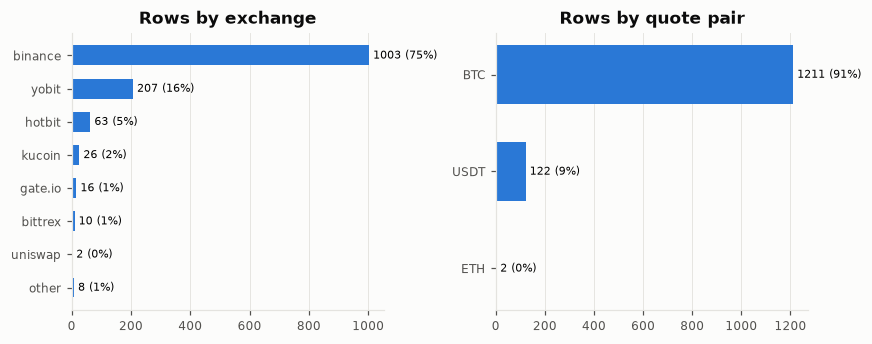

Binance hosts **75.1%** of rows and BTC is the quote of **90.7%** of rows, as stated in the brief (75 % and 91 %).

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
ex = log.exchange.value_counts()
top = ex.head(7)
other = pd.Series({"other": ex.iloc[7:].sum()}) if len(ex) > 7 else pd.Series(dtype=int)
ex_plot = pd.concat([top, other])
axes[0].barh(ex_plot.index[::-1], ex_plot.values[::-1], color=SERIES[0], height=0.6)
axes[0].set_title("Rows by exchange")
for y, v in enumerate(ex_plot.values[::-1]):
    axes[0].text(v, y, f" {v} ({v / len(log):.0%})", va="center", fontsize=7)
pr = log.pair.value_counts()
axes[1].barh(pr.index[::-1], pr.values[::-1], color=SERIES[0], height=0.6)
axes[1].set_title("Rows by quote pair")
for y, v in enumerate(pr.values[::-1]):
    axes[1].text(v, y, f" {v} ({v / len(log):.0%})", va="center", fontsize=7)
for a in axes:
    a.grid(axis="y", visible=False)
R.fig(fig, "exchange_pair")
close(fig)
R.table(pd.DataFrame({"rows": ex, "share": ex / len(log)}), "by_exchange")
md(f"Binance hosts **{ex.get('binance', 0) / len(log):.1%}** of rows and BTC is the quote of "
   f"**{pr.get('BTC', 0) / len(log):.1%}** of rows, as stated in the brief (75 % and 91 %).")

### 2. Time: month, weekday, UTC hour

**Uniformity tests.** For a categorical variable with $K$ classes, observed counts $O_k$ and expected counts
$E_k=n/K$ under $H_0$: "every class is equally likely", Pearson's statistic is
$$\chi^2=\sum_{k=1}^{K}\frac{(O_k-E_k)^2}{E_k}\ \overset{H_0}{\sim}\ \chi^2_{K-1}.$$
The effect size is Cramér's $V=\sqrt{\chi^2/(n(K-1))}$. The test assumes independent rows; relayed announcements of
the same pump violate it, so we also run it on de-duplicated events (one row per coin, exchange, hour).

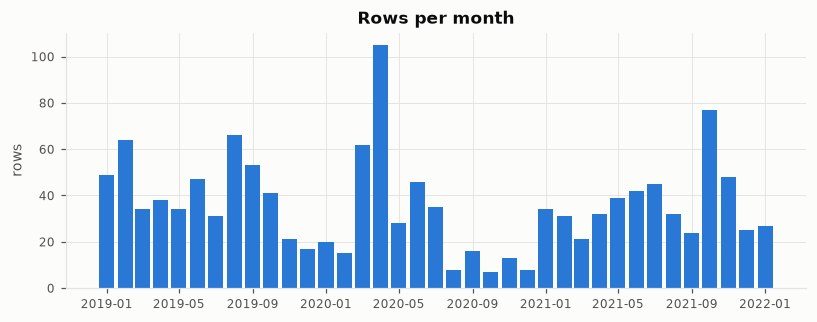

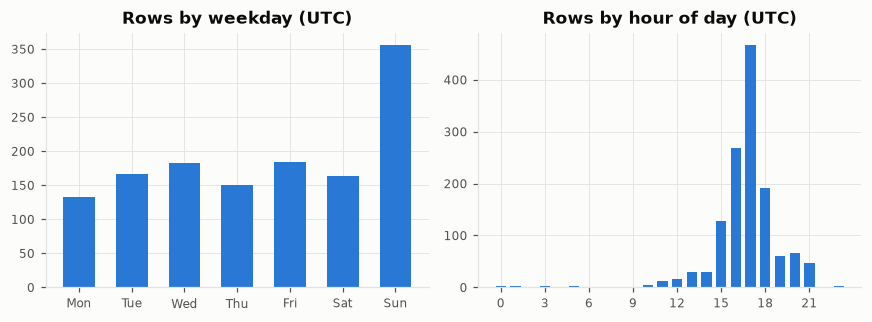

,unit,variable,n,K,chi2,df,p,Cramer V
0,rows,weekday,1335,7,177.3,6,1.245e-35,0.1488
1,rows,hour,1335,24,5055,23,0,0.4058
2,events,weekday,730,7,34.82,6,4.666e-06,0.08916
3,events,hour,730,24,2336,23,0,0.373


- weekday (rows): $\chi^2(6)=177.3,\ p=1.25\times10^{-35}$, $V=0.15$ → reject $H_0$ at $\alpha=0.05$.

- hour (rows): $\chi^2(23)=5055.3,\ p<10^{-300}$, $V=0.41$ → reject $H_0$ at $\alpha=0.05$.

- weekday (events): $\chi^2(6)=34.8,\ p=4.67\times10^{-6}$, $V=0.09$ → reject $H_0$ at $\alpha=0.05$.

- hour (events): $\chi^2(23)=2335.6,\ p<10^{-300}$, $V=0.37$ → reject $H_0$ at $\alpha=0.05$.

The three busiest UTC hours are 17:00 (467 rows), 16:00 (269 rows), 18:00 (191 rows): pumps are scheduled on round hours chosen to suit a global audience, so the hour distribution is very far from uniform.

In [3]:
log["month"] = log.timestamp.dt.to_period("M").dt.to_timestamp()
log["weekday"] = log.timestamp.dt.day_name().str[:3]
log["hour"] = log.timestamp.dt.hour
events = log.assign(h=log.timestamp.dt.floor("h")).drop_duplicates(["coin", "exchange", "h"])
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7.5, 3))
m = log.groupby("month").size()
ax.bar(m.index, m.values, width=25, color=SERIES[0])
ax.set_title("Rows per month")
ax.set_ylabel("rows")
R.fig(fig, "by_month")
close(fig)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
wd = log.weekday.value_counts().reindex(order)
axes[0].bar(wd.index, wd.values, color=SERIES[0], width=0.6)
axes[0].set_title("Rows by weekday (UTC)")
hr = log.hour.value_counts().reindex(range(24), fill_value=0)
axes[1].bar(hr.index, hr.values, color=SERIES[0], width=0.7)
axes[1].set_title("Rows by hour of day (UTC)")
axes[1].set_xticks(range(0, 24, 3))
R.fig(fig, "weekday_hour")
close(fig)

rows = []
for name, df in (("rows", log), ("events", events)):
    for var, cats in (("weekday", order), ("hour", list(range(24)))):
        obs = df[var].value_counts().reindex(cats, fill_value=0).values
        chi2, p = st.chisquare(obs)
        rows.append({"unit": name, "variable": var, "n": obs.sum(), "K": len(cats), "chi2": chi2, "df": len(cats) - 1,
                     "p": p, "Cramer V": np.sqrt(chi2 / (obs.sum() * (len(cats) - 1)))})
chi = pd.DataFrame(rows)
R.table(chi, "chi2_uniformity", index=False)
show(chi)
for r in chi.itertuples():
    md(f"- {r.variable} ({r.unit}): $\\chi^2({r.df})={r.chi2:.1f},\\ {S.fmt_p(r.p)}$, $V={r._8:.2f}$ → {S.decision(r.p)}.")
top_hours = hr.sort_values(ascending=False).head(3)
md(f"The three busiest UTC hours are {', '.join(f'{h}:00 ({v} rows)' for h, v in top_hours.items())}: pumps are "
   "scheduled on round hours chosen to suit a global audience, so the hour distribution is very far from uniform.")

### 3. Pumps per channel and per coin

**Concentration.** For counts $x_{(1)}\le\dots\le x_{(n)}$ the Lorenz curve is
$L(k/n)=\sum_{i\le k}x_{(i)}/\sum_i x_i$ and the Gini coefficient
$$G=\frac{\sum_{i=1}^{n}(2i-n-1)\,x_{(i)}}{n\sum_i x_i}\in[0,1),$$
with $G=0$ for equal counts.

,units,mean,median,max,Gini,share of rows from top 10%
channels,108,12.36,6,95,0.5701,0.4037
coins,277,4.819,1,40,0.6146,0.4667


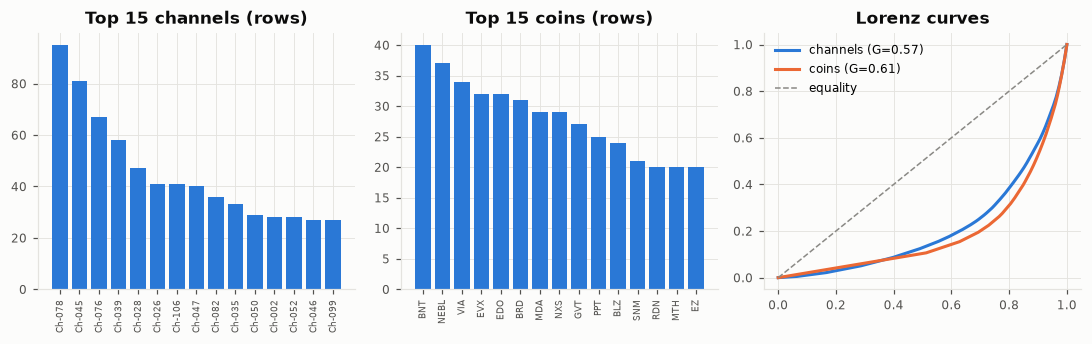

48.7% of coins appear more than once; channels are strongly concentrated ($G_{channels}=0.57$) and so are coins ($G_{coins}=0.61$). Repeated targets are the regularity that sequence models exploit.

In [4]:
per_channel = log.channel.value_counts()
per_coin = log.coin.value_counts()
conc = pd.DataFrame({
    "units": [len(per_channel), len(per_coin)], "mean": [per_channel.mean(), per_coin.mean()],
    "median": [per_channel.median(), per_coin.median()], "max": [per_channel.max(), per_coin.max()],
    "Gini": [S.gini(per_channel), S.gini(per_coin)],
    "share of rows from top 10%": [per_channel.head(max(1, len(per_channel) // 10)).sum() / len(log),
                                   per_coin.head(max(1, len(per_coin) // 10)).sum() / len(log)],
}, index=["channels", "coins"])
R.table(conc, "concentration")
show(conc)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].bar(range(15), per_channel.head(15).values, color=SERIES[0])
axes[0].set_xticks(range(15), per_channel.head(15).index, rotation=90, fontsize=6)
axes[0].set_title("Top 15 channels (rows)")
axes[1].bar(range(15), per_coin.head(15).values, color=SERIES[0])
axes[1].set_xticks(range(15), per_coin.head(15).index, rotation=90, fontsize=6)
axes[1].set_title("Top 15 coins (rows)")
for s, lab, c in ((per_channel, "channels", SERIES[0]), (per_coin, "coins", SERIES[1])):
    x = np.sort(s.values)
    L = np.concatenate([[0], np.cumsum(x) / x.sum()])
    axes[2].plot(np.linspace(0, 1, len(L)), L, label=f"{lab} (G={S.gini(x):.2f})", color=c)
axes[2].plot([0, 1], [0, 1], color="#8a8985", lw=1, ls="--", label="equality")
axes[2].set_title("Lorenz curves")
axes[2].legend()
R.fig(fig, "concentration")
close(fig)
repump = (per_coin > 1).mean()
md(f"{repump:.1%} of coins appear more than once; channels are strongly concentrated "
   f"($G_{{channels}}={S.gini(per_channel):.2f}$) and so are coins ($G_{{coins}}={S.gini(per_coin):.2f}$). "
   "Repeated targets are the regularity that sequence models exploit.")

### 4. Capitalisation of targets versus listed coins

Let $X$ be the log market capitalisation (USD) of a pump target three days before the pump and $Y$ that of a coin
listed on Binance at the same dates (the authors' candidate coins). With empirical CDFs $F_n$ and $G_m$, the
two-sample Kolmogorov–Smirnov statistic is
$$D_{n,m}=\sup_x\,|F_n(x)-G_m(x)|,$$
and under $H_0: F=G$ (continuous), $\sqrt{nm/(n+m)}\,D_{n,m}$ converges to the Kolmogorov distribution. We
complement it with the Mann–Whitney $U$ test ($H_0$: $P(X>Y)=1/2$, effect size $\hat\theta=U/(nm)$) and the
Anderson–Darling $k$-sample test, which is more sensitive in the tails.

A pooled comparison mixes dates; we therefore also compute, per event, the **percentile of the target inside its
own candidate set**, $u_i=\hat G_{i}(x_i)$. Under $H_0$ "targets are drawn like any listed coin", $u_i\sim U(0,1)$,
which a one-sample KS test checks.

In [5]:
gk = coingecko.load_all()
tg = gk[gk.source == "targets"].dropna(subset=["market_cap_usd"])
cd = gk[gk.source == "candidates"].dropna(subset=["market_cap_usd"])
x = np.log10(tg.market_cap_usd.values)
y = np.log10(cd.market_cap_usd.values)
ks = st.ks_2samp(x, y)
mw = st.mannwhitneyu(x, y, alternative="two-sided")
ad = st.anderson_ksamp([x, y])
tests = pd.DataFrame({"statistic": [ks.statistic, mw.statistic / (len(x) * len(y)), ad.statistic],
                      "p": [ks.pvalue, mw.pvalue, ad.pvalue]},
                     index=["KS D", "Mann-Whitney theta=U/(nm)", "Anderson-Darling"])
R.table(tests, "mcap_tests")
show(tests)
md(f"Targets: $n={len(x)}$, median capitalisation **USD {10 ** np.median(x) / 1e6:.1f}M**; listed coins: $m={len(y)}$, "
   f"median **USD {10 ** np.median(y) / 1e6:.1f}M**.\n\n"
   f"KS: $D={ks.statistic:.3f},\\ {S.fmt_p(ks.pvalue)}$ → {S.decision(ks.pvalue)}. Mann–Whitney: "
   f"$\\hat\\theta=P(X>Y)={mw.statistic / (len(x) * len(y)):.3f},\\ {S.fmt_p(mw.pvalue)}$. "
   f"Anderson–Darling: $A^2={ad.statistic:.1f}$ (scipy caps its p-value at 0.001: $p\\le{ad.pvalue:.3f}$).")

,statistic,p
KS D,0.4237,1.854e-87
Mann-Whitney theta=U/(nm),0.255,1.392e-85
Anderson-Darling,256.7,0.001


Targets: $n=538$, median capitalisation **USD 14.2M**; listed coins: $m=63784$, median **USD 67.1M**.

KS: $D=0.424,\ p=1.85\times10^{-87}$ → reject $H_0$ at $\alpha=0.05$. Mann–Whitney: $\hat\theta=P(X>Y)=0.255,\ p=1.39\times10^{-85}$. Anderson–Darling: $A^2=256.7$ (scipy caps its p-value at 0.001: $p\le0.001$).

Per-event percentile of the target among same-date listed coins ($N=447$): quartiles 0.09 / 0.23 / 0.41; one-sample KS against $U(0,1)$: $D=0.345,\ p=4.59\times10^{-48}$ → reject $H_0$ at $\alpha=0.05$.

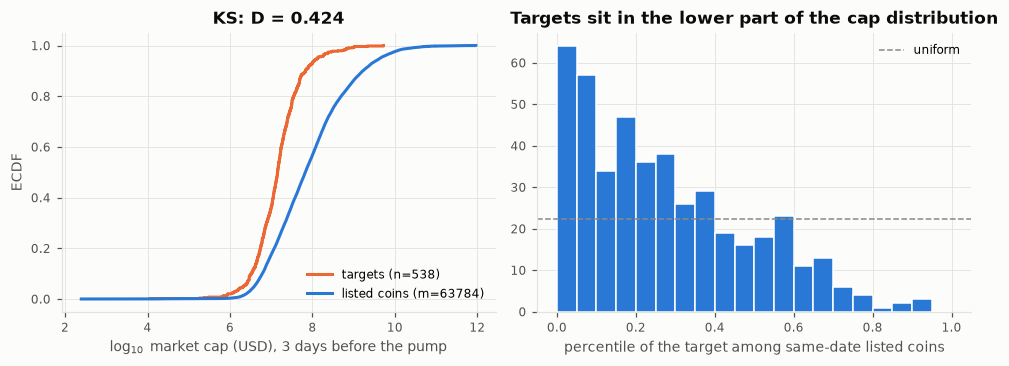

In [6]:
pct = []
for (coin, date), g in tg.groupby(["coin", "pump_date"]):
    pool = cd[cd.pump_date == date].market_cap_usd.values
    if len(pool) >= 20:
        pct.append((pool < g.market_cap_usd.iloc[0]).mean())
pct = np.array(pct)
ks1 = st.kstest(pct, "uniform")
q = np.quantile(pct, [0.25, 0.5, 0.75])
md(f"Per-event percentile of the target among same-date listed coins ($N={len(pct)}$): quartiles "
   f"{q[0]:.2f} / {q[1]:.2f} / {q[2]:.2f}; one-sample KS against $U(0,1)$: $D={ks1.statistic:.3f},\\ {S.fmt_p(ks1.pvalue)}$ "
   f"→ {S.decision(ks1.pvalue)}.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for v, lab, c in ((x, f"targets (n={len(x)})", SERIES[1]), (y, f"listed coins (m={len(y)})", SERIES[0])):
    s = np.sort(v)
    axes[0].step(s, np.arange(1, len(s) + 1) / len(s), where="post", label=lab, color=c)
axes[0].set_xlabel(r"$\log_{10}$ market cap (USD), 3 days before the pump")
axes[0].set_ylabel("ECDF")
axes[0].set_title(f"KS: D = {ks.statistic:.3f}")
axes[0].legend(loc="lower right")
axes[1].hist(pct, bins=20, range=(0, 1), color=SERIES[0], edgecolor="white")
axes[1].axhline(len(pct) / 20, color="#8a8985", ls="--", lw=1, label="uniform")
axes[1].set_xlabel("percentile of the target among same-date listed coins")
axes[1].set_title("Targets sit in the lower part of the cap distribution")
axes[1].legend()
R.fig(fig, "mcap_ecdf")
close(fig)

### 5. Interpretation

* **Platforms and pairs.** Activity is concentrated on Binance and on BTC pairs, the exchange with the deepest
  liquidity and the quote currency the organisers' members already hold.
* **Timing.** Pumps are scheduled, not random: the hour-of-day distribution is extremely concentrated on a few
  round UTC hours (17:00 UTC alone carries about a third of the rows), and the weekday distribution is uneven
  too: Sunday carries about twice the rows of any other day. The $\chi^2$ tests reject uniformity on rows and on
  de-duplicated events, although the weekday effect size is small ($V<0.15$) while the hour effect is large.
* **Concentration.** A small number of channels produces most of the rows and many coins are pumped repeatedly —
  the paper reports a 60.1 % re-pump probability.
* **Capitalisation.** Target and listed-coin capitalisations differ significantly: the median target is about
  five times smaller than the median listed coin, and $P(X>Y)\approx0.26$. The per-event percentiles show *where*:
  targets lie mostly between the 10th and the 40th percentile of the coins listed on the same day. They avoid
  the large caps (too expensive to move) without concentrating on the very smallest coins (too illiquid to exit):
  the "small-to-mid cap" preference discussed in I.1. Note that "listed coins" here are the coins listed on
  **Binance**, an exchange that already excludes the micro-caps of the wider market.

**Limitations.** CoinGecko capitalisation is missing for some coins (see I.0); the pooled tests treat rows as
independent although relayed announcements of one pump are not, which the event-level and per-event analyses
address.

## I.3 — Event study of the pre-pump period

**Objective (brief I.3).** On Binance pumps quoted in BTC, with hourly data:
1. estimate a market model on $[\tau-30\,\text{d},\ \tau-72\,\text{h}]$ and compute abnormal returns (AR) and
   cumulative abnormal returns (CAR);
2. test $H_0:\ \mathbb E[\mathrm{CAR}(\tau-x\,\text{h},\tau-1\,\text{h})]=0$ for $x\in\{6,12,24,48,60,72\}$ with a
   Student test and a Wilcoxon test, and compare with the 9.5 % mean pre-pump return reported by [A1] for $x=60$;
3. study abnormal volume through $z^V_{c,t}=(\log V_{c,t}-\hat\mu_c)/\hat\sigma_c$;
4. describe minute by minute the anatomy of 20 pumps (maximum gain, time to peak, dump half-life).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore", category=RuntimeWarning)
settings.seed_everything()
R = Reporter("I3_event_study")
XS = [6, 12, 24, 48, 60, 72]

### 1. Events and data

Relayed announcements of the same pump are merged: an **event** is a (coin, hour) pair and its time $\tau$ is the
earliest announcement among the channels, as in [A1] §4.2. Prices are Binance hourly bars in BTC (close price,
bars indexed by their opening time).

**Information horizon.** Let $t^\star$ be the opening time of the last hourly bar that closes before $\tau-1\,$h. The
window "$\tau-(x+1)\,$h to $\tau-1\,$h" of [A1] is the $x$ bars ending at $t^\star$, and the return over it is
$R^{(x)}_c=\log P_{c,t^\star}-\log P_{c,t^\star-x}=\sum_{s=t^\star-x+1}^{t^\star} r_{c,s}$.

In [2]:
ev_all = pd_log.binance_btc_events()
ev = (ev_all.assign(h=ev_all.timestamp.dt.floor("h")).sort_values("timestamp")
      .drop_duplicates(["symbol", "h"]).reset_index(drop=True))
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]
qv = panels["quote_volume"]
r = np.log(close_).diff()
alts = [c for c in r.columns if c.endswith("BTC")]
n_alt = r[alts].notna().sum(axis=1)
sum_alt = r[alts].sum(axis=1)
md(f"{len(ev_all)} Binance/BTC rows → **{len(ev)} events** after merging relayed announcements "
   f"(paper: 445 Binance/BTC events in its pre-pump analysis).")

981 Binance/BTC rows → **457 events** after merging relayed announcements (paper: 445 Binance/BTC events in its pre-pump analysis).

### 2. Market model

**Market return.** The coins are quoted in BTC, so the relevant market is the BTC-denominated altcoin market. We use
the equal-weighted return of all universe coins trading at hour $t$, **excluding the target**:
$$r_{m,t}^{(-c)}=\frac{1}{N_t-1}\Big(\sum_{j\in\mathcal U_t}r_{j,t}-r_{c,t}\Big).$$

**Model.** For each event we fit by OLS on the estimation window $E=[\tau-30\,\text{d},\ \tau-72\,\text{h}]$
$$r_{c,t}=\alpha_c+\beta_c\,r_{m,t}+\varepsilon_{c,t},\qquad \varepsilon_{c,t}\sim(0,\sigma_c^2),$$
then define for $t$ outside $E$
$$AR_{c,t}=r_{c,t}-\hat\alpha_c-\hat\beta_c r_{m,t},\qquad \mathrm{CAR}_c(t_1,t_2)=\sum_{t=t_1}^{t_2}AR_{c,t}.$$
The 72-hour gap between $E$ and $\tau$ keeps the pre-pump accumulation (up to ~60 h according to [A1]) out of the
estimation. Events with fewer than 300 valid hours in $E$ are dropped.

**Robustness.** (a) *market-adjusted* returns $AR=r_c-r_m$ (i.e. $\alpha=0,\beta=1$); (b) a USD version where the
coin's USD return $r_c+r_{BTC/USDT}$ is regressed on $r_{BTC/USDT}$.

In [3]:
K_PRE, K_POST = 72, 6
rows, paths, vpaths = [], [], []
btc = r["BTCUSDT"]
for e in ev.itertuples():
    s = e.symbol
    if s not in r.columns:
        continue
    t_star = universe.last_bar_before(e.timestamp)
    if t_star not in r.index:
        continue
    i_star = r.index.get_loc(t_star)
    est = slice(i_star + 1 - 30 * 24, i_star + 1 - K_PRE)        # [tau-30d, tau-72h] in bar positions
    rc = r[s].values
    rm = ((sum_alt - r[s].fillna(0)) / (n_alt - r[s].notna().astype(int))).values
    y, x = rc[est], rm[est]
    ok = np.isfinite(y) & np.isfinite(x)
    if ok.sum() < 300:
        continue
    beta, alpha = np.polyfit(x[ok], y[ok], 1)
    resid = y[ok] - alpha - beta * x[ok]
    sigma = resid.std(ddof=2)
    win = slice(i_star + 1 - K_PRE, i_star + 1 + K_POST + 1)      # bars t*-71 .. t*+7 (event time -72..+6)
    ar = rc[win] - alpha - beta * rm[win]
    ar_ma = rc[win] - rm[win]
    yu, xu = (rc + btc.values)[est], btc.values[est]
    oku = np.isfinite(yu) & np.isfinite(xu)
    bu, au = np.polyfit(xu[oku], yu[oku], 1)
    ar_usd = (rc + btc.values)[win] - au - bu * btc.values[win]
    lv = np.log1p(qv[s].values)
    mu_v, sd_v = np.nanmean(lv[est]), np.nanstd(lv[est], ddof=1)
    zv = (lv[win] - mu_v) / sd_v
    rec = {"event_id": e.event_id, "symbol": s, "tau": e.timestamp, "alpha": alpha, "beta": beta, "sigma": sigma,
           "n_est": int(ok.sum())}
    pre = ar[:K_PRE]                              # positions 0..71 = bars t*-71 .. t*
    for xh in XS:
        seg = slice(K_PRE - xh, K_PRE)
        rec[f"CAR_{xh}"] = np.nansum(pre[seg]) if np.isfinite(pre[seg]).sum() >= 0.8 * xh else np.nan
        rec[f"CARma_{xh}"] = np.nansum(ar_ma[:K_PRE][seg]) if np.isfinite(ar_ma[:K_PRE][seg]).sum() >= 0.8 * xh else np.nan
        rec[f"CARusd_{xh}"] = np.nansum(ar_usd[:K_PRE][seg]) if np.isfinite(ar_usd[:K_PRE][seg]).sum() >= 0.8 * xh else np.nan
        raw = np.log(close_[s].iloc[i_star]) - np.log(close_[s].iloc[i_star - xh])
        rec[f"RAW_{xh}"] = raw
        rec[f"SCAR_{xh}"] = rec[f"CAR_{xh}"] / (sigma * np.sqrt(xh))
        rec[f"ZV_{xh}"] = np.nanmean(zv[:K_PRE][seg])
    rows.append(rec)
    paths.append(ar)
    vpaths.append(zv)
es = pd.DataFrame(rows)
AR = np.vstack(paths)
ZV = np.vstack(vpaths)
k_axis = np.arange(-K_PRE + 1, K_POST + 2)      # bar position relative to t* (0 = last bar before tau-1h)
R.table(es.drop(columns=["tau"]), "event_level_car", index=False)
md(f"Events with a valid estimation window: **N = {len(es)}**. Median $\\hat\\beta={es.beta.median():.2f}$ "
   f"(IQR {es.beta.quantile(.25):.2f}–{es.beta.quantile(.75):.2f}); median $\\hat\\sigma={es.sigma.median():.4f}$ per hour.")

Events with a valid estimation window: **N = 427**. Median $\hat\beta=0.88$ (IQR 0.71–1.06); median $\hat\sigma=0.0130$ per hour.

### 3. Tests on $\mathbb E[\mathrm{CAR}(\tau-x\,\text{h},\tau-1\,\text{h})]$

For each $x$, with $N$ events and $\overline{\mathrm{CAR}}=\frac1N\sum_i\mathrm{CAR}_i$:

* **Student test** — $T=\overline{\mathrm{CAR}}\big/\big(s_{\mathrm{CAR}}/\sqrt N\big)\overset{H_0}{\sim}t_{N-1}$
  (exact under normality, asymptotically valid by the CLT if the variance is finite);
* **Wilcoxon signed-rank test** — $W^+=\sum_i R_i\,\mathbf 1\{\mathrm{CAR}_i>0\}$ where $R_i$ is the rank of
  $|\mathrm{CAR}_i|$; it tests the symmetry of the distribution about 0 (median 0) and is robust to heavy tails;
* **BMP test** (Boehmer–Musumeci–Poulsen) — standardised $\mathrm{SCAR}_i=\mathrm{CAR}_i/(\hat\sigma_i\sqrt x)$ and
  $T_{BMP}=\overline{\mathrm{SCAR}}/(s_{\mathrm{SCAR}}/\sqrt N)$, which down-weights very volatile coins and is robust
  to event-induced variance;
* **Shapiro–Wilk** — $H_0$: CARs are Gaussian; a rejection motivates relying on the Wilcoxon and bootstrap results;
* a 95 % **percentile bootstrap** interval for $\mathbb E[\mathrm{CAR}]$ (5 000 resamples).

The six horizons are tested simultaneously, so p-values are adjusted with **Holm**'s step-down procedure
(family-wise error rate $\le\alpha$).

In [4]:
res = []
for xh in XS:
    c = es[f"CAR_{xh}"].dropna().values
    sc = es[f"SCAR_{xh}"].dropna().values
    t = st.ttest_1samp(c, 0.0)
    w = st.wilcoxon(c)
    b = st.ttest_1samp(sc, 0.0)
    sw = st.shapiro(c[:5000])
    lo, hi = S.bootstrap_ci(c, seed=xh)
    res.append({"x (h)": xh, "N": len(c), "mean CAR": c.mean(), "median CAR": np.median(c), "share > 0": (c > 0).mean(),
                "t": t.statistic, "p_t": t.pvalue, "W": w.statistic, "p_W": w.pvalue, "T_BMP": b.statistic,
                "p_BMP": b.pvalue, "Shapiro W": sw.statistic, "p_SW": sw.pvalue, "CI low": lo, "CI high": hi})
tab = pd.DataFrame(res)
for col in ("p_t", "p_W", "p_BMP"):
    tab[col + " (Holm)"] = S.holm(tab[col])
R.table(tab, "car_tests", index=False)
show(tab.set_index("x (h)"))

lines = []
for _, rw in tab.iterrows():
    lines.append(f"- $x={rw['x (h)']:.0f}$: $\\overline{{\\mathrm{{CAR}}}}$ = {rw['mean CAR']:.2%} "
                 f"(95 % CI [{rw['CI low']:.2%}, {rw['CI high']:.2%}]), $t({rw['N'] - 1:.0f})={rw['t']:.2f}$, "
                 f"Holm ${S.fmt_p(rw['p_t (Holm)'])}$; Wilcoxon ${S.fmt_p(rw['p_W (Holm)'])}$ (Holm); "
                 f"BMP $T={rw['T_BMP']:.2f}$, ${S.fmt_p(rw['p_BMP (Holm)'])}$ (Holm); Shapiro–Wilk ${S.fmt_p(rw['p_SW'])}$.")
md("\n".join(lines))

,N,mean CAR,median CAR,share > 0,t,p_t,W,p_W,T_BMP,p_BMP,Shapiro W,p_SW,CI low,CI high,p_t (Holm),p_W (Holm),p_BMP (Holm)
x (h),,,,,,,,,,,,,,,,,
6,425,0.02471,0.01335,0.6847,9.831,1.109e-20,1.991e+04,1.417e-23,10.47,5.521e-23,0.8048,2.81e-22,0.01985,0.0297,4.436e-20,5.667e-23,1.104e-22
12,420,0.02982,0.0152,0.6881,9.677,4.006e-20,1.959e+04,4.62e-23,10.58,2.325e-23,0.8452,6.952e-20,0.02385,0.03579,1.202e-19,9.241e-23,6.975e-23
24,424,0.03618,0.02242,0.7028,10.71,7.72e-24,1.839e+04,4.68e-26,11.63,2.679e-27,0.886,3.487e-17,0.02967,0.04292,4.632e-23,2.34e-25,1.339e-26
48,424,0.05014,0.02731,0.7193,10.35,1.517e-22,1.83e+04,3.119e-26,11.85,3.487e-28,0.8071,3.941e-22,0.04111,0.0597,7.584e-22,1.872e-25,2.092e-27
60,427,0.05826,0.0343,0.6792,9.548,1.05e-19,2.02e+04,1.683e-23,11.11,2.255e-25,0.7628,2.401e-24,0.04658,0.07058,2.1e-19,5.667e-23,9.02e-25
72,427,0.05469,0.03178,0.6604,8.351,9.569e-16,2.441e+04,7.513e-17,9.287,8.217e-19,0.7678,4.035e-24,0.04294,0.06763,9.569e-16,7.513e-17,8.217e-19


- $x=6$: $\overline{\mathrm{CAR}}$ = 2.47% (95 % CI [1.99%, 2.97%]), $t(424)=9.83$, Holm $p=4.44\times10^{-20}$; Wilcoxon $p=5.67\times10^{-23}$ (Holm); BMP $T=10.47$, $p=1.10\times10^{-22}$ (Holm); Shapiro–Wilk $p=2.81\times10^{-22}$.
- $x=12$: $\overline{\mathrm{CAR}}$ = 2.98% (95 % CI [2.39%, 3.58%]), $t(419)=9.68$, Holm $p=1.20\times10^{-19}$; Wilcoxon $p=9.24\times10^{-23}$ (Holm); BMP $T=10.58$, $p=6.98\times10^{-23}$ (Holm); Shapiro–Wilk $p=6.95\times10^{-20}$.
- $x=24$: $\overline{\mathrm{CAR}}$ = 3.62% (95 % CI [2.97%, 4.29%]), $t(423)=10.71$, Holm $p=4.63\times10^{-23}$; Wilcoxon $p=2.34\times10^{-25}$ (Holm); BMP $T=11.63$, $p=1.34\times10^{-26}$ (Holm); Shapiro–Wilk $p=3.49\times10^{-17}$.
- $x=48$: $\overline{\mathrm{CAR}}$ = 5.01% (95 % CI [4.11%, 5.97%]), $t(423)=10.35$, Holm $p=7.58\times10^{-22}$; Wilcoxon $p=1.87\times10^{-25}$ (Holm); BMP $T=11.85$, $p=2.09\times10^{-27}$ (Holm); Shapiro–Wilk $p=3.94\times10^{-22}$.
- $x=60$: $\overline{\mathrm{CAR}}$ = 5.83% (95 % CI [4.66%, 7.06%]), $t(426)=9.55$, Holm $p=2.10\times10^{-19}$; Wilcoxon $p=5.67\times10^{-23}$ (Holm); BMP $T=11.11$, $p=9.02\times10^{-25}$ (Holm); Shapiro–Wilk $p=2.40\times10^{-24}$.
- $x=72$: $\overline{\mathrm{CAR}}$ = 5.47% (95 % CI [4.29%, 6.76%]), $t(426)=8.35$, Holm $p=9.57\times10^{-16}$; Wilcoxon $p=7.51\times10^{-17}$ (Holm); BMP $T=9.29$, $p=8.22\times10^{-19}$ (Holm); Shapiro–Wilk $p=4.04\times10^{-24}$.

#### Comparison with [A1]: the 9.5 % pre-pump return at $x=60$

[A1] reports the **raw** average return over the window (not an abnormal return), computed on minute mid-prices.
We report the raw return $\exp(R^{(60)})-1$, its abnormal counterpart and the robustness variants.

In [5]:
raw60 = np.expm1(es["RAW_60"].dropna())
car60 = np.expm1(es["CAR_60"].dropna())
comp = pd.DataFrame({
    "mean": [raw60.mean(), car60.mean(), np.expm1(es["CARma_60"].dropna()).mean(), np.expm1(es["CARusd_60"].dropna()).mean()],
    "median": [raw60.median(), car60.median(), np.expm1(es["CARma_60"].dropna()).median(), np.expm1(es["CARusd_60"].dropna()).median()],
    "trimmed mean (5%)": [st.trim_mean(raw60, 0.05), st.trim_mean(car60, 0.05),
                          st.trim_mean(np.expm1(es["CARma_60"].dropna()), 0.05), st.trim_mean(np.expm1(es["CARusd_60"].dropna()), 0.05)],
}, index=["raw return (as [A1])", "CAR, market model", "CAR, market-adjusted", "CAR, USD market model"])
R.table(comp, "x60_vs_paper")
show(comp, "{:.4f}")
t95 = st.ttest_1samp(raw60, 0.095)
md(f"Raw mean return at $x=60$: **{raw60.mean():.2%}** vs **9.5 %** in [A1]. Test of $H_0:\\ \\mathbb E[R]=9.5\\%$: "
   f"$t({len(raw60) - 1})={t95.statistic:.2f},\\ {S.fmt_p(t95.pvalue)}$ → {S.decision(t95.pvalue)}.")

,mean,median,trimmed mean (5%)
raw return (as [A1]),0.0639,0.0318,0.0437
"CAR, market model",0.0700,0.0349,0.0504
"CAR, market-adjusted",0.0660,0.0259,0.0450
"CAR, USD market model",0.0684,0.0390,0.0517


Raw mean return at $x=60$: **6.39%** vs **9.5 %** in [A1]. Test of $H_0:\ \mathbb E[R]=9.5\%$: $t(425)=-3.15,\ p=0.002$ → reject $H_0$ at $\alpha=0.05$.

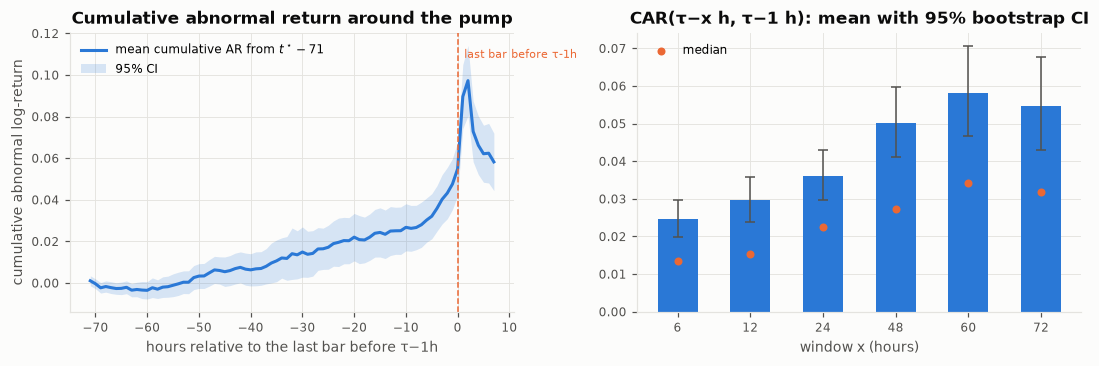

In [6]:
mean_car = np.nancumsum(np.nanmean(AR[:, :K_PRE], axis=0)[::-1])[::-1]
cum = np.nancumsum(AR, axis=1)
cum = cum - cum[:, [0]] + AR[:, [0]]
m = np.nanmean(cum, axis=0)
se = np.nanstd(cum, axis=0, ddof=1) / np.sqrt(np.isfinite(cum).sum(axis=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(k_axis, m, color=SERIES[0], label="mean cumulative AR from $t^\\star-71$")
axes[0].fill_between(k_axis, m - 1.96 * se, m + 1.96 * se, color=SERIES[0], alpha=0.18, lw=0, label="95% CI")
axes[0].axvline(0, color=SERIES[1], ls="--", lw=1)
axes[0].text(0.5, axes[0].get_ylim()[1] * 0.9, " last bar before τ-1h", fontsize=7, color=SERIES[1])
axes[0].set_xlabel("hours relative to the last bar before τ−1h")
axes[0].set_ylabel("cumulative abnormal log-return")
axes[0].set_title("Cumulative abnormal return around the pump")
axes[0].legend(loc="upper left")
axes[1].bar([str(x) for x in XS], tab["mean CAR"], color=SERIES[0], width=0.55)
axes[1].errorbar(range(len(XS)), tab["mean CAR"], yerr=[tab["mean CAR"] - tab["CI low"], tab["CI high"] - tab["mean CAR"]],
                 fmt="none", ecolor="#52514e", capsize=3, lw=1)
axes[1].scatter(range(len(XS)), tab["median CAR"], color=SERIES[1], zorder=3, s=18, label="median")
axes[1].set_xlabel("window x (hours)")
axes[1].set_title("CAR(τ−x h, τ−1 h): mean with 95% bootstrap CI")
axes[1].legend()
R.fig(fig, "car")
close(fig)

### 4. Abnormal volume

With $V_{c,t}$ the hourly quote volume (BTC) and $\hat\mu_c,\hat\sigma_c$ the mean and standard deviation of
$\log(1+V_{c,t})$ on the estimation window,
$$z^V_{c,t}=\frac{\log(1+V_{c,t})-\hat\mu_c}{\hat\sigma_c}.$$
Under "no abnormal activity", $z^V$ has mean 0 and unit variance; we test $H_0:\mathbb E[\bar z^V_{(x)}]=0$ where
$\bar z^V_{(x)}$ is the mean of $z^V$ over the window of $x$ hours.

,N,mean z,median z,t,p_t,p_W,p_t (Holm),p_W (Holm)
x (h),,,,,,,,
6,426,0.5025,0.227,9.272,9.29e-19,2.058e-14,5.574e-18,1.235e-13
12,427,0.2585,0.09271,6.197,1.357e-09,4.577e-05,6.787e-09,0.0002288
24,427,0.1356,-0.0001975,3.75,0.0002013,0.2854,0.0008053,0.8561
48,427,0.06243,-0.06371,2.064,0.03961,0.51,0.1188,0.897
60,427,0.05155,-0.08398,1.823,0.06897,0.4485,0.1379,0.897
72,427,0.03165,-0.0741,1.198,0.2314,0.1766,0.2314,0.7064


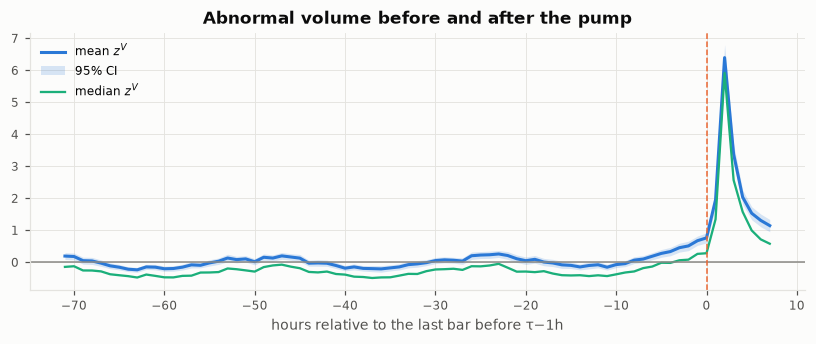

Mean $z^V$ is -0.03 on average between 72 and 48 hours before $t^\star$, 0.50 over the last 6 bars before $t^\star$, and 2.6 once the pump starts. Across windows, abnormal volume is significant (Holm, Student) for $x\le$ 24 h only: the volume build-up is concentrated in the last hours, whereas the price drift spans days.

In [7]:
zres = []
for xh in XS:
    z = es[f"ZV_{xh}"].dropna().values
    t = st.ttest_1samp(z, 0.0)
    w = st.wilcoxon(z)
    zres.append({"x (h)": xh, "N": len(z), "mean z": z.mean(), "median z": np.median(z), "t": t.statistic, "p_t": t.pvalue,
                 "p_W": w.pvalue})
ztab = pd.DataFrame(zres)
ztab["p_t (Holm)"] = S.holm(ztab.p_t)
ztab["p_W (Holm)"] = S.holm(ztab.p_W)
R.table(ztab, "volume_tests", index=False)
show(ztab.set_index("x (h)"))
zm = np.nanmean(ZV, axis=0)
zse = np.nanstd(ZV, axis=0, ddof=1) / np.sqrt(np.isfinite(ZV).sum(axis=0))
zmed = np.nanmedian(ZV, axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(k_axis, zm, color=SERIES[0], label="mean $z^V$")
ax.fill_between(k_axis, zm - 1.96 * zse, zm + 1.96 * zse, color=SERIES[0], alpha=0.18, lw=0, label="95% CI")
ax.plot(k_axis, zmed, color=SERIES[2], lw=1.5, label="median $z^V$")
ax.axhline(0, color="#8a8985", lw=1)
ax.axvline(0, color=SERIES[1], ls="--", lw=1)
ax.set_xlabel("hours relative to the last bar before τ−1h")
ax.set_title("Abnormal volume before and after the pump")
ax.legend(loc="upper left")
R.fig(fig, "abnormal_volume")
close(fig)
early = zm[(k_axis >= -71) & (k_axis <= -48)].mean()
late = zm[(k_axis >= -5) & (k_axis <= 0)].mean()
post = zm[k_axis >= 2].mean()
md(f"Mean $z^V$ is {early:.2f} on average between 72 and 48 hours before $t^\\star$, {late:.2f} over the last 6 bars "
   f"before $t^\\star$, and {post:.1f} once the pump starts. Across windows, abnormal volume is significant (Holm, "
   f"Student) for $x\\le$ {int(ztab.loc[ztab['p_t (Holm)'] < 0.05, 'x (h)'].max())} h only: the volume build-up is "
   "concentrated in the last hours, whereas the price drift spans days.")

### 5. Minute anatomy of 20 pumps

For 20 events drawn at random (seeded) we download the Binance 1-minute bars. With $p_0$ the open of the minute
containing $\tau$, $H_s$ the high and $C_s$ the close of minute $s\ge0$ after $\tau$:

* **maximum gain** $G=\max_{0\le s\le 60}H_s/p_0-1$;
* **time to peak** $s^\star=\arg\max_{0\le s\le60}H_s$ (minutes);
* **dump half-life** $h_{1/2}=\min\{s>s^\star: C_s\le p_0+\tfrac12(H_{s^\star}-p_0)\}-s^\star$, the minutes needed
  to give back half of the gain (censored at 120 min).

,coin,date,max gain,time to peak (min),half-life (min),gain at +60 min
event,,,,,,
865,FXS,2021-09-19 17:00,0.898,1,5,0.352
241,ARK,2019-09-12 14:59,0.081,31,22,0.032
681,MDA,2021-02-10 21:00,2.822,0,1,-0.058
287,LRC,2019-11-16 05:01,0.011,0,1,-0.008
875,EZ,2021-10-03 17:00,0.404,0,1,-0.219
882,SKY,2021-10-05 15:00,0.363,8,2,0.001
967,OAX,2021-12-28 15:00,0.070,0,1,-0.252
848,SNX,2021-08-24 12:30,0.006,16,1,-0.016
766,DLT,2021-05-30 16:00,0.152,60,1,-0.031


,mean,50%,min,max
max gain,0.333,0.127,0.006,2.822
time to peak (min),7.750,1.000,0.000,60.000
half-life (min),3.600,1.000,1.000,22.000
gain at +60 min,-0.009,-0.010,-0.252,0.352


Over 20 pumps: median maximum gain **12.7%** (max 282%), median time to peak **1 min**, median dump half-life **1 min** (0 censored), and one hour later the median price is **-1.0%** relative to $p_0$.

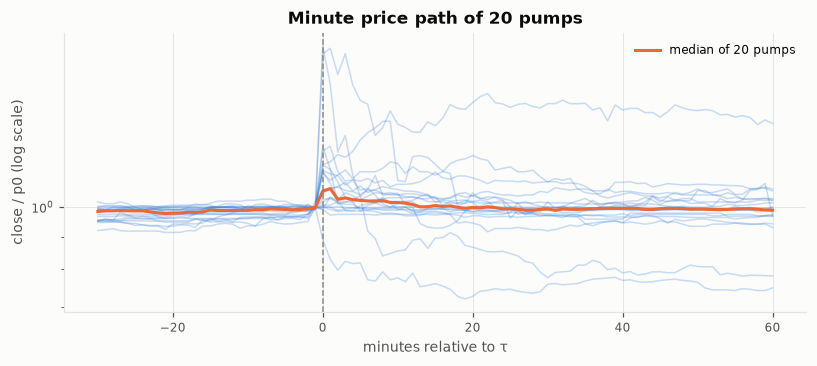

In [8]:
rng = np.random.default_rng(settings.SEED)
sample = ev[ev.symbol.isin(es.symbol)].iloc[rng.choice(len(ev[ev.symbol.isin(es.symbol)]), 20, replace=False)]
anat, curves = [], []
for e in sample.itertuples():
    k = binance.load_klines(e.symbol, "1m", e.timestamp - pd.Timedelta(hours=2), e.timestamp + pd.Timedelta(hours=3))
    if k.empty:
        continue
    t0 = e.timestamp.floor("min")
    if t0 not in k.index:
        continue
    i0 = k.index.get_loc(t0)
    p0 = k.open.iloc[i0]
    hi = k.high.iloc[i0:i0 + 61].values
    s_star = int(np.argmax(hi))
    peak = hi[s_star]
    after = k.close.iloc[i0 + s_star + 1:i0 + s_star + 121].values
    half = p0 + 0.5 * (peak - p0)
    hit = np.where(after <= half)[0]
    anat.append({"event": e.event_id, "coin": e.coin, "date": e.timestamp.strftime("%Y-%m-%d %H:%M"),
                 "max gain": peak / p0 - 1, "time to peak (min)": s_star,
                 "half-life (min)": (hit[0] + 1) if len(hit) else np.nan,
                 "gain at +60 min": k.close.iloc[min(i0 + 60, len(k) - 1)] / p0 - 1})
    seg = k.close.iloc[max(i0 - 30, 0):i0 + 61] / p0
    curves.append(pd.Series(seg.values, index=np.arange(len(seg)) - min(30, i0)))
anat = pd.DataFrame(anat)
R.table(anat, "anatomy_20_pumps", index=False)
show(anat.set_index("event"), "{:.3f}")
desc = anat[["max gain", "time to peak (min)", "half-life (min)", "gain at +60 min"]].describe().T[["mean", "50%", "min", "max"]]
show(desc, "{:.3f}")
md(f"Over {len(anat)} pumps: median maximum gain **{anat['max gain'].median():.1%}** (max {anat['max gain'].max():.0%}), "
   f"median time to peak **{anat['time to peak (min)'].median():.0f} min**, median dump half-life "
   f"**{anat['half-life (min)'].median():.0f} min** ({anat['half-life (min)'].isna().sum()} censored), and one hour "
   f"later the median price is **{anat['gain at +60 min'].median():+.1%}** relative to $p_0$.")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for c in curves:
    ax.plot(c.index, c.values, color=SERIES[0], alpha=0.25, lw=1)
med = pd.concat(curves, axis=1).median(axis=1)
ax.plot(med.index, med.values, color=SERIES[1], lw=2, label="median of 20 pumps")
ax.axvline(0, color="#8a8985", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("minutes relative to τ")
ax.set_ylabel("close / p0 (log scale)")
ax.set_title("Minute price path of 20 pumps")
ax.legend()
R.fig(fig, "anatomy")
close(fig)

### 6. Interpretation (QUICK run; this notebook has no QUICK/FULL difference)

* **A significant pre-pump drift exists at every horizon.** The mean CAR is positive and grows with the window:
  about 2.5 % over the last 6 hours, 3.6 % over 24 h and a maximum of about 5.8 % at $x=60$, before slightly
  decreasing at $x=72$. All three tests (Student, Wilcoxon, BMP) reject $H_0:\mathbb E[\mathrm{CAR}]=0$ at any
  conventional level after the Holm correction (p-values below $10^{-15}$). Two thirds or more of the events show
  a positive CAR, so the effect is not driven by a few outliers. The peak at $x=60$ matches the paper's statement
  that "buy-in behaviour starts within 60 hours" (§1, §4.2): extending the window to 72 h only adds noise.
* **The distribution is far from Gaussian** (Shapiro–Wilk p-values $<10^{-16}$, heavy right tail), so the
  Wilcoxon and bootstrap results are the reliable ones; they agree with the t-test.
* **Comparison with the 9.5 % of [A1].** Our raw mean return at $x=60$ is about 6.4 % (median 3.2 %), and
  $H_0:\mathbb E[R]=9.5\,\%$ is rejected ($p\approx0.002$). Plausible reasons: [A1] uses minute mid-prices and its own
  merging of 445 events, while we use hourly closes; and a mean of heavy-tailed returns is unstable, as the gap
  between the mean, the trimmed mean and the median shows. The qualitative finding, a significant positive drift
  that peaks around 60 hours, is reproduced.
* **The drift is not a market effect.** Market-model, market-adjusted and USD-denominated CARs are all within
  about one percentage point of the raw return: the BTC-quoted altcoin market does not explain the run-up.
* **Volume moves later than price.** Abnormal volume is significant only for windows of 24 hours or less and is
  strongest over the last 6 hours (mean $z^V\approx0.5$), while it is nil 48 to 72 hours before. The early
  price drift with normal volume is consistent with discreet accumulation by insiders (small orders spread over
  days), followed by a visible volume surge as the announcement approaches.
* **Anatomy.** The pump itself is extremely short. In the 20 sampled pumps the price peaks within one minute in
  most cases (median time to peak 1 min), half of the gain is lost within a minute or two (median half-life
  1 min), and one hour later the price is back near its starting level (median $-1\,\%$). Gains are very uneven:
  median 13 %, but up to 280 % (MDA, February 2021). Only participants who buy *before* the announcement can
  profit, which is the core argument of [A1] for predicting the target coin in advance.

**Limitations.** Hourly bars blur the last hour before $\tau$; overlapping event windows of different coins
share market shocks, so the cross-sectional tests are slightly optimistic. The minute anatomy sample is small
(20 pumps) and is descriptive only.

## I.4 — Intra-channel homogeneity of pump targets

**Objective (brief I.4).** [A1] (§4.3) observes that the coins pumped by one channel look alike (similar market
capitalisation, Alexa rank, Reddit audience) while different channels pick different kinds of coins. The paper shows
scatter plots but no statistic. We turn the observation into a test.

**Definitions.** For target $c$ (three days before the pump) let
$$\boldsymbol x_c=\big(\log \mathrm{mcap},\ \log \mathrm{price},\ \log \mathrm{volume},\ \log(1+\mathrm{twitter}),\
\log(1+\mathrm{reddit})\big)$$
with every component standardised across targets ($z$-score), so $\cos$ compares profiles relative to the average
target. For channel $h$ with $n_h\ge2$ targets $c_1,\dots,c_{n_h}$:
$$S_{\text{intra}}(h)=\binom{n_h}{2}^{-1}\sum_{i<j}\cos(\boldsymbol x_{c_i},\boldsymbol x_{c_j}),\qquad
\cos(\boldsymbol u,\boldsymbol v)=\frac{\boldsymbol u^\top\boldsymbol v}{\lVert\boldsymbol u\rVert\,\lVert\boldsymbol v\rVert},$$
and the overall statistic is the average over the $H$ eligible channels, $\bar S=\frac1H\sum_h S_{\text{intra}}(h)$.

**Permutation test.** $H_0$: the channel label carries no information about the target profile (labels are
exchangeable). Under $H_0$, permuting the labels across targets (keeping each channel's size) gives draws
$\bar S^{(b)}$, $b=1..B$, from the null distribution and
$$\hat p=\frac{1+\#\{b:\bar S^{(b)}\ge\bar S\}}{B+1}.$$
Adding one to numerator and denominator counts the observed labelling as one of the permutations, which makes the
test exact (size $\le\alpha$) and never returns $\hat p=0$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES, seq_cmap

settings.seed_everything()
R = Reporter("I4_intra_channel_homogeneity")
B = settings.SIZES.perm_draws
md(f"Permutation draws: **B = {B:,}** ({'QUICK' if settings.QUICK else 'FULL'} run; the brief asks for 10 000).")

Permutation draws: **B = 1,000** (QUICK run; the brief asks for 10 000).

### 1. Target profiles

In [2]:
log = pd_log.load_pd_log()
log["pump_date"] = log.timestamp.dt.tz_localize(None).dt.normalize()
tg = coingecko.load_targets()
df = log.merge(tg, on=["coin", "pump_date"], how="inner")
df = df.drop_duplicates(["channel_id", "coin", "pump_date"])
feat = pd.DataFrame({
    "log mcap": np.log(df.market_cap_usd.where(df.market_cap_usd > 0)),
    "log price": np.log(df.price_usd.where(df.price_usd > 0)),
    "log volume": np.log(df.volume_usd.where(df.volume_usd > 0)),
    "log twitter": np.log1p(df.twitter_followers),
    "log reddit": np.log1p(df.reddit_subscribers),
})
ok = feat.notna().all(axis=1)
df, feat = df[ok].reset_index(drop=True), feat[ok].reset_index(drop=True)
Z = ((feat - feat.mean()) / feat.std()).values
df["channel"] = df.channel_id.map(pd_log.channel_labels(log.channel_id))
sizes = df.channel.value_counts()
elig = sizes[sizes >= 2].index
keep = df.channel.isin(elig).values
df, Z = df[keep].reset_index(drop=True), Z[keep]
md(f"Targets with all five CoinGecko features: **n = {len(df)}** rows in **H = {len(elig)}** channels with "
   f"$n_h\\ge2$ (median $n_h$ = {sizes[elig].median():.0f}).")
show(feat.describe().T[["mean", "std", "min", "max"]])

Targets with all five CoinGecko features: **n = 743** rows in **H = 85** channels with $n_h\ge2$ (median $n_h$ = 4).

,mean,std,min,max
log mcap,16.56,1.139,13.36,21.48
log price,-2.063,1.753,-6.964,2.834
log volume,13.77,1.86,6.275,19.73
log twitter,10.11,1.232,1.946,12.73
log reddit,8.402,0.9869,4.771,12.15


### 2. Observed statistic and permutation null

With $M_{ij}=\cos(\boldsymbol x_i,\boldsymbol x_j)$ and the one-hot channel matrix $A\in\{0,1\}^{n\times H}$, the
sum of within-channel pairs is $\tfrac12\big[(A^\top MA)_{hh}-\sum_{i\in h}M_{ii}\big]$, so each permutation
costs one matrix product. The **sensitivity variant** drops pairs of the *same* coin ($\cos$ close to 1 when a
channel re-pumps a coin), so that the homogeneity cannot come only from re-pumps.

In [3]:
U = Z / np.linalg.norm(Z, axis=1, keepdims=True)
M = U @ U.T
same_coin = (df.coin.values[:, None] == df.coin.values[None, :]).astype(float)
codes, chans = pd.factorize(df.channel)
A = np.zeros((len(df), len(chans)))
A[np.arange(len(df)), codes] = 1.0


def intra(Mw, W, A):
    """Per-channel mean pairwise similarity, with pair weights W (1 = pair counted)."""
    MW = Mw * W
    num = (A * (MW @ A)).sum(0) - A.T @ np.diag(MW)
    den = (A * (W @ A)).sum(0) - A.T @ np.diag(W)
    with np.errstate(invalid="ignore", divide="ignore"):
        return num / den


rng = np.random.default_rng(settings.SEED)
variants = {"all pairs": np.ones_like(M), "excluding same-coin pairs": 1.0 - same_coin}
out, nulls, per_ch_null = {}, {}, {}
for name, W in variants.items():
    obs = intra(M, W, A)
    sbar = np.nanmean(obs)
    draws = np.empty(B)
    ch_draws = np.empty((B, len(chans)))
    for b in range(B):
        Ap = A[rng.permutation(len(df))]
        s = intra(M, W, Ap)
        ch_draws[b] = s
        draws[b] = np.nanmean(s)
    out[name] = (obs, sbar)
    nulls[name] = draws
    per_ch_null[name] = ch_draws

all_pairs = M[np.triu_indices(len(df), 1)]
diff_ch = (codes[:, None] != codes[None, :])[np.triu_indices(len(df), 1)]
summary = []
for name in variants:
    obs, sbar = out[name]
    d = nulls[name]
    summary.append({"variant": name, "S_bar (observed)": sbar, "null mean": d.mean(), "null sd": d.std(ddof=1),
                    "z = (S - mean)/sd": (sbar - d.mean()) / d.std(ddof=1), "p_hat": S.monte_carlo_p(sbar, d), "B": B})
summary = pd.DataFrame(summary).set_index("variant")
R.table(summary, "permutation_test")
show(summary)
for name, rw in summary.iterrows():
    md(f"- **{name}**: $\\bar S={rw['S_bar (observed)']:.3f}$ versus $\\mathbb E_{{H_0}}[\\bar S]={rw['null mean']:.3f}$ "
       f"(sd {rw['null sd']:.3f}), standardised effect $z={rw['z = (S - mean)/sd']:.1f}$, "
       f"$\\hat p={rw['p_hat']:.4g}$ → {S.decision(rw['p_hat'])}. "
       + ("The smallest attainable value is $1/(B+1)$, so the result is as significant as $B$ allows."
          if rw['p_hat'] <= 1.0 / (B + 1) + 1e-12 else ""))
md(f"Mean cosine of targets of the **same** channel: {all_pairs[~diff_ch].mean():.3f}; of **different** channels: "
   f"{all_pairs[diff_ch].mean():.3f}. ([A1] §4.2 reports 0.92 vs 0.80 for word-embedding similarities, a different "
   "representation of coins, so only the ordering is comparable.)")

,S_bar (observed),null mean,null sd,z = (S - mean)/sd,p_hat,B
variant,,,,,,
all pairs,0.1003,0.00605,0.03208,2.94,0.002997,1000
excluding same-coin pairs,0.07433,-0.008612,0.03034,2.734,0.002997,1000


- **all pairs**: $\bar S=0.100$ versus $\mathbb E_{H_0}[\bar S]=0.006$ (sd 0.032), standardised effect $z=2.9$, $\hat p=0.002997$ → reject $H_0$ at $\alpha=0.05$. 

- **excluding same-coin pairs**: $\bar S=0.074$ versus $\mathbb E_{H_0}[\bar S]=-0.009$ (sd 0.030), standardised effect $z=2.7$, $\hat p=0.002997$ → reject $H_0$ at $\alpha=0.05$. 

Mean cosine of targets of the **same** channel: 0.069; of **different** channels: 0.005. ([A1] §4.2 reports 0.92 vs 0.80 for word-embedding similarities, a different representation of coins, so only the ordering is comparable.)

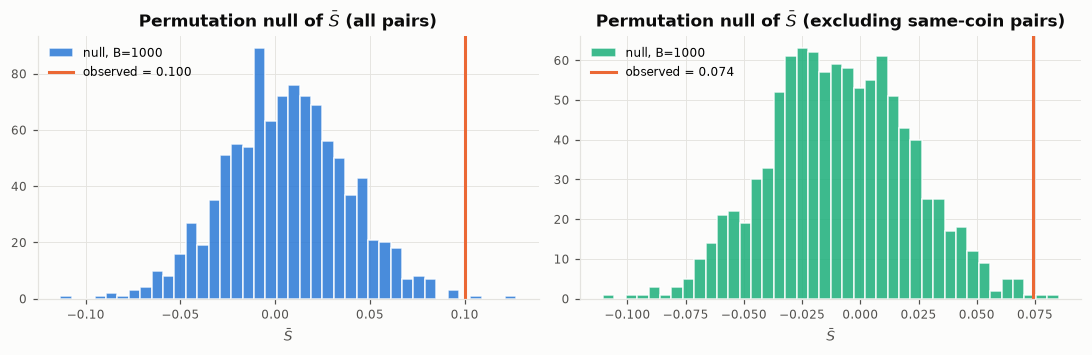

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, name, c in zip(axes, variants, (SERIES[0], SERIES[2])):
    ax.hist(nulls[name], bins=40, color=c, alpha=0.85, edgecolor="white", label=f"null, B={B}")
    ax.axvline(out[name][1], color=SERIES[1], lw=2, label=f"observed = {out[name][1]:.3f}")
    ax.set_title(f"Permutation null of $\\bar S$ ({name})")
    ax.set_xlabel(r"$\bar S$")
    ax.legend()
R.fig(fig, "permutation_null")
close(fig)

### 3. Which channels are homogeneous? (multiple testing)

For each channel the same draws give $\hat p_h=(1+\#\{b:S^{(b)}_{\text{intra}}(h)\ge S_{\text{intra}}(h)\})/(B+1)$.
Testing $H$ channels at once inflates false discoveries; the **Benjamini–Hochberg** procedure controls the false
discovery rate: sort $\hat p_{(1)}\le\dots\le\hat p_{(H)}$ and reject the $k$ smallest where
$k=\max\{j:\hat p_{(j)}\le jq/H\}$, here $q=0.05$.

In [5]:
obs, _ = out["all pairs"]
pch = np.array([S.monte_carlo_p(obs[h], per_ch_null["all pairs"][:, h]) for h in range(len(chans))])
qch = S.benjamini_hochberg(pch)
per = pd.DataFrame({"channel": chans, "n_h": A.sum(0).astype(int), "S_intra": obs, "p_hat": pch, "q_BH": qch}) \
    .sort_values("S_intra", ascending=False)
R.table(per, "per_channel", index=False)
show(per.head(15).set_index("channel"))
md(f"{(per.q_BH < 0.05).sum()} of {len(per)} channels are individually homogeneous at FDR 5 % "
   f"({(per.p_hat < 0.05).sum()} at the unadjusted 5 % level). Small channels have little power: with $n_h=2$ a "
   "single pair decides the statistic.")

,n_h,S_intra,p_hat,q_BH
channel,,,,
Ch-086,2,0.9791,0.006993,0.0743
Ch-104,4,0.9192,0.000999,0.04246
Ch-016,2,0.8532,0.04096,0.2176
Ch-087,4,0.8317,0.001998,0.04246
Ch-066,4,0.8019,0.001998,0.04246
Ch-102,2,0.8011,0.05694,0.242
Ch-008,2,0.676,0.1169,0.3777
Ch-018,2,0.6359,0.1269,0.3777
Ch-014,5,0.5837,0.004995,0.07076


4 of 85 channels are individually homogeneous at FDR 5 % (18 at the unadjusted 5 % level). Small channels have little power: with $n_h=2$ a single pair decides the statistic.

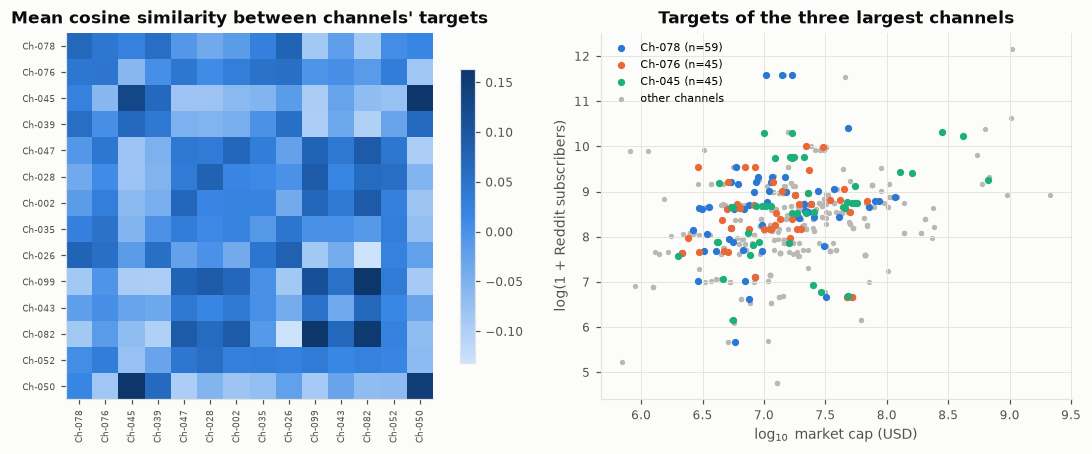

In [6]:
top = per.sort_values("n_h", ascending=False).head(14).channel.tolist()
idx = [np.where(df.channel.values == c)[0] for c in top]
H = np.array([[M[np.ix_(a, b)][~np.eye(len(a), dtype=bool)].mean() if i == j else M[np.ix_(a, b)].mean()
               for j, b in enumerate(idx)] for i, a in enumerate(idx)])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(H, cmap=seq_cmap(), vmin=np.nanmin(H), vmax=np.nanmax(H))
axes[0].set_xticks(range(len(top)), top, rotation=90, fontsize=6)
axes[0].set_yticks(range(len(top)), top, fontsize=6)
axes[0].set_title("Mean cosine similarity between channels' targets")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
pts = df.assign(lm=np.log10(df.market_cap_usd), lr=np.log1p(df.reddit_subscribers))
for c, color in zip(top[:3], SERIES[:3]):
    s = pts[pts.channel == c]
    axes[1].scatter(s.lm, s.lr, s=14, color=color, label=f"{c} (n={len(s)})")
rest = pts[~pts.channel.isin(top[:3])]
axes[1].scatter(rest.lm, rest.lr, s=6, color="#b9b8b2", label="other channels", zorder=0)
axes[1].set_xlabel(r"$\log_{10}$ market cap (USD)")
axes[1].set_ylabel("log(1 + Reddit subscribers)")
axes[1].set_title("Targets of the three largest channels")
axes[1].legend(fontsize=7)
R.fig(fig, "channel_heatmap")
close(fig)

### 4. Interpretation (QUICK run, B = 1 000)

* **The paper's qualitative claim survives a formal test.** The observed $\bar S\approx0.10$ lies about three null
  standard deviations above the permutation mean ($\approx0$), and only 2 of the 1 000 permuted labellings reach
  it ($\hat p=3/1001\approx0.003$). $H_0$ "channel labels carry no information about target profiles" is rejected at
  the 1 % level. Excluding pairs of the same coin barely changes the result ($\hat p\approx0.003$), so homogeneity
  is not just a consequence of re-pumps.
* **The effect is real but moderate in absolute size.** Two targets of the same channel have a mean cosine of
  about 0.07 against 0.005 for two targets of different channels. On five standardised features this is a
  tendency, not a rule: channels have a preferred niche but wander outside it. The paper's 0.92 vs 0.80 figures
  come from word embeddings trained on co-occurrence in Telegram messages, which encode "being mentioned together"
  rather than market profiles. They are not comparable in level.
* **Intra-channel homogeneity** means a channel works in a stable niche (a capitalisation and audience range that
  its members can move). **Inter-channel heterogeneity** means niches differ between channels. Together they
  justify conditioning the prediction on the channel's history (sequence models, II.C) instead of learning one
  global "pumpability" score.
* **Per channel**, 18 of 85 channels are significant at the unadjusted 5 % level but only 4 survive the
  Benjamini–Hochberg correction. Most channels have between 2 and 5 profiled targets, so each test has little
  power; the global statistic pools that weak evidence.

**Limitations.** Features are measured three days before each pump, and coins whose CoinGecko record is incomplete
are excluded. Permutations preserve channel sizes but not timing: channels active in the same period may look alike
because the whole market moved, which a time-stratified permutation would control. With $B=1000$ the p-value is
resolved to about $10^{-3}$; the full run ($B=10\,000$) sharpens it.

## I.5 — Coordination network of Telegram channels ([A2] method)

**Objective (brief I.5).** Find, without supervision, groups of channels that act in a synchronised way, by
transposing the coordination-network method of Pacheco et al. [A2] to Telegram pump channels:

1. **Traits.** A trait is a pair $j=(c,\lfloor\tau/\Delta\rfloor)$: a coin and a time bucket of length $\Delta$.
   Two channels share a trait when they pump the same coin in the same bucket.
2. **Bipartite matrix.** Channels $\times$ traits, weighted by TF-IDF:
   $A_{uj}=\mathrm{tf}_{uj}\,\log\!\big(|\mathcal U|/\mathrm{df}_j\big)$, where $\mathrm{tf}_{uj}$ is the number of
   times channel $u$ exhibits trait $j$ and $\mathrm{df}_j$ the number of channels exhibiting it. Rare shared traits
   weigh more than traits shared by everyone.
3. **Projection.** Channel–channel weights $W_{uv}=\cos(A_{u\cdot},A_{v\cdot})$.
4. **Filtering.** Keep only the edges above the 99.5 % quantile of the non-zero weights.
5. **Communities.** Louvain algorithm [6], which greedily maximises the modularity
   $$Q=\frac{1}{2m}\sum_{u,v}\Big(W_{uv}-\frac{k_uk_v}{2m}\Big)\mathbf 1\{g_u=g_v\},$$
   with $k_u=\sum_v W_{uv}$ the weighted degree and $2m=\sum_u k_u$.
6. **Null model.** Pump times are permuted across rows (each channel keeps its coins and its number of pumps but
   loses its timing), 1 000 times in the full run. Each edge receives a Monte-Carlo p-value
   $\hat p_{uv}=(1+\#\{b:W^{(b)}_{uv}\ge W_{uv}\})/(B+1)$, and the modularity a null distribution.

We then discuss the sensitivity to $\Delta$ and to the threshold, and compare the communities with the
`session_id` column of the log.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log
from pnd_paper.report import Reporter, md, show, close, SERIES

settings.seed_everything()
R = Reporter("I5_coordination_network")
B = settings.SIZES.null_draws
log = pd_log.load_pd_log()
log["channel"] = log.channel_id.map(pd_log.channel_labels(log.channel_id))
channels = np.array(sorted(log.channel.unique()))
md(f"{len(log)} rows, $|\\mathcal U|={len(channels)}$ channels. Null-model draws: **B = {B}** "
   f"({'QUICK' if settings.QUICK else 'FULL'} run).")

1335 rows, $|\mathcal U|=108$ channels. Null-model draws: **B = 200** (QUICK run).

In [2]:
def similarity(df, delta):
    """Cosine similarity matrix of the channel x trait TF-IDF matrix for bucket length delta."""
    bucket = (df.timestamp.astype("int64") // int(pd.Timedelta(delta).value)).astype(str)
    trait = df.coin + "|" + bucket
    u = pd.Categorical(df.channel, categories=channels).codes
    tcodes, _ = pd.factorize(trait)
    tf = sparse.csr_matrix((np.ones(len(df)), (u, tcodes)), shape=(len(channels), tcodes.max() + 1))
    tf.sum_duplicates()
    dfj = np.asarray((tf > 0).sum(axis=0)).ravel()
    idf = np.log(len(channels) / dfj)
    A = tf @ sparse.diags(idf)
    norms = np.sqrt(np.asarray(A.multiply(A).sum(axis=1)).ravel())
    norms[norms == 0] = 1.0
    An = sparse.diags(1 / norms) @ A
    W = (An @ An.T).toarray()
    np.fill_diagonal(W, 0.0)
    return W


def graph_from(W, q):
    iu = np.triu_indices_from(W, 1)
    w = W[iu]
    nz = w[w > 0]
    thr = np.quantile(nz, q) if len(nz) else np.inf
    G = nx.Graph()
    G.add_nodes_from(range(len(W)))
    for a, b, x in zip(iu[0], iu[1], w):
        if x > 0 and x >= thr:
            G.add_edge(int(a), int(b), weight=float(x))
    G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])
    return G, thr


def louvain(G, seed=settings.SEED):
    if G.number_of_edges() == 0:
        return [], np.nan
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    return comms, nx.community.modularity(G, comms, weight="weight")

### 1. Network for $\Delta=1$ hour, threshold 99.5 %

In [3]:
DELTA, Q = "1h", 0.995
W = similarity(log, DELTA)
G, thr = graph_from(W, Q)
comms, mod = louvain(G)
iu = np.triu_indices_from(W, 1)
nz = (W[iu] > 0).sum()
md(f"Pairs of channels sharing at least one trait: **{nz}** of {len(iu[0])} ({nz / len(iu[0]):.1%}). "
   f"Threshold (99.5 % quantile of non-zero weights): $W\\ge{thr:.3f}$, which keeps **{G.number_of_edges()} edges** "
   f"between **{G.number_of_nodes()} channels**. Louvain finds **{len(comms)} communities** with modularity "
   f"$Q={mod:.3f}$.")

Pairs of channels sharing at least one trait: **490** of 5778 (8.5%). Threshold (99.5 % quantile of non-zero weights): $W\ge0.906$, which keeps **3 edges** between **6 channels**. Louvain finds **3 communities** with modularity $Q=0.666$.

Because only a few dozen pairs survive the 99.5 % filter, we also analyse the network filtered at the 95 % quantile,
which keeps more structure while still discarding most weak coincidences.

In [4]:
G95, thr95 = graph_from(W, 0.95)
comms95, mod95 = louvain(G95)
md(f"At 95 %: $W\\ge{thr95:.3f}$, {G95.number_of_edges()} edges, {G95.number_of_nodes()} channels, "
   f"{len(comms95)} communities, $Q={mod95:.3f}$.")

At 95 %: $W\ge0.648$, 25 edges, 21 channels, 7 communities, $Q=0.465$.

### 2. Null model: permuting pump times

Under $H_0$ "channels choose *when* to pump independently of each other", shuffling the timestamps across rows
preserves each channel's coins and activity but destroys synchronisation. For every draw we recompute $W^{(b)}$,
the number of non-zero pairs, and the modularity of the network filtered at the same quantile.

,observed,null mean,null sd,p_hat
statistic,,,,
non-zero pairs,490,17.19,4.145,0.004975
modularity Q (99.5%),0.6661,1.221e-17,3.482e-17,0.004975
modularity Q (95%),0.4653,0.08673,0.1822,0.1343


Edge-level test: 487 of 490 non-zero edges are significant at FDR 5 % (Benjamini–Hochberg on $\hat p_{uv}$; the smallest attainable $\hat p$ is $1/(B+1)=0.0050$). Under the null, channels share a trait for 17 pairs on average versus 490 observed: $\hat p=0.0050$ → reject $H_0$ at $\alpha=0.05$.

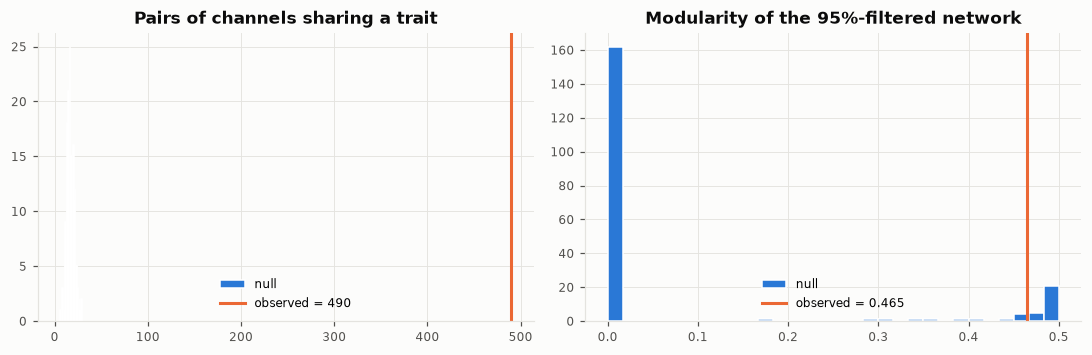

In [5]:
rng = np.random.default_rng(settings.SEED)
null_W = np.empty((B, len(iu[0])))
null_nz, null_Q, null_Q95 = np.empty(B), np.empty(B), np.empty(B)
for b in range(B):
    perm = log.assign(timestamp=log.timestamp.values[rng.permutation(len(log))])
    Wb = similarity(perm, DELTA)
    null_W[b] = Wb[iu]
    null_nz[b] = (Wb[iu] > 0).sum()
    null_Q[b] = louvain(graph_from(Wb, Q)[0], seed=b)[1]
    null_Q95[b] = louvain(graph_from(Wb, 0.95)[0], seed=b)[1]

obs = W[iu]
edge_p = (1 + (null_W >= obs[None, :]).sum(axis=0)) / (B + 1)
edge_q = S.benjamini_hochberg(edge_p[obs > 0])
null_tab = pd.DataFrame({
    "statistic": ["non-zero pairs", "modularity Q (99.5%)", "modularity Q (95%)"],
    "observed": [nz, mod, mod95],
    "null mean": [null_nz.mean(), np.nanmean(null_Q), np.nanmean(null_Q95)],
    "null sd": [null_nz.std(ddof=1), np.nanstd(null_Q, ddof=1), np.nanstd(null_Q95, ddof=1)],
    "p_hat": [S.monte_carlo_p(nz, null_nz), S.monte_carlo_p(mod, null_Q[np.isfinite(null_Q)]),
              S.monte_carlo_p(mod95, null_Q95[np.isfinite(null_Q95)])],
}).set_index("statistic")
R.table(null_tab, "null_model")
show(null_tab)
sig = int((edge_q < 0.05).sum())
md(f"Edge-level test: {sig} of {int((obs > 0).sum())} non-zero edges are significant at FDR 5 % "
   f"(Benjamini–Hochberg on $\\hat p_{{uv}}$; the smallest attainable $\\hat p$ is $1/(B+1)={1 / (B + 1):.4f}$). "
   f"Under the null, channels share a trait for {null_nz.mean():.0f} pairs on average versus {nz} observed: "
   f"$\\hat p={S.monte_carlo_p(nz, null_nz):.4f}$ → {S.decision(S.monte_carlo_p(nz, null_nz))}.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].hist(null_nz, bins=30, color=SERIES[0], edgecolor="white", label="null")
axes[0].axvline(nz, color=SERIES[1], lw=2, label=f"observed = {nz}")
axes[0].set_title("Pairs of channels sharing a trait")
axes[0].legend()
axes[1].hist(null_Q95[np.isfinite(null_Q95)], bins=30, color=SERIES[0], edgecolor="white", label="null")
axes[1].axvline(mod95, color=SERIES[1], lw=2, label=f"observed = {mod95:.3f}")
axes[1].set_title("Modularity of the 95%-filtered network")
axes[1].legend()
R.fig(fig, "null_model")
close(fig)

### 3. Sensitivity to $\Delta$ and to the threshold

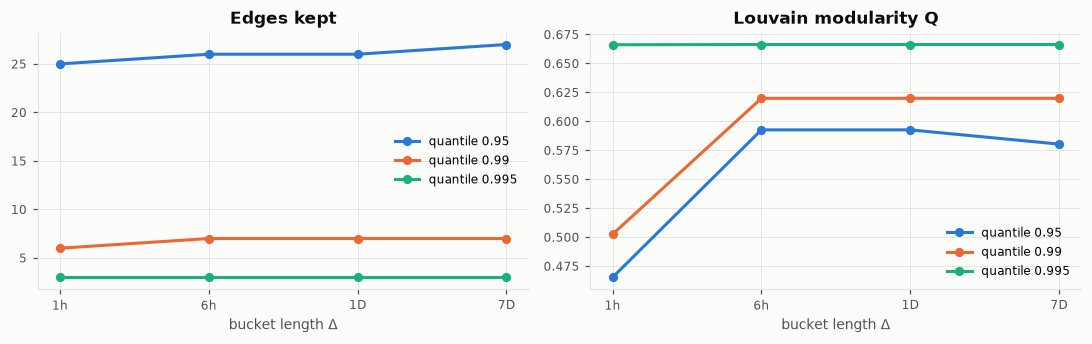

In [6]:
sens = []
for delta in ["1h", "6h", "1D", "7D"]:
    Wd = similarity(log, delta)
    for q in (0.95, 0.99, 0.995):
        Gd, t = graph_from(Wd, q)
        cd, md_ = louvain(Gd)
        sens.append({"Delta": delta, "quantile": q, "non-zero pairs": int((Wd[iu] > 0).sum()), "threshold": t,
                     "edges": Gd.number_of_edges(), "channels": Gd.number_of_nodes(), "communities": len(cd),
                     "modularity": md_, "largest community": max((len(c) for c in cd), default=0)})
sens = pd.DataFrame(sens)
R.table(sens, "sensitivity", index=False)
show(sens.set_index(["Delta", "quantile"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for i, q in enumerate((0.95, 0.99, 0.995)):
    s = sens[sens["quantile"] == q]
    axes[0].plot(s.Delta, s.edges, marker="o", color=SERIES[i], label=f"quantile {q}")
    axes[1].plot(s.Delta, s.modularity, marker="o", color=SERIES[i], label=f"quantile {q}")
axes[0].set_title("Edges kept")
axes[1].set_title("Louvain modularity Q")
for a in axes:
    a.set_xlabel(r"bucket length $\Delta$")
    a.legend()
R.fig(fig, "sensitivity")
close(fig)

### 4. Network figure (Δ = 1 h, 95 % filter)

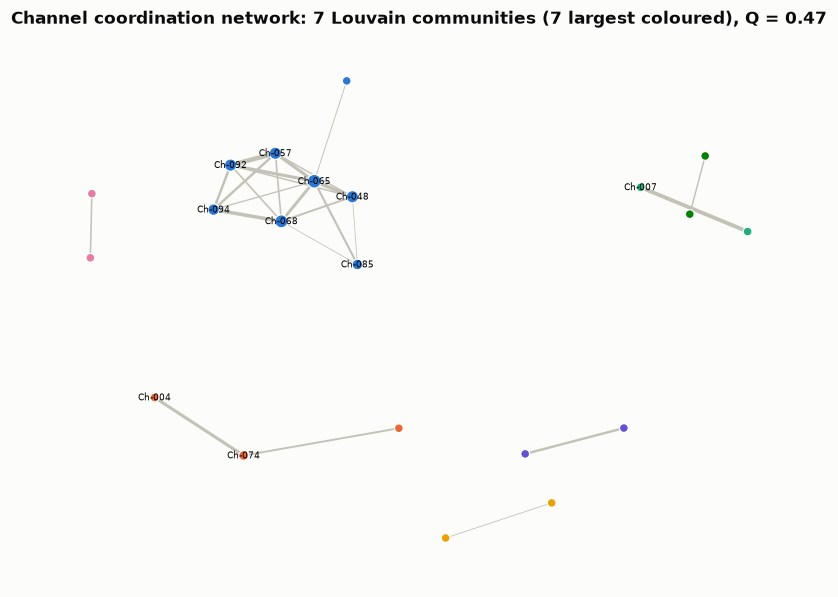

In [7]:
pos = nx.spring_layout(G95, weight="weight", seed=settings.SEED, k=0.6)
order = sorted(comms95, key=len, reverse=True)
color_of = {}
for i, c in enumerate(order):
    for n in c:
        color_of[n] = SERIES[i] if i < 7 else "#b9b8b2"
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ws = np.array([d["weight"] for *_, d in G95.edges(data=True)])
nx.draw_networkx_edges(G95, pos, ax=ax, width=0.5 + 2.5 * (ws - ws.min()) / (np.ptp(ws) + 1e-9), edge_color="#c3c2b7")
nx.draw_networkx_nodes(G95, pos, ax=ax, node_size=[25 + 8 * G95.degree(n) for n in G95.nodes],
                       node_color=[color_of[n] for n in G95.nodes], edgecolors="white", linewidths=0.8)
labels = {n: channels[n] for n in sorted(G95.nodes, key=G95.degree, reverse=True)[:10]}
nx.draw_networkx_labels(G95, pos, labels, font_size=6, ax=ax)
ax.set_title(f"Channel coordination network: {len(order)} Louvain communities (7 largest coloured), Q = {mod95:.2f}")
ax.axis("off")
R.fig(fig, "network")
close(fig)

### 5. Comparison with `session_id`

In the authors' log, `session_id` numbers the **sessions of one channel** (the output of their message-session
aggregation), not a pump shared between channels: the same number in two channels is a coincidence. We verify
this, then compare the communities with the grouping `session_id` was meant to approximate, the **co-pump groups**:
connected components of the graph joining two channels whenever they announced the same coin within the same
hour. Agreement between partitions is measured on the channels present in the network with

* the adjusted Rand index $\mathrm{ARI}=\dfrac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{\max\mathrm{RI}-\mathbb E[\mathrm{RI}]}$
  (0 for random partitions, 1 for identical ones);
* the normalised mutual information $\mathrm{NMI}=\dfrac{2I(X;Y)}{H(X)+H(Y)}$.

In [8]:
shared = log.groupby("session_id").channel_id.nunique()
same_sid = log[log.session_id.isin(shared[shared > 1].index)]
coin_agree = same_sid.groupby("session_id").coin.nunique().eq(1).mean()
md(f"{(shared > 1).sum()} session ids appear in more than one channel; in only **{coin_agree:.1%}** of them do all "
   "rows name the same coin, so `session_id` is a per-channel counter and cannot by itself identify a coordinated "
   "pump.")

h = log.assign(h=log.timestamp.dt.floor("h"), u=pd.Categorical(log.channel, categories=channels).codes)
pair_counts = {}
for _, g in h.groupby(["coin", "h"]):
    us = sorted(set(g.u))
    for i_, a_ in enumerate(us):
        for b_ in us[i_ + 1:]:
            pair_counts[(a_, b_)] = pair_counts.get((a_, b_), 0) + 1
G1 = nx.Graph()
G1.add_nodes_from(range(len(channels)))
G1.add_edges_from(k for k, v in pair_counts.items() if v >= 1)
giant = max(nx.connected_components(G1), key=len)
md(f"Joining channels that co-announced at least one pump gives a giant component of **{len(giant)}** channels: "
   "relays chain almost every active channel together, so single co-pumps cannot define groups. We therefore define "
   "**repeated co-pump groups** as connected components of the graph joining channels with **at least two** "
   "co-announced pumps, restricted to the channels of the network.")
rows = []
for name, (Gx, cx) in {"99.5% filter": (G, comms), "95% filter": (G95, comms95)}.items():
    nodes = sorted(Gx.nodes)
    G2 = nx.Graph()
    G2.add_nodes_from(nodes)
    G2.add_edges_from(k for k, v in pair_counts.items() if v >= 2 and k[0] in G2 and k[1] in G2)
    grp = {n: i for i, comp in enumerate(nx.connected_components(G2)) for n in comp}
    lab = {n: i for i, c in enumerate(cx) for n in c}
    a = [lab[n] for n in nodes]
    b = [grp[n] for n in nodes]
    sidmode = [log[log.channel == channels[n]].session_id.mode().iloc[0] for n in nodes]
    rows.append({"network": name, "channels": len(nodes), "repeated co-pump groups": len(set(b)),
                 "communities": len(set(a)), "ARI vs co-pump groups": adjusted_rand_score(b, a),
                 "NMI vs co-pump groups": normalized_mutual_info_score(b, a),
                 "ARI vs session_id (modal)": adjusted_rand_score(sidmode, a)})
cmp_tab = pd.DataFrame(rows).set_index("network")
R.table(cmp_tab, "communities_vs_sessions")
show(cmp_tab)

comm_rows = []
for i, c in enumerate(order[:7]):
    sub = log[log.channel.isin(channels[list(c)])]
    comm_rows.append({"community": i + 1, "channels": len(c), "rows": len(sub), "distinct coins": sub.coin.nunique(),
                      "main exchange": sub.exchange.mode().iloc[0],
                      "active from": f"{sub.timestamp.min():%Y-%m}", "active to": f"{sub.timestamp.max():%Y-%m}"})
comm_tab = pd.DataFrame(comm_rows).set_index("community")
R.table(comm_tab, "community_profiles")
show(comm_tab)

276 session ids appear in more than one channel; in only **0.4%** of them do all rows name the same coin, so `session_id` is a per-channel counter and cannot by itself identify a coordinated pump.

Joining channels that co-announced at least one pump gives a giant component of **91** channels: relays chain almost every active channel together, so single co-pumps cannot define groups. We therefore define **repeated co-pump groups** as connected components of the graph joining channels with **at least two** co-announced pumps, restricted to the channels of the network.

,channels,repeated co-pump groups,communities,ARI vs co-pump groups,NMI vs co-pump groups,ARI vs session_id (modal)
network,,,,,,
99.5% filter,6,2,3,0.4444,0.7337,0
95% filter,21,8,7,0.9831,0.9816,0.16


,channels,rows,distinct coins,main exchange,active from,active to
community,,,,,,
1,8,40,9,binance,2020-03,2021-11
2,3,7,3,binance,2019-08,2019-09
3,2,11,5,binance,2019-08,2021-11
4,2,3,2,binance,2019-06,2019-06
5,2,10,5,binance,2019-03,2019-06
6,2,40,17,yobit,2019-01,2019-05
7,2,15,9,binance,2019-05,2021-07


### 6. Interpretation (QUICK run, B = 200)

* **Synchronisation is massive and far beyond chance.** 490 pairs of channels share at least one
  (coin, hour) trait, against about 17 when pump times are shuffled ($\hat p=1/(B+1)$, the smallest value the
  number of draws allows). 487 of the 490 non-zero edges are individually significant at FDR 5 %. Channels do not
  pick their coins and times independently: a large share of pumps are **relayed** or jointly organised.
* **Communities.** At the brief's 99.5 % threshold only 3 edges survive because the projected network is small
  (490 non-zero pairs). The 95 % filter keeps 25 edges between 21 channels, split by Louvain into 7 communities
  ($Q\approx0.47$). The largest groups 8 Binance channels active from 2020 to 2021; one community is a Yobit
  pair active in early 2019.
* **Is the community structure itself significant?** At 95 %, the null modularity is 0.09 on average but highly
  variable, and $\hat p\approx0.13$: the *edges* are significant, but given that few edges are kept, a modularity of
  0.47 is not exceptional. The filtered network is a set of nearly disconnected cliques, and modularity is high
  for any such graph. The communities should be read as "groups of channels that repeatedly relay each other",
  not as a hidden structure beyond pairwise coordination.
* **Sensitivity.** Results barely change with $\Delta$ from 6 hours to 7 days (same communities, $Q\approx0.59$), and
  $\Delta=1$ h loses a few pairs whose announcements differ by more than an hour. The threshold matters much more
  than $\Delta$: 25 edges at 95 %, 6–7 at 99 %, 3 at 99.5 %. The 99.5 % rule of [A2] was designed for networks
  with millions of accounts; with 108 channels a lower quantile is needed to keep any structure.
* **Comparison with `session_id`.** `session_id` is a per-channel session counter (the same id in two channels
  names the same coin in only 0.4 % of cases), so it cannot be compared directly and its ARI with the communities
  is close to 0. Against the grouping it was meant to approximate, groups of channels that co-announced at least
  two pumps, the 95 % communities agree almost perfectly ($\mathrm{ARI}\approx0.98$, $\mathrm{NMI}\approx0.98$).
  The unsupervised network recovers the relay groups without being told about them.

**Limitations.** The null model keeps each channel's coins but breaks the joint timing of *all* pumps, including
genuine market-wide waves (several unrelated channels can pick the same trendy coin in the same day). A null that
preserves the daily popularity of coins would be stricter.

# Part II — Modelling

## II.A.1 — Stationarity tests and ARMA–GARCH models of calm-period returns

**Objective (brief II.A.1).** For 10 pump targets in a calm period, (i) test stationarity and serial dependence
with the ADF, KPSS and Ljung–Box tests, and (ii) fit an ARMA$(p,q)$–GARCH(1,1) model with Student-$t$ innovations:
$$r_t=\mu+\sum_{i=1}^{p}\phi_i r_{t-i}+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j},\qquad
\varepsilon_t=\sigma_t\eta_t,\qquad \sigma_t^2=\omega+\alpha\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2,$$
with $\eta_t$ i.i.d. standardised Student-$t_\nu$ ($\mathbb E\eta_t=0$, $\operatorname{Var}\eta_t=1$). These models
describe "normal" behaviour; II.A.2 uses their standardised residuals $\hat\eta_t$ to detect pumps.

**Calm period.** For a pump at $\tau$ we use the hourly log-returns (in %) on $[\tau-30\,\text{d},\ \tau-72\,\text{h}]$,
the estimation window of I.3, which ends before the pre-pump drift.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from arch import arch_model

from pnd_paper import settings, tsmodels
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IIA1_arma_garch")

ev_all = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_ = panels["close"]


def calm_window(e):
    t = universe.last_bar_before(e.timestamp)
    s = close_[e.symbol].loc[t - pd.Timedelta(days=30):t - pd.Timedelta(hours=72)]
    return s


# choose 10 distinct coins with complete calm windows (seeded draw among eligible events)
rng = np.random.default_rng(settings.SEED)
cands = []
for e in ev_all.drop_duplicates("symbol").itertuples():
    if e.symbol in close_.columns:
        s = calm_window(e)
        if len(s) > 600 and s.notna().mean() > 0.99 and (s.diff() != 0).mean() > 0.9:
            cands.append(e)
chosen = [cands[i] for i in sorted(rng.choice(len(cands), settings.SIZES.garch_targets, replace=False))]
series = {e.coin: 100 * np.log(calm_window(e)).diff().dropna() for e in chosen}
info = pd.DataFrame([{"coin": e.coin, "pump time": f"{e.timestamp:%Y-%m-%d %H:%M}", "calm window": f"{s.index[0]:%Y-%m-%d} → {s.index[-1]:%Y-%m-%d}",
                      "n": len(s), "mean (%)": s.mean(), "sd (%)": s.std(), "skew": st.skew(s), "excess kurtosis": st.kurtosis(s)}
                     for e, s in zip(chosen, series.values())]).set_index("coin")
R.table(info, "targets")
show(info)
md(f"{len(cands)} target coins have a complete, actively traded calm window; 10 are drawn at random (seed "
   f"{settings.SEED}). Every series has a large excess kurtosis, which motivates Student-$t$ innovations.")

,pump time,calm window,n,mean (%),sd (%),skew,excess kurtosis
coin,,,,,,,
GXS,2019-01-20 17:59,2018-12-21 → 2019-01-17,648,0.01262,0.7278,0.1134,5.509
WINGS,2019-01-27 18:00,2018-12-28 → 2019-01-24,648,0.03826,1.924,7.136,101.1
GRS,2019-02-02 18:00,2019-01-03 → 2019-01-30,648,-0.01188,0.7893,-0.2981,6.948
AST,2019-03-02 14:00,2019-01-31 → 2019-02-27,648,0.02714,1.368,1.624,20.47
ONT,2019-03-21 03:25,2019-02-19 → 2019-03-18,641,0.07022,1.476,1.112,7.717
RDN,2019-03-24 18:59,2019-02-22 → 2019-03-21,641,0.03261,1.683,3.615,38.58
WRX,2021-04-04 15:21,2021-03-05 → 2021-04-01,646,0.1598,2.26,1.881,13.64
CFX,2021-05-12 17:18,2021-04-12 → 2021-05-09,641,-0.03606,1.74,1.624,14.48
ACM,2021-06-05 18:00,2021-05-06 → 2021-06-02,648,0.01573,3.433,0.9148,10.04


58 target coins have a complete, actively traded calm window; 10 are drawn at random (seed 1234). Every series has a large excess kurtosis, which motivates Student-$t$ innovations.

### 1. Tests

* **ADF** (augmented Dickey–Fuller). Regression $\Delta y_t=c+\gamma y_{t-1}+\sum_{k=1}^{K}\delta_k\Delta y_{t-k}+u_t$;
  $H_0:\gamma=0$ (unit root) against $H_1:\gamma<0$ (stationary). The statistic $\hat\gamma/\mathrm{se}(\hat\gamma)$
  follows the Dickey–Fuller distribution; $K$ is chosen by AIC.
* **KPSS**. $y_t=\xi_t+u_t$ with a random walk $\xi_t$ of variance $\sigma^2_\xi$; $H_0:\sigma^2_\xi=0$
  (level-stationary). Statistic $\eta=T^{-2}\sum_t S_t^2/\hat\lambda^2$ with $S_t$ the partial sums of residuals and
  $\hat\lambda^2$ a Newey–West long-run variance. ADF and KPSS have opposite null hypotheses, so stationarity is
  supported when ADF rejects **and** KPSS does not.
* **Ljung–Box**. $Q(m)=T(T+2)\sum_{k=1}^{m}\hat\rho_k^2/(T-k)\overset{H_0}{\sim}\chi^2_m$, $H_0$: no autocorrelation
  up to lag $m$. Applied to $r_t$ (linear dependence, i.e. the ARMA part) and to $r_t^2$ (volatility clustering,
  i.e. the GARCH part), with $m=24$ hours.
* **ARCH-LM** (Engle). Regression of $\hat u_t^2$ on $m$ of its lags; $TR^2\overset{H_0}{\sim}\chi^2_m$, $H_0$: no
  ARCH effect.

In [2]:
rows = []
for coin, r in series.items():
    lp = np.log(close_[[e for e in chosen if e.coin == coin][0].symbol].loc[r.index])
    adf_p = adfuller(lp, autolag="AIC")
    adf_r = adfuller(r, autolag="AIC")
    kp_p = kpss(lp, regression="c", nlags="auto")
    kp_r = kpss(r, regression="c", nlags="auto")
    lb = acorr_ljungbox(r, lags=[24])
    lb2 = acorr_ljungbox(r**2, lags=[24])
    arch_lm = het_arch(r - r.mean(), nlags=12)
    rows.append({"coin": coin, "ADF log-price": adf_p[0], "p ADF log-price": adf_p[1], "ADF r": adf_r[0], "p ADF r": adf_r[1],
                 "KPSS log-price": kp_p[0], "p KPSS log-price": kp_p[1], "KPSS r": kp_r[0], "p KPSS r": kp_r[1],
                 "Q(24) r": lb.lb_stat.iloc[0], "p Q r": lb.lb_pvalue.iloc[0], "Q(24) r^2": lb2.lb_stat.iloc[0],
                 "p Q r^2": lb2.lb_pvalue.iloc[0], "ARCH-LM(12)": arch_lm[0], "p ARCH": arch_lm[1]})
tests = pd.DataFrame(rows).set_index("coin")
R.table(tests, "stationarity_tests")
show(tests, "{:.3g}")
md("**Reading the table.** statsmodels truncates KPSS p-values to [0.01, 0.10] (values printed as 0.01 or 0.1 mean "
   "'at most' / 'at least').\n\n"
   f"- Log-prices: ADF rejects the unit root for {(tests['p ADF log-price'] < 0.05).sum()}/10 coins and KPSS rejects "
   f"level-stationarity for {(tests['p KPSS log-price'] < 0.05).sum()}/10.\n"
   f"- Returns: ADF rejects the unit root for {(tests['p ADF r'] < 0.05).sum()}/10 coins, KPSS rejects stationarity for "
   f"{(tests['p KPSS r'] < 0.05).sum()}/10.\n"
   f"- Ljung–Box on $r_t$ rejects 'no autocorrelation' for {(tests['p Q r'] < 0.05).sum()}/10 coins; on $r_t^2$ for "
   f"{(tests['p Q r^2'] < 0.05).sum()}/10; ARCH-LM detects ARCH effects for {(tests['p ARCH'] < 0.05).sum()}/10.")

,ADF log-price,p ADF log-price,ADF r,p ADF r,KPSS log-price,p KPSS log-price,KPSS r,p KPSS r,Q(24) r,p Q r,Q(24) r^2,p Q r^2,ARCH-LM(12),p ARCH
coin,,,,,,,,,,,,,,
GXS,-2.34,0.16,-11.1,3.35e-20,0.276,0.1,0.038,0.1,57.8,0.000128,112,2.36e-13,57.1,7.49e-08
WINGS,-1.66,0.452,-5.97,1.99e-07,1.92,0.01,0.073,0.1,68.5,3.63e-06,147,1.34e-19,132,2.34e-22
GRS,-2.35,0.156,-12.9,3.88e-24,0.384,0.0838,0.0497,0.1,38.4,0.0313,181,3.88e-26,78.1,9.38e-12
AST,-1.95,0.309,-14.8,2.19e-27,2.56,0.01,0.0523,0.1,38.9,0.028,66.5,7.32e-06,58.3,4.65e-08
ONT,-2.26,0.187,-6.12,8.81e-08,1.92,0.01,0.163,0.1,60.8,4.91e-05,298,4.53e-49,138,1.2e-23
RDN,-1.95,0.307,-5.13,1.22e-05,2.64,0.01,0.0449,0.1,122,5.22e-15,150,2.76e-20,18.1,0.114
WRX,0.447,0.983,-6.21,5.65e-08,2.82,0.01,0.201,0.1,93.1,4.43e-10,227,5.35e-35,56.7,9.1e-08
CFX,-2,0.288,-8.42,1.99e-13,1.78,0.01,0.0412,0.1,63.5,2.04e-05,40.7,0.0178,32.7,0.00108
ACM,-1.76,0.4,-10.3,3.27e-18,0.76,0.01,0.165,0.1,50.6,0.0012,107,2.18e-12,62.9,6.69e-09


**Reading the table.** statsmodels truncates KPSS p-values to [0.01, 0.10] (values printed as 0.01 or 0.1 mean 'at most' / 'at least').

- Log-prices: ADF rejects the unit root for 0/10 coins and KPSS rejects level-stationarity for 8/10.
- Returns: ADF rejects the unit root for 10/10 coins, KPSS rejects stationarity for 0/10.
- Ljung–Box on $r_t$ rejects 'no autocorrelation' for 9/10 coins; on $r_t^2$ for 9/10; ARCH-LM detects ARCH effects for 8/10.

### 2. ARMA$(p,q)$–GARCH(1,1)–$t$ estimation

**Estimation.** Parameters $\psi=(\mu,\phi,\theta,\omega,\alpha,\beta,\nu)$ maximise the conditional log-likelihood
$$\ell(\psi)=\sum_{t}\Big[\log\Gamma\big(\tfrac{\nu+1}{2}\big)-\log\Gamma\big(\tfrac{\nu}{2}\big)-\tfrac12\log\big(\pi(\nu-2)\big)
-\log\sigma_t-\tfrac{\nu+1}{2}\log\Big(1+\frac{\eta_t^2}{\nu-2}\Big)\Big],\quad \eta_t=\varepsilon_t/\sigma_t,$$
under $\omega>0$, $\alpha,\beta\ge0$, $\alpha+\beta<1$ (covariance stationarity) and $\nu>2$. Standard errors come
from the inverse numerical Hessian, $\widehat{\operatorname{Var}}(\hat\psi)=[-\nabla^2\ell(\hat\psi)]^{-1}$. The
estimator is written from scratch (`pnd_paper.tsmodels`) because the `arch` package only offers AR means; we
validate it against `arch` on the AR(1) special case.

**Order selection.** $p,q\in\{0,1,2,3\}$ (16 models per coin), chosen by
$\mathrm{BIC}=-2\ell(\hat\psi)+k\log n$.

In [3]:
coin0 = next(iter(series))
f_ours = tsmodels.fit_arma_garch(series[coin0].values, 1, 0)
f_arch = arch_model(series[coin0].values, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
val = pd.DataFrame({"pnd_paper": [f_ours.params[k] for k in ("mu", "phi1", "omega", "alpha", "beta", "nu")] + [f_ours.loglik],
                    "arch package": list(f_arch.params.values) + [f_arch.loglikelihood]},
                   index=["mu", "phi1", "omega", "alpha", "beta", "nu", "log-likelihood"])
R.table(val, "validation_vs_arch")
show(val)
md(f"Validation on {coin0}, AR(1)–GARCH(1,1)–t: both estimators reach the same log-likelihood up to "
   f"{abs(f_ours.loglik - f_arch.loglikelihood):.2f} (flat likelihood in the $(\\omega,\\alpha,\\beta)$ direction explains small "
   "parameter differences).")

,pnd_paper,arch package
mu,0.01367,0.01392
phi1,-0.1761,-0.1761
omega,0.06829,0.06845
alpha,0.3894,0.3887
beta,0.6105,0.6113
nu,3.147,3.137
log-likelihood,-575.4,-575.4


Validation on GXS, AR(1)–GARCH(1,1)–t: both estimators reach the same log-likelihood up to 0.03 (flat likelihood in the $(\omega,\alpha,\beta)$ direction explains small parameter differences).

In [4]:
fits, grids = {}, {}
for coin, r in series.items():
    best, grid = tsmodels.select_arma_garch(r.values, 3, 3, "bic")
    fits[coin] = best
    grids[coin] = pd.DataFrame(grid)
param_rows = []
for coin, f in fits.items():
    row = {"coin": coin, "order": f"ARMA({f.p},{f.q})"}
    for k in ("mu", "omega", "alpha", "beta", "nu"):
        row[k] = f.params[k]
        row[f"se({k})"] = f.se[k]
    row["alpha+beta"] = f.persistence
    row["half-life (h)"] = np.log(0.5) / np.log(f.persistence) if f.persistence < 1 else np.inf
    row["BIC"] = f.bic
    param_rows.append(row)
params = pd.DataFrame(param_rows).set_index("coin")
R.table(params, "garch_parameters")
show(params, "{:.4g}")
at_bound = int((params["alpha+beta"] > 0.999).sum())
interior = params.loc[params["alpha+beta"] <= 0.999]
md(f"Selected orders: {', '.join(f'{c}: ARMA({f.p},{f.q})' for c, f in fits.items())}.\n\n"
   f"Persistence: for **{at_bound}/10** coins the estimate sits on the stationarity boundary "
   f"$\\hat\\alpha+\\hat\\beta\\approx1$ (integrated-GARCH behaviour: a volatility shock does not decay within the "
   f"30-day window); for the other {len(interior)} coins $\\hat\\alpha+\\hat\\beta$ ranges from "
   f"{interior['alpha+beta'].min():.2f} to {interior['alpha+beta'].max():.2f} (half-lives "
   f"{interior['half-life (h)'].min():.0f}–{interior['half-life (h)'].max():.0f} h). Median "
   f"$\\hat\\nu={params['nu'].median():.1f}$, i.e. very heavy tails (the kurtosis of $t_\\nu$ is infinite for $\\nu\\le4$).")

,order,mu,se(mu),omega,se(omega),alpha,se(alpha),beta,se(beta),nu,se(nu),alpha+beta,half-life (h),BIC
coin,,,,,,,,,,,,,,
GXS,"ARMA(0,1)",0.01078,0.01378,0.06601,0.02494,0.3868,0.1177,0.6131,0.07509,3.164,0.4559,0.9999,6966,1186
WINGS,"ARMA(0,1)",-0.01263,0.01822,0.09393,0.04106,0.1813,0.07853,0.8186,0.05663,2.365,0.1772,0.9999,7350,1458
GRS,"ARMA(0,1)",-0.009522,0.01649,0.05207,0.03117,0.1236,0.05219,0.8119,0.07721,3.273,0.4718,0.9355,10.39,1326
AST,"ARMA(1,1)",-0.0005113,0.0006932,0.02435,0.01101,0.1139,0.02805,0.886,0.02511,2.939,0.2938,0.9999,1.062e+04,1754
ONT,"ARMA(0,1)",-0.05085,0.02947,0.08682,0.04473,0.1045,0.04627,0.8867,0.03499,2.765,0.3555,0.9913,78.97,2024
RDN,"ARMA(2,1)",-0.0002722,0.001129,0.9238,0.4682,0.5,0.2552,0.4999,0.1398,2.24,0.1198,0.9999,7051,1810
WRX,"ARMA(2,0)",-0.04298,0.05074,0.05046,0.03216,0.1037,0.02765,0.8962,0.02519,3.843,0.5427,0.9999,7808,2553
CFX,"ARMA(1,2)",-0.2829,0.06337,0.1248,0.06553,0.07125,0.03044,0.902,0.03228,2.894,0.3603,0.9733,25.59,2269
ACM,"ARMA(0,2)",-0.09081,0.03886,0.09348,0.04049,0.1191,0.02882,0.8808,0.02791,3.056,0.3211,0.9999,1.165e+04,2890


Selected orders: GXS: ARMA(0,1), WINGS: ARMA(0,1), GRS: ARMA(0,1), AST: ARMA(1,1), ONT: ARMA(0,1), RDN: ARMA(2,1), WRX: ARMA(2,0), CFX: ARMA(1,2), ACM: ARMA(0,2), BZRX: ARMA(1,0).

Persistence: for **6/10** coins the estimate sits on the stationarity boundary $\hat\alpha+\hat\beta\approx1$ (integrated-GARCH behaviour: a volatility shock does not decay within the 30-day window); for the other 4 coins $\hat\alpha+\hat\beta$ ranges from 0.70 to 0.99 (half-lives 2–79 h). Median $\hat\nu=3.0$, i.e. very heavy tails (the kurtosis of $t_\nu$ is infinite for $\nu\le4$).

In [5]:
grid_all = pd.concat({c: g for c, g in grids.items()}, names=["coin"]).reset_index(level=0)
best_counts = grid_all.loc[grid_all.groupby("coin").BIC.idxmin(), ["p", "q"]].value_counts().rename("coins").reset_index()
show(best_counts.set_index(["p", "q"]))

### 3. Residual diagnostics

If the model is adequate, $\hat\eta_t$ is i.i.d. with the fitted $t_\nu$ law: no autocorrelation in $\hat\eta_t$
(Ljung–Box), no remaining ARCH effect in $\hat\eta_t^2$, and a Kolmogorov–Smirnov test of $\hat\eta_t$ against the
standardised $t_{\hat\nu}$ should not reject (the KS p-value is approximate because $\nu$ is estimated).

In [6]:
diag = []
for coin, f in fits.items():
    lb = acorr_ljungbox(f.eta, lags=[24], model_df=f.p + f.q)
    lb2 = acorr_ljungbox(f.eta**2, lags=[24], model_df=2)
    nu = f.params["nu"]
    ks = st.kstest(f.eta, lambda x, nu=nu: st.t.cdf(x * np.sqrt(nu / (nu - 2)), nu))
    diag.append({"coin": coin, "Q(24) eta": lb.lb_stat.iloc[0], "p": lb.lb_pvalue.iloc[0], "Q(24) eta^2": lb2.lb_stat.iloc[0],
                 "p ": lb2.lb_pvalue.iloc[0], "KS vs t_nu": ks.statistic, "p KS": ks.pvalue})
diag = pd.DataFrame(diag).set_index("coin")
R.table(diag, "residual_diagnostics")
show(diag, "{:.3g}")
md(f"Ljung–Box on $\\hat\\eta_t$ does not reject at 5 % for {(diag['p'] >= 0.05).sum()}/10 coins, on $\\hat\\eta_t^2$ for "
   f"{(diag['p '] >= 0.05).sum()}/10 coins, and the KS test does not reject the $t_\\nu$ law for "
   f"{(diag['p KS'] >= 0.05).sum()}/10 coins.")

,Q(24) eta,p,Q(24) eta^2,p,KS vs t_nu,p KS
coin,,,,,,
GXS,20.5,0.611,25.2,0.288,0.0311,0.548
WINGS,15.3,0.884,15,0.862,0.0293,0.624
GRS,26.4,0.28,9.28,0.992,0.0255,0.783
AST,17.8,0.719,7.28,0.999,0.0289,0.639
ONT,30.7,0.131,21.7,0.475,0.0365,0.353
RDN,47.3,0.000859,25,0.296,0.0437,0.169
WRX,29.1,0.143,20.5,0.553,0.0361,0.361
CFX,28.1,0.136,13.5,0.918,0.0335,0.459
ACM,30.8,0.1,5.58,1,0.035,0.398


Ljung–Box on $\hat\eta_t$ does not reject at 5 % for 9/10 coins, on $\hat\eta_t^2$ for 10/10 coins, and the KS test does not reject the $t_\nu$ law for 10/10 coins.

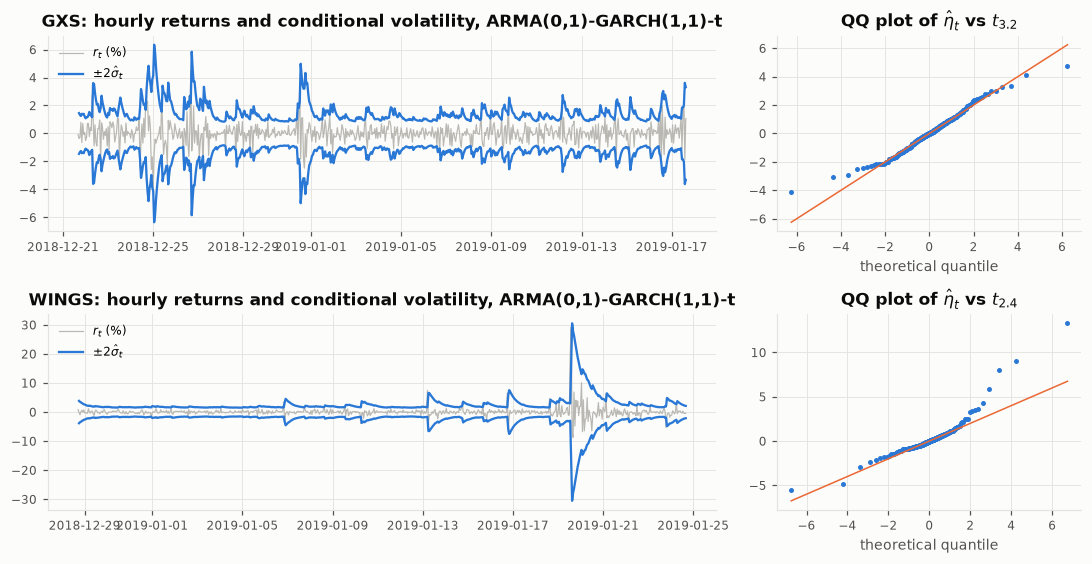

In [7]:
two = list(series)[:2]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
for i, coin in enumerate(two):
    r = series[coin]
    f = fits[coin]
    idx = r.index[-len(f.sigma):]
    axes[i, 0].plot(r.index, r.values, color="#b9b8b2", lw=0.8, label="$r_t$ (%)")
    axes[i, 0].plot(idx, 2 * f.sigma, color=SERIES[0], lw=1.5, label=r"$\pm2\hat\sigma_t$")
    axes[i, 0].plot(idx, -2 * f.sigma, color=SERIES[0], lw=1.5)
    axes[i, 0].set_title(f"{coin}: hourly returns and conditional volatility, ARMA({f.p},{f.q})-GARCH(1,1)-t")
    axes[i, 0].legend(loc="upper left")
    nu = f.params["nu"]
    q_th = st.t.ppf((np.arange(1, len(f.eta) + 1) - 0.5) / len(f.eta), nu) * np.sqrt((nu - 2) / nu)
    axes[i, 1].scatter(q_th, np.sort(f.eta), s=5, color=SERIES[0])
    lim = [q_th.min(), q_th.max()]
    axes[i, 1].plot(lim, lim, color=SERIES[1], lw=1)
    axes[i, 1].set_title(f"QQ plot of $\\hat\\eta_t$ vs $t_{{{nu:.1f}}}$")
    axes[i, 1].set_xlabel("theoretical quantile")
R.fig(fig, "garch_fit")
close(fig)

### 4. Interpretation (QUICK run; no QUICK/FULL difference in this notebook)

* **Prices are integrated, returns are stationary.** On log-prices ADF never rejects the unit root (0/10) and KPSS
  rejects level-stationarity for 8/10 coins. On returns ADF always rejects the unit root (10/10) and KPSS never
  rejects stationarity (0/10). The two tests agree, so hourly log-returns, not prices, are the object to model.
* **Linear and volatility dependence.** Ljung–Box on $r_t$ rejects for 9/10 coins. This dependence is short-lived:
  BIC selects low orders, mostly an MA(1) with a negative coefficient, the signature of bid–ask bounce on illiquid
  pairs. Ljung–Box on $r_t^2$ (9/10) and ARCH-LM (8/10) show strong volatility clustering, which justifies the GARCH
  layer.
* **GARCH parameters.** For most coins persistence reaches the boundary $\alpha+\beta\approx1$: on a 30-day window
  volatility behaves like an integrated GARCH, and the half-life of a volatility shock is longer than the window.
  For the others it lies between 0.70 and 0.99. $\hat\nu\approx3$ means extremely heavy tails, typical of small-cap
  coins quoted in BTC. A Gaussian model would flag many ordinary hours as anomalies, which is why II.A.2 uses
  Student innovations.
* **Adequacy.** After filtering, residuals are close to i.i.d. $t_\nu$. Ljung–Box on $\hat\eta_t$ does not reject for
  9/10 coins and on $\hat\eta_t^2$ for 10/10, and the KS test does not reject the fitted $t_\nu$ law for any coin.
  $\hat\eta_t$ is therefore a sound input for the sequential detector of II.A.2.

**Limitations.** Ten coins are a small sample. Calm periods of illiquid coins contain hours with no trade (zero
returns), which violate the continuous-innovation assumption; these hours were kept so as not to bias the
volatility estimates.

## II.A.2–3 — Sequential pump detection: CUSUM on GARCH residuals and abnormal volume, versus Isolation Forest

**Objective (brief II.A.2–3).**
1. Run a one-sided CUSUM on the standardised residuals $\hat\eta_t$ of an ARMA–GARCH model and on the abnormal
   volume $z^V_t$: $S_t=\max(0,\,S_{t-1}+u_t-k)$, alarm as soon as $S_t>h$, with $h$ calibrated by simulation of the
   in-control average run length $\mathrm{ARL}_0$.
2. Measure the detection rate, the false alarms per day and the detection delay. Does the alarm precede $\tau$?
3. Compare with an Isolation Forest.

**Design (per event).**
* *Training window* $[\tau-30\,\text{d},\ \tau-10\,\text{d})$, 480 hours: fit ARMA(0,1)–GARCH(1,1)–$t$ (the order most
  often selected in II.A.1) and the mean and standard deviation of $\log(1+V_t)$.
* *Monitoring window* $[\tau-10\,\text{d},\ \tau+3\,\text{h}]$: filter $\hat\eta_t$ and $z^V_t$ with the frozen
  parameters and run the detectors hour by hour. After an alarm the statistic is reset to 0.
* Alarms in $[\tau-10\,\text{d},\ \tau-72\,\text{h})$ are **false alarms** (the coin is not yet under pre-pump
  pressure, cf. I.3). An event is **detected** if an alarm fires in $[\tau-72\,\text{h},\ \tau+1\,\text{h}]$, and
  **detected early** if the alarm fires before $\tau$. The **delay** is $t_{\text{alarm}}-\tau$ in hours (negative
  means before the pump).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from sklearn.ensemble import IsolationForest

from pnd_paper import settings, tsmodels
from pnd_paper import stats as S
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IIA2_cusum_isolation_forest")
SZ = settings.SIZES
ARL0 = 720           # target in-control ARL: one false alarm per 30 days on average
KS_REF = [0.25, 0.5, 1.0]

ev_all = pd_log.binance_btc_events()
ev = (ev_all.assign(h=ev_all.timestamp.dt.floor("h")).sort_values("timestamp")
      .drop_duplicates(["symbol", "h"]).reset_index(drop=True))
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_, qv = panels["close"], panels["quote_volume"]

### 1. Per-event filtering

For event $i$ with return series $r_t$ (in %), the frozen model gives $\hat\eta_t=\hat\varepsilon_t/\hat\sigma_t$ on the
monitoring window (the GARCH recursion runs over training and monitoring hours without re-estimation), and
$z^V_t=(\log(1+V_t)-\hat\mu_V)/\hat\sigma_V$.

In [2]:
rng = np.random.default_rng(settings.SEED)
eligible = []
for e in ev.itertuples():
    if e.symbol not in close_.columns:
        continue
    t_star = universe.last_bar_before(e.timestamp)
    tr = close_[e.symbol].loc[e.timestamp - pd.Timedelta(days=30):e.timestamp - pd.Timedelta(days=10)]
    if len(tr) > 450 and tr.notna().mean() > 0.97 and (tr.diff() != 0).mean() > 0.6:
        eligible.append(e)
n_ev = len(eligible) if SZ.cusum_events is None else min(SZ.cusum_events, len(eligible))
sample = [eligible[i] for i in sorted(rng.choice(len(eligible), n_ev, replace=False))]

data = []
for e in sample:
    s = e.symbol
    start, split_t, end = e.timestamp - pd.Timedelta(days=30), e.timestamp - pd.Timedelta(days=10), e.timestamp + pd.Timedelta(hours=3)
    px = close_[s].loc[start:end].ffill()
    r = 100 * np.log(px).diff().fillna(0.0)
    lv = np.log1p(qv[s].loc[start:end].fillna(0.0))
    train = r.index < split_t
    fit = tsmodels.fit_arma_garch(r[train].values, 0, 1)
    eta_all, _ = tsmodels.filter_new(fit, r.values)
    eta = pd.Series(np.r_[np.full(len(r) - len(eta_all), np.nan), eta_all], index=r.index)
    zv = (lv - lv[train].mean()) / lv[train].std(ddof=1)
    mon = ~train
    data.append({"event": e, "fit": fit, "r": r[mon], "eta": eta[mon], "zv": zv[mon], "eta_train": eta[train].dropna(),
                 "zv_train": zv[train], "rel_h": ((r.index[mon] - e.timestamp) / pd.Timedelta(hours=1)).values,
                 "r_train": r[train]})
nus = np.array([d["fit"].params["nu"] for d in data])
md(f"{len(eligible)} events have a usable training window; {n_ev} are monitored "
   f"({'QUICK' if settings.QUICK else 'FULL'} run). Median fitted $\\hat\\nu={np.median(nus):.2f}$.")

404 events have a usable training window; 60 are monitored (QUICK run). Median fitted $\hat\nu=3.12$.

### 2. Calibration of $h$ by simulation of $\mathrm{ARL}_0$

The run length of a CUSUM started at 0 is $N=\inf\{t:S_t>h\}$; $\mathrm{ARL}_0(h,k)=\mathbb E_0[N]$ when the process is
in control. With in-control inputs $u_t$ simulated i.i.d. we estimate $\mathrm{ARL}_0$ by the mean run length over
$M$ simulated paths, and find $h$ such that $\widehat{\mathrm{ARL}}_0(h,k)=720$ hours by bisection
($\mathrm{ARL}_0$ is increasing in $h$).

* For $\hat\eta_t$ the in-control law is the standardised $t_{\hat\nu}$ with $\hat\nu$ the median over events.
* For $z^V_t$ there is no parametric law; we resample the pooled training values of $z^V$ (i.i.d. bootstrap).
  Serial correlation of volume makes the real $\mathrm{ARL}_0$ shorter than the simulated one, which shows up as
  extra false alarms; this is measured below rather than assumed away.

In [3]:
def run_lengths(sampler, h, k, M, cap):
    S_ = np.zeros(M)
    rl = np.full(M, cap, float)
    alive = np.ones(M, bool)
    for t in range(cap):
        S_ = np.maximum(0.0, S_ + sampler(M) - k)
        hit = alive & (S_ > h)
        rl[hit] = t + 1
        alive &= ~hit
        if not alive.any():
            break
    return rl


def calibrate(sampler, k, M, target=ARL0, lo=0.1, hi=40.0, iters=18):
    cap = 8 * target
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        arl = run_lengths(sampler, mid, k, M, cap).mean()
        lo, hi = (mid, hi) if arl < target else (lo, mid)
    return 0.5 * (lo + hi), arl


nu_med = float(np.median(nus))
pool_zv = np.concatenate([d["zv_train"].values for d in data])
samplers = {"eta": lambda M: tsmodels.simulate_t(nu_med, M, rng),
            "zV": lambda M: rng.choice(pool_zv, M)}
calib = []
for stat_name, smp in samplers.items():
    for k in KS_REF:
        h, arl = calibrate(smp, k, SZ.arl_sims)
        calib.append({"input": stat_name, "k": k, "h": h, "simulated ARL0": arl})
calib = pd.DataFrame(calib)
R.table(calib, "cusum_calibration", index=False)
show(calib.set_index(["input", "k"]))

### 3. Detection performance

For each detector we report, over the monitored events: the detection rate $\hat\pi=D/N$ with its exact
Clopper–Pearson 95 % interval (inverting the binomial test), the early-detection rate (alarm before $\tau$), the
false alarms per day in the calm part of the monitoring window, and the median delay.

In [4]:
def cusum_alarms(u, h, k):
    S_, out = 0.0, []
    for i, x in enumerate(u):
        S_ = max(0.0, S_ + (0.0 if np.isnan(x) else x) - k)
        if S_ > h:
            out.append(i)
            S_ = 0.0
    return np.array(out, int)


def evaluate(alarm_fn):
    det, early, delays, fa, calm_days = [], [], [], 0, 0.0
    for d in data:
        idx = alarm_fn(d)
        rel = d["rel_h"]
        calm = rel < -72
        fa += int(calm[idx].sum()) if len(idx) else 0
        calm_days += calm.sum() / 24
        win = idx[(rel[idx] >= -72) & (rel[idx] <= 1)] if len(idx) else idx
        det.append(len(win) > 0)
        early.append(len(win) > 0 and rel[win[0]] < 0)
        delays.append(rel[win[0]] if len(win) else np.nan)
    return np.array(det), np.array(early), np.array(delays), fa / calm_days


def summarise(name, det, early, delays, fa_day):
    ci = st.binomtest(int(det.sum()), len(det)).proportion_ci(method="exact")
    return {"detector": name, "detection rate": det.mean(), "CI low": ci.low, "CI high": ci.high,
            "early detection rate": early.mean(), "false alarms / day": fa_day,
            "median delay (h)": np.nanmedian(delays)}


results, hits = [], {}
for _, c in calib.iterrows():
    col = "eta" if c["input"] == "eta" else "zv"
    det, early, delays, fa = evaluate(lambda d, col=col, c=c: cusum_alarms(d[col].values, c["h"], c["k"]))
    name = f"CUSUM {c['input']} (k={c['k']})"
    results.append(summarise(name, det, early, delays, fa))
    hits[name] = (det, early, delays)
# combined detector: alarm when either CUSUM (k=0.5) fires
ce = calib[(calib.input == "eta") & (calib.k == 0.5)].iloc[0]
cz = calib[(calib.input == "zV") & (calib.k == 0.5)].iloc[0]
det, early, delays, fa = evaluate(lambda d: np.union1d(cusum_alarms(d["eta"].values, ce.h, 0.5), cusum_alarms(d["zv"].values, cz.h, 0.5)))
results.append(summarise("CUSUM eta OR zV (k=0.5)", det, early, delays, fa))
hits["CUSUM eta OR zV (k=0.5)"] = (det, early, delays)

#### Empirical calibration (serial dependence preserved)

The simulation above assumes i.i.d. inputs. Volume is strongly autocorrelated, so the simulated $h$ is too low for
$z^V$. A second calibration chooses $h$ so that the **empirical** alarm rate on the pooled *training* windows
(real series, serial dependence included) equals the nominal $24/\mathrm{ARL}_0$ per day. It uses no monitoring data,
so it is still an out-of-sample threshold.

In [5]:
def empirical_h(col_train, k, target=24 / ARL0, lo=0.1, hi=200.0, iters=25):
    series_ = [d[col_train].fillna(0).values for d in data]
    days = sum(len(s_) for s_ in series_) / 24
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        rate = sum(len(cusum_alarms(s_, mid, k)) for s_ in series_) / days
        lo, hi = (lo, mid) if rate < target else (mid, hi)
    return 0.5 * (lo + hi)


h_eta_emp = empirical_h("eta_train", 0.5)
h_zv_emp = empirical_h("zv_train", 0.5)
for name, col, h in (("CUSUM eta, empirical h (k=0.5)", "eta", h_eta_emp), ("CUSUM zV, empirical h (k=0.5)", "zv", h_zv_emp)):
    det, early, delays, fa = evaluate(lambda d, col=col, h=h: cusum_alarms(d[col].values, h, 0.5))
    results.append(summarise(name, det, early, delays, fa))
    hits[name] = (det, early, delays)
md(f"Empirical thresholds: $h_\\eta={h_eta_emp:.2f}$ (simulated: {ce.h:.2f}), $h_{{z^V}}={h_zv_emp:.2f}$ (simulated: {cz.h:.2f}).")

Empirical thresholds: $h_\eta=7.14$ (simulated: 5.79), $h_{z^V}=35.46$ (simulated: 7.66).

#### Isolation Forest

Isolation Forest (Liu et al., 2008) isolates points with random axis-parallel splits; anomalies need fewer splits.
With $h(x)$ the path length of $x$ in a tree and $c(n)=2H(n-1)-2(n-1)/n$ the average path length of an unsuccessful
search in a binary search tree of $n$ points, the anomaly score is
$$s(x)=2^{-\mathbb E[h(x)]/c(n)}\in(0,1],$$
close to 1 for anomalies. Features per hour: $r_t$, $|\hat\eta_t|$, $z^V_t$, and 6- and 24-hour rolling sums of
$r_t$ and rolling means of $z^V_t$. A single forest is trained on the pooled training windows of all events, and
its alarm threshold is the $1-1/720$ quantile of the training scores, which gives the same nominal false-alarm rate
as the CUSUMs. The hyperparameters `n_estimators` $\in\{100,300\}$ and `max_samples` $\in\{256, 1024\}$ are
chosen to minimise the false-alarm rate on the training events from the *train* split only.

In [6]:
def iso_features(r, eta, zv):
    f = pd.DataFrame({"r": r.values, "abs_eta": np.abs(eta.values), "zv": zv.values}, index=r.index)
    for w in (6, 24):
        f[f"r_sum_{w}"] = f.r.rolling(w, min_periods=1).sum()
        f[f"zv_mean_{w}"] = f.zv.rolling(w, min_periods=1).mean()
    return f.fillna(0.0)


train_feats = pd.concat([iso_features(d["r_train"], d["eta_train"].reindex(d["r_train"].index), d["zv_train"]) for d in data])
mon_feats = [iso_features(d["r"], d["eta"], d["zv"]) for d in data]
best = None
for n_est in (100, 300):
    for ms in (256, 1024):
        iso = IsolationForest(n_estimators=n_est, max_samples=ms, random_state=settings.SEED).fit(train_feats)
        thr = np.quantile(-iso.score_samples(train_feats), 1 - 1 / ARL0)
        fa_rate = np.mean([((-iso.score_samples(f[d["rel_h"] < -72]) > thr).mean())
                           for f, d in zip(mon_feats, data) if d["event"].split == "train"])
        if best is None or fa_rate < best[0]:
            best = (fa_rate, n_est, ms, iso, thr)
_, n_est, ms, iso, thr = best
det, early, delays, fa = evaluate(lambda d, i=None: np.where(-iso.score_samples(mon_feats[data.index(d)]) > thr)[0])
results.append(summarise(f"Isolation Forest (n={n_est}, max_samples={ms})", det, early, delays, fa))
hits["Isolation Forest"] = (det, early, delays)

res = pd.DataFrame(results).set_index("detector")
R.table(res, "detection_performance")
show(res, "{:.3f}")

,detection rate,CI low,CI high,early detection rate,false alarms / day,median delay (h)
detector,,,,,,
CUSUM eta (k=0.25),0.467,0.337,0.600,0.450,0.079,-2.504
CUSUM eta (k=0.5),0.433,0.306,0.568,0.400,0.074,-4.253
CUSUM eta (k=1.0),0.367,0.246,0.501,0.350,0.069,-1.003
CUSUM zV (k=0.25),0.733,0.603,0.839,0.667,0.400,-11.469
CUSUM zV (k=0.5),0.717,0.586,0.825,0.650,0.388,-6.004
CUSUM zV (k=1.0),0.700,0.568,0.812,0.633,0.293,-1.001
CUSUM eta OR zV (k=0.5),0.767,0.640,0.866,0.750,0.448,-13.981
"CUSUM eta, empirical h (k=0.5)",0.333,0.217,0.467,0.317,0.052,-1.002
"CUSUM zV, empirical h (k=0.5)",0.133,0.059,0.246,0.117,0.055,-55.744


#### Paired comparison of detectors

The same events are monitored by all detectors, so detection indicators are paired. The exact McNemar test uses
the discordant counts $n_{10}$ (detected by A only) and $n_{01}$ (B only): under $H_0$ "equal detection
probability", $n_{10}\mid n_{10}+n_{01}\sim\mathrm{Bin}(n_{10}+n_{01},1/2)$.

In [7]:
nominal_day = 24 / ARL0
fair = res[(~res.index.str.startswith("Isolation")) & (res["false alarms / day"] <= 3 * nominal_day)]
best_cusum = fair["detection rate"].idxmax()
m = S.mcnemar(hits[best_cusum][0], hits["Isolation Forest"][0])
md(f"Among CUSUM variants whose observed false-alarm rate stays within three times the nominal rate, the best "
   f"detection rate is achieved by **{best_cusum}** ({res.loc[best_cusum, 'detection rate']:.1%}, "
   f"{res.loc[best_cusum, 'false alarms / day']:.3f} false alarms/day) versus Isolation Forest "
   f"({res.filter(like='Isolation', axis=0)['detection rate'].iloc[0]:.1%}). McNemar: $n_{{10}}={m['n10']}$, "
   f"$n_{{01}}={m['n01']}$, ${S.fmt_p(m['p'])}$ → {S.decision(m['p'])}.")
nominal = 24 / ARL0
md(f"Nominal false-alarm rate implied by $\\mathrm{{ARL}}_0=720$ h: {nominal:.3f} per day.")

Among CUSUM variants whose observed false-alarm rate stays within three times the nominal rate, the best detection rate is achieved by **CUSUM eta (k=0.25)** (46.7%, 0.079 false alarms/day) versus Isolation Forest (23.3%). McNemar: $n_{10}=16$, $n_{01}=2$, $p=0.001$ → reject $H_0$ at $\alpha=0.05$.

Nominal false-alarm rate implied by $\mathrm{ARL}_0=720$ h: 0.033 per day.

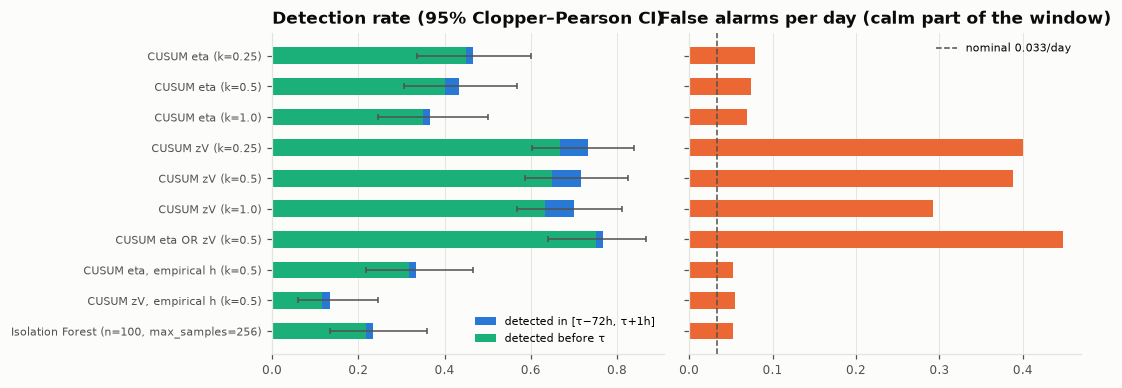

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
names = res.index.tolist()
y = np.arange(len(names))
axes[0].barh(y, res["detection rate"], color=SERIES[0], height=0.55, label="detected in [τ−72h, τ+1h]")
axes[0].barh(y, res["early detection rate"], color=SERIES[2], height=0.55, label="detected before τ")
axes[0].errorbar(res["detection rate"], y, xerr=[res["detection rate"] - res["CI low"], res["CI high"] - res["detection rate"]],
                 fmt="none", ecolor="#52514e", capsize=2, lw=1)
axes[0].set_yticks(y, names, fontsize=7)
axes[0].invert_yaxis()
axes[0].set_title("Detection rate (95% Clopper–Pearson CI)")
axes[0].legend(loc="lower right", fontsize=7)
axes[0].grid(axis="y", visible=False)
axes[1].barh(y, res["false alarms / day"], color=SERIES[1], height=0.55)
axes[1].axvline(nominal, color="#52514e", ls="--", lw=1, label=f"nominal {nominal:.3f}/day")
axes[1].set_yticks(y, [""] * len(names))
axes[1].invert_yaxis()
axes[1].set_title("False alarms per day (calm part of the window)")
axes[1].legend(fontsize=7)
axes[1].grid(axis="y", visible=False)
R.fig(fig, "detection_vs_false_alarms")
close(fig)

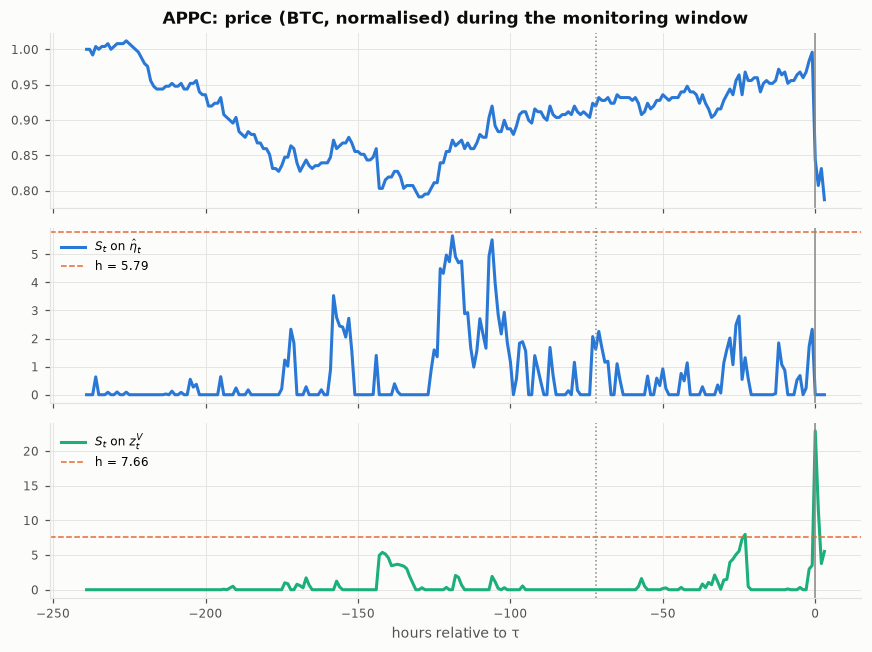

In [9]:
d0 = max(data, key=lambda d: d["zv"].iloc[-6:].max())
e0 = d0["event"]
Se, Sz = [], []
s1 = s2 = 0.0
for a, b in zip(d0["eta"].fillna(0).values, d0["zv"].values):
    s1 = max(0.0, s1 + a - 0.5)
    s2 = max(0.0, s2 + b - 0.5)
    Se.append(s1)
    Sz.append(s2)
    s1 = 0.0 if s1 > ce.h else s1
    s2 = 0.0 if s2 > cz.h else s2
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
axes[0].plot(d0["rel_h"], np.exp(np.cumsum(d0["r"].values / 100)), color=SERIES[0])
axes[0].set_title(f"{e0.coin}: price (BTC, normalised) during the monitoring window")
axes[1].plot(d0["rel_h"], Se, color=SERIES[0], label=r"$S_t$ on $\hat\eta_t$")
axes[1].axhline(ce.h, color=SERIES[1], ls="--", lw=1, label=f"h = {ce.h:.2f}")
axes[1].legend(loc="upper left")
axes[2].plot(d0["rel_h"], Sz, color=SERIES[2], label=r"$S_t$ on $z^V_t$")
axes[2].axhline(cz.h, color=SERIES[1], ls="--", lw=1, label=f"h = {cz.h:.2f}")
axes[2].legend(loc="upper left")
axes[2].set_xlabel("hours relative to τ")
for a in axes:
    a.axvline(-72, color="#8a8985", lw=1, ls=":")
    a.axvline(0, color="#8a8985", lw=1)
R.fig(fig, "example_event")
close(fig)

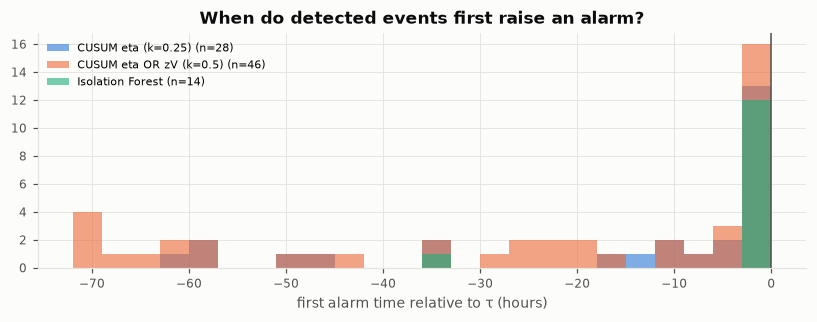

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3))
for i, name in enumerate([best_cusum, "CUSUM eta OR zV (k=0.5)", "Isolation Forest"]):
    dl = hits[name][2]
    dl = dl[np.isfinite(dl)]
    ax.hist(dl, bins=np.arange(-72, 3, 3), alpha=0.6, color=SERIES[i], label=f"{name} (n={len(dl)})")
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("first alarm time relative to τ (hours)")
ax.set_title("When do detected events first raise an alarm?")
ax.legend(fontsize=7)
R.fig(fig, "delays")
close(fig)

### 4. Interpretation (QUICK run: 60 events, 200 ARL simulations)

* **Calibration matters as much as the detector.** With $h$ simulated under i.i.d. inputs, the CUSUM on $\hat\eta_t$
  keeps close to its nominal false-alarm rate (0.07–0.08 per day against 0.033 nominal): GARCH filtering removes
  most of the dependence, as II.A.1 showed. The CUSUM on $z^V_t$ produces about 0.4 false alarms per day, twelve
  times the nominal rate, because volume is strongly autocorrelated and the i.i.d. simulation understates the
  in-control run length. With the threshold calibrated on the real training series, $h_{z^V}$ rises from about 7.7
  to 35, and the false alarms fall to the nominal level. So does detection, to 13 %.
* **At comparable false-alarm rates the residual CUSUM is the best detector.** CUSUM on $\hat\eta_t$ with $k=0.25$
  detects about 47 % of pumps in the 72 hours before $\tau$ (95 % CI 34–60 %), and most of these alarms fire
  **before** the announcement (45 % of events), with a median lead of 2–4 hours. Isolation Forest, calibrated to the
  same nominal rate, detects 23 %. The exact McNemar test rejects equal detection ($p\approx0.001$; 16 events
  detected only by CUSUM against 2 only by the forest).
* **Does the alarm precede $\tau$?** Often, but only by a few hours. The alarms track the last part of the
  pre-pump drift found in I.3 (abnormal returns and volume in the last 6–24 hours), not the slow accumulation 2–3
  days before, which is too gradual to be told apart from noise hour by hour. A surveillance desk would get a lead
  of a few hours on roughly 40 % of pumps, at the price of about one false alarm per coin every two weeks.
* **Smaller $k$ helps.** CUSUM is optimal for detecting a shift of size $2k$ in the mean. Pre-pump shifts in
  $\hat\eta_t$ are small and persistent, so $k=0.25$ beats $k=1$.
* **Why the forest does worse.** Isolation Forest scores each hour separately and has no memory, so it cannot
  accumulate weak evidence over consecutive hours as CUSUM does. It mostly flags the pump hour itself (median delay
  about 0 h).

**Limitations.** False-alarm rates observed in the monitoring window exceed their nominal value even for the
residual CUSUM: the 20-day training window does not capture every regime of the following 10 days. "Calm" hours
10 to 3 days before the pump are assumed free of manipulation, although some insiders may already be active (I.3
found no significant drift that early). With 60 events (QUICK run) the intervals are wide.

## II.B — Machine learning for target-coin ranking

**Objective (brief II.B).** One hour before a pump, rank the coins of the exchange by their probability of being
the target.
1. Describe every (event, candidate) pair with four feature families: coin (CoinGecko, 3 days before), market
   (returns and volumes on $[\tau-(x+1)\,\text{h},\ \tau-1\,\text{h}]$), channel history, and interactions such as the
   distance to the barycentre of the channel's past targets.
2. Train a logistic regression, a random forest and LightGBM, and handle the imbalance (about 0.5 % positives) by
   class weighting, undersampling, or a softmax loss computed per event.
3. Evaluate with HR@$k$ and AUC-PR, interpret with SHAP values, and compare the two best models with McNemar's
   test or a paired bootstrap.

**Protocol (brief, mandatory).** Chronological split identical to [A1]: train $\tau<$ 2021-01-19, validation up to
2021-05-10, test afterwards. Every feature is computable at $\tau-1$ h. Hyperparameters are chosen on validation;
the selected model is refit on train + validation and the test set is used **once**. Results are averaged over
seeds (2 in the QUICK run, 5 in the full run) and reported as mean ± standard deviation.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import shap
from scipy import optimize
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pnd_paper import settings, metrics
from pnd_paper import stats as S
from pnd_paper import ranking_dataset as rd
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
settings.seed_everything()
R = Reporter("IIB_machine_learning")
SZ = settings.SIZES

### 1. The ranking dataset

For event $i$ (channel $h_i$, target $c^\star_i$, time $\tau_i$) the candidate set $\mathcal C_i$ contains the Binance
BTC-quoted coins trading during the 72 hours before $\tau_i-1$ h (see I.0). Each pair $(i,c)$, $c\in\mathcal C_i$, is a
row with label $y_{ic}=\mathbf 1\{c=c^\star_i\}$. Notation: $t_i$ is the last complete hourly bar before
$\tau_i-1$ h, $P$ the close price in BTC and $Q$ the quote volume.

| family | features |
|---|---|
| coin (CoinGecko, $\tau-3$ d) | $\log$ market cap (USD, BTC), $\log$ price, $\log$ volume, $\log(1+\text{Twitter})$, $\log(1+\text{Reddit})$, $\log$ Alexa rank |
| market, $x\in\{1,3,6,12,24,48,60,72\}$ | $r^{(x)}=\log P_{t}-\log P_{t-x}$; $\log(1+\sum_{s=t-x+1}^{t}Q_s)$; relative volume $\log\big(\bar Q_{(x)}/\bar Q_{[t-30\text{d},t-72\text{h}]}\big)$; 24 h volatility, taker-buy share, max hourly return over 72 h, $\log P_t$ |
| channel history (before $\tau-1$ h) | number of past pumps of the channel; pumps of $c$ by the channel and by all channels (all time, 30 days); $\log$ hours since the last pump of $c$ |
| interaction | $\lVert\boldsymbol z_c-\bar{\boldsymbol z}_{h}\rVert_2$, distance from $c$'s standardised coin vector to the barycentre of the channel's past targets; $|\log\text{mcap}_c-\overline{\log\text{mcap}}_{h}|$ |

In [2]:
ev = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
df = rd.build(ev, panels).sort_values(["event_id", "symbol"]).reset_index(drop=True)
FEATS = rd.feature_columns(df)
FAMILY = {f: {"g": "coin", "m": "market", "h": "history", "i": "interaction"}[f[0]] for f in FEATS}
sizes = df.groupby("split").agg(events=("event_id", "nunique"), rows=("label", "size"), positives=("label", "sum"))
sizes["positive ratio"] = sizes.positives / sizes.rows
sizes = sizes.reindex(["train", "valid", "test"])
sizes.loc["paper [A1] (Table 4)"] = [np.nan, 196_613 / 1, 948, 0.0048]
sizes.loc["paper [A1] (Table 4)", "events"] = 948
R.table(sizes, "dataset_sizes")
show(sizes, "{:.4g}")
md(f"{len(FEATS)} features. Events per split: train {sizes.loc['train', 'events']:.0f}, valid "
   f"{sizes.loc['valid', 'events']:.0f}, test {sizes.loc['test', 'events']:.0f}; the paper reports 648 / 100 / 200 positives "
   "(Table 4), so our population matches the paper's almost exactly.")

,events,rows,positives,positive ratio
split,,,,
train,648,1.104e+05,648,0.005867
valid,100,2.516e+04,100,0.003974
test,199,5.711e+04,199,0.003485
paper [A1] (Table 4),948,1.966e+05,948,0.0048


46 features. Events per split: train 648, valid 100, test 199; the paper reports 648 / 100 / 200 positives (Table 4), so our population matches the paper's almost exactly.

#### Leakage checks

* **Time.** Market features end at $t_i$ (before $\tau_i-1$ h); history features use pumps before $\tau_i-1$ h only.
* **Relays.** A pump announced late by a relay channel could reveal a pump that already happened. Only a handful of
  targets were pumped by another channel in the 24 hours before (table below), so this channel of leakage is
  negligible.
* **Source asymmetry.** Target coins' CoinGecko records come from one file and candidates' from another; a feature
  whose missingness differs between labels would let a model identify the source rather than the target. The table
  lists missing rates by label.

In [3]:
tg = df[df.label == 1]
rec = np.expm1(tg.h_gl_cand_recency)
leak = pd.DataFrame({"targets pumped by any channel in the previous 24 h": [(rec <= 24).sum()],
                     "targets pumped before (any channel, any time)": [(tg.h_gl_cand_count > 0).mean()],
                     "targets pumped before by the same channel": [(tg.h_ch_cand_count > 0).mean()]}).T
show(leak.rename(columns={0: "value"}), "{:.3f}")
miss = df.groupby("label")[FEATS].apply(lambda d: d.isna().mean()).T
miss.columns = ["missing (candidates)", "missing (targets)"]
miss = miss[(miss.max(axis=1) > 0)]
R.table(miss, "missingness_by_label")
show(miss, "{:.3f}")
md("Missingness is similar for targets and candidates (largest gap: Reddit, a few points), so the CoinGecko "
   "source does not reveal the label. The share of targets already pumped before (re-pumps) is the paper's main "
   "regularity: [A1] reports a 60.1 % re-pump probability.")

,value
targets pumped by any channel in the previous 24 h,12.000
"targets pumped before (any channel, any time)",0.740
targets pumped before by the same channel,0.200


,missing (candidates),missing (targets)
g_log_mcap_usd,0.102,0.121
g_log_mcap_btc,0.102,0.121
g_log_price_usd,0.076,0.067
g_log_price_btc,0.076,0.067
g_log_vol_usd,0.076,0.067
g_log_vol_btc,0.076,0.067
g_log_twitter,0.219,0.184
g_log_reddit,0.318,0.265
g_log_alexa,0.107,0.131
m_ret_1h,0.001,0.001


Missingness is similar for targets and candidates (largest gap: Reddit, a few points), so the CoinGecko source does not reveal the label. The share of targets already pumped before (re-pumps) is the paper's main regularity: [A1] reports a 60.1 % re-pump probability.

### 2. Models and imbalance strategies

Let $s_\theta(i,c)$ be the score of candidate $c$ for event $i$.

* **Logistic regression (LR).** $P(y=1\mid x)=\sigma(w^\top x+b)$, loss
  $-\sum_{ic}\omega_{y}\,[y\log\sigma+(1-y)\log(1-\sigma)]+\frac{1}{2C}\lVert w\rVert^2$, with median imputation plus
  missing indicators and standardisation.
* **Conditional logit (LR-softmax).** The per-event softmax loss of the brief,
  $$\mathcal L=-\sum_i\log\frac{e^{s(c^\star_i)}}{\sum_{c\in\mathcal C_i}e^{s(c)}},\qquad s(c)=w^\top x_{ic},$$
  compares the target only with its own competitors, which removes the imbalance problem: every event contributes
  exactly one term. It is fitted with L-BFGS on the analytic gradient
  $\nabla_w\mathcal L=\sum_i\big(\sum_c p_{ic}x_{ic}-x_{ic^\star_i}\big)+\lambda w$.
* **Random forest (RF)** of CART trees (Gini impurity), bootstrap samples and random feature subsets.
* **LightGBM**, gradient-boosted trees; with the binary loss or with the per-event softmax loss as a custom objective
  (gradient $p_{ic}-y_{ic}$, Hessian $p_{ic}(1-p_{ic})$ per event).

**Imbalance.** Class weights $\omega_1/\omega_0=n_0/n_1$ ("balanced"); random undersampling of negatives to $r$ per
positive in each training event; or the softmax loss. For LR, RF and binary LightGBM the strategy is itself a
hyperparameter of the search.

**Hyperparameter search.** Optuna's TPE sampler (a sequential Bayesian optimiser modelling $p(\theta\mid\text{good})$
against $p(\theta\mid\text{bad})$) maximises the validation MRR $=\frac1N\sum_i 1/\rho_i$, a smooth summary of the
whole ranking. The search spaces are much wider than the paper's (it gives none). Number of trials per model:

In [4]:
md(f"**{SZ.optuna_trials} trials** per model ({'QUICK' if settings.QUICK else 'FULL'} run).")
train, valid, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "valid", "test"))
trval = pd.concat([train, valid], ignore_index=True)


def undersample(d, ratio, seed):
    if ratio is None:
        return d
    rng = np.random.default_rng(seed)
    key = rng.random(len(d))
    neg = d.label.values == 0
    rank = pd.Series(np.where(neg, key, -1.0)).groupby(d.event_id.values).rank(method="first")
    keep = (~neg) | (rank.values <= ratio)
    return d[keep].reset_index(drop=True)


def evaluate(d, scores):
    out = d[["event_id", "label"]].copy()
    out["score"] = scores
    return metrics.ranking_report(out), out


# ---------- LR
def fit_lr(d, prm, seed):
    d = undersample(d, prm["ratio"], seed)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(C=prm["C"], class_weight=prm["cw"], max_iter=2000))
    return model.fit(d[FEATS], d.label)


def lr_space(t):
    return {"C": t.suggest_float("C", 1e-4, 1e2, log=True), "cw": t.suggest_categorical("cw", [None, "balanced"]),
            "ratio": t.suggest_categorical("ratio", [None, 5, 20, 50])}


# ---------- conditional logit
class CondLogit:
    def __init__(self, lam):
        self.lam = lam

    def fit(self, d):
        self.prep = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()).fit(d[FEATS])
        X = self.prep.transform(d[FEATS])
        X = np.c_[X]
        starts = np.r_[0, np.flatnonzero(np.diff(d.event_id.values)) + 1]
        pos = np.flatnonzero(d.label.values == 1)
        G = len(starts)

        def f(w):
            s = X @ w
            mx = np.maximum.reduceat(s, starts)
            e = np.exp(s - np.repeat(mx, np.diff(np.r_[starts, len(s)])))
            Z = np.add.reduceat(e, starts)
            lse = mx + np.log(Z)
            p = e / np.repeat(Z, np.diff(np.r_[starts, len(s)]))
            loss = (lse.sum() - s[pos].sum()) / G + 0.5 * self.lam * w @ w
            grad = (X.T @ p - X[pos].sum(0)) / G + self.lam * w
            return loss, grad

        self.w = optimize.minimize(f, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", options={"maxiter": 500}).x
        return self

    def score(self, d):
        return self.prep.transform(d[FEATS]) @ self.w


def fit_cl(d, prm, seed):
    return CondLogit(prm["lam"]).fit(d)


def cl_space(t):
    return {"lam": t.suggest_float("lam", 1e-6, 1.0, log=True)}


# ---------- RF
def fit_rf(d, prm, seed):
    d = undersample(d, prm["ratio"], seed)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                          RandomForestClassifier(n_estimators=prm["n"], max_depth=prm["depth"], min_samples_leaf=prm["leaf"],
                                                 max_features=prm["mf"], class_weight=prm["cw"], n_jobs=-1, random_state=seed))
    return model.fit(d[FEATS], d.label)


def rf_space(t):
    return {"n": t.suggest_int("n", 100, 600, step=100), "depth": t.suggest_categorical("depth", [4, 8, 12, 16, 24, None]),
            "leaf": t.suggest_int("leaf", 1, 200, log=True), "mf": t.suggest_categorical("mf", ["sqrt", 0.2, 0.4, 0.7]),
            "cw": t.suggest_categorical("cw", [None, "balanced_subsample"]), "ratio": t.suggest_categorical("ratio", [5, 20, 50])}


# ---------- LightGBM
def softmax_obj(preds, data):
    y = data.get_label()
    grp = data.get_group()
    starts = np.r_[0, np.cumsum(grp)[:-1]].astype(int)
    lens = np.asarray(grp, int)
    mx = np.maximum.reduceat(preds, starts)
    e = np.exp(preds - np.repeat(mx, lens))
    p = e / np.repeat(np.add.reduceat(e, starts), lens)
    return p - y, np.maximum(p * (1 - p), 1e-6)


def fit_lgb(d, prm, seed, objective="binary"):
    if objective == "binary":
        d = undersample(d, prm.get("ratio"), seed)
    params = {"learning_rate": prm["lr"], "num_leaves": prm["leaves"], "min_child_samples": prm["mcs"],
              "feature_fraction": prm["ff"], "bagging_fraction": prm["bf"], "bagging_freq": 1, "lambda_l2": prm["l2"],
              "lambda_l1": prm["l1"], "max_depth": -1, "verbose": -1, "seed": seed, "num_threads": 0}
    if objective == "binary":
        params["objective"] = "binary"
        if prm.get("spw"):
            params["scale_pos_weight"] = (d.label == 0).sum() / max((d.label == 1).sum(), 1)
        ds = lgb.Dataset(d[FEATS], d.label)
    else:
        params["objective"] = softmax_obj
        ds = lgb.Dataset(d[FEATS], d.label, group=d.groupby("event_id", sort=False).size().values)
    return lgb.train(params, ds, num_boost_round=prm["n"])


def lgb_space(t, objective="binary"):
    prm = {"lr": t.suggest_float("lr", 0.005, 0.3, log=True), "leaves": t.suggest_int("leaves", 4, 128, log=True),
           "mcs": t.suggest_int("mcs", 5, 500, log=True), "ff": t.suggest_float("ff", 0.3, 1.0),
           "bf": t.suggest_float("bf", 0.4, 1.0), "l2": t.suggest_float("l2", 1e-8, 10.0, log=True),
           "l1": t.suggest_float("l1", 1e-8, 10.0, log=True), "n": t.suggest_int("n", 50, 1000, log=True)}
    if objective == "binary":
        prm["ratio"] = t.suggest_categorical("ratio", [None, 5, 20, 50])
        prm["spw"] = t.suggest_categorical("spw", [False, True])
    return prm


def predict(model, d):
    if isinstance(model, CondLogit):
        return model.score(d)
    if isinstance(model, lgb.Booster):
        return model.predict(d[FEATS], raw_score=True)
    return model.predict_proba(d[FEATS])[:, 1]


MODELS = {
    "LR": (fit_lr, lr_space),
    "LR-softmax": (fit_cl, cl_space),
    "RF": (fit_rf, rf_space),
    "LightGBM": (lambda d, p, s: fit_lgb(d, p, s, "binary"), lambda t: lgb_space(t, "binary")),
    "LightGBM-softmax": (lambda d, p, s: fit_lgb(d, p, s, "softmax"), lambda t: lgb_space(t, "softmax")),
}

**25 trials** per model (QUICK run).

### 3. Hyperparameter search on the validation set

In [5]:
best_params, search_hist = {}, {}
for name, (fit, space) in MODELS.items():
    def objective(trial, fit=fit, space=space):
        prm = space(trial)
        model = fit(train, prm, settings.SEED)
        rep, _ = evaluate(valid, predict(model, valid))
        trial.set_user_attr("HR@10", rep["HR@10"])
        return rep["MRR"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=settings.SEED))
    study.optimize(objective, n_trials=SZ.optuna_trials if name != "LR-softmax" else max(10, SZ.optuna_trials // 2))
    best_params[name] = study.best_params
    search_hist[name] = study.trials_dataframe()[["number", "value", "user_attrs_HR@10"]]
search = pd.DataFrame({n: {"best validation MRR": search_hist[n].value.max(),
                           "validation HR@10 at best": search_hist[n].loc[search_hist[n].value.idxmax(), "user_attrs_HR@10"],
                           "trials": len(search_hist[n]), "best hyperparameters": str(best_params[n])} for n in MODELS}).T
R.table(search, "hyperparameter_search")
show(search)

,best validation MRR,validation HR@10 at best,trials,best hyperparameters
LR,0.2715,0.56,25,"{'C': 0.005715545708399059, 'cw': None, 'ratio': 5}"
LR-softmax,0.271,0.56,12,{'lam': 0.18013404791374119}
RF,0.2491,0.41,25,"{'n': 600, 'depth': 16, 'leaf': 102, 'mf': 0.7, 'cw': None, 'ratio': 5}"
LightGBM,0.1604,0.33,25,"{'lr': 0.005780963646032276, 'leaves': 74, 'mcs': 7, 'ff': 0.5499781777768239, 'bf': 0.8132973726583357, 'l2': 0.008696106668306851, 'l1': 3.073142992167156e-07, 'n': 265, 'ratio': 5, 'spw': True}"
LightGBM-softmax,0.2022,0.43,25,"{'lr': 0.16359657166149869, 'leaves': 78, 'mcs': 118, 'ff': 0.9044404688162424, 'bf': 0.5492267840615412, 'l2': 0.00035839155722047425, 'l1': 3.070364563117169e-08, 'n': 84}"


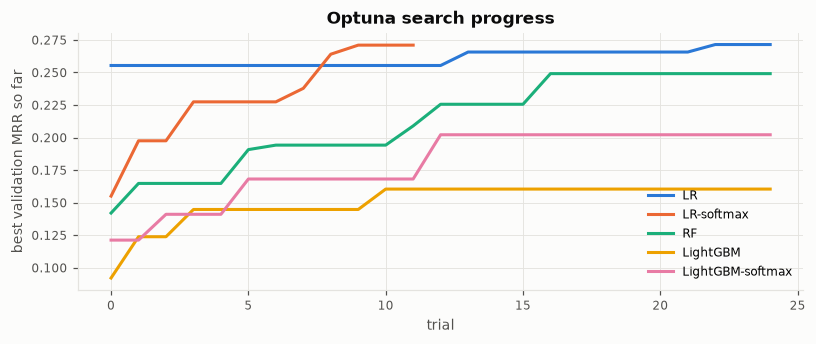

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, (n, h) in enumerate(search_hist.items()):
    ax.plot(h.number, h.value.cummax(), color=SERIES[i], label=n)
ax.set_xlabel("trial")
ax.set_ylabel("best validation MRR so far")
ax.set_title("Optuna search progress")
ax.legend()
R.fig(fig, "search_progress")
close(fig)

### 4. Test-set evaluation (refit on train + validation, one pass on test)

HR@$k=\frac1N\sum_i\mathbf 1\{\rho_i\le k\}$ with $\rho_i$ the rank of the true target among $\mathcal C_i$ (ties
counted as half), AUC-PR (average precision, the area under the precision–recall curve of all pairs pooled) and
ROC-AUC. A random ranking gives $\mathbb E[\mathrm{HR}@k]=\frac1N\sum_i\min(k,|\mathcal C_i|)/|\mathcal C_i|$.

In [7]:
seeds = [settings.SEED + s for s in range(SZ.seeds)]
test_reports, test_scores = {}, {}
for name, (fit, _) in MODELS.items():
    reps = []
    for sd in seeds:
        model = fit(trval, dict(best_params[name]) if name != "LR" else {**best_params[name]}, sd)
        rep, sc = evaluate(test, predict(model, test))
        reps.append(rep)
        if sd == seeds[0]:
            test_scores[name] = sc
            if name == "LightGBM-softmax":
                lgb_final = model
            if name == "LR":
                lr_final = model
    test_reports[name] = pd.DataFrame(reps)
rand = metrics.random_baseline(test)
cols = [f"HR@{k}" for k in settings.HR_KS] + ["MRR", "AUC-PR", "AUC"]
mean = pd.DataFrame({n: r[cols].mean() for n, r in test_reports.items()}).T
std = pd.DataFrame({n: r[cols].std(ddof=1) for n, r in test_reports.items()}).T.fillna(0.0)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
table.loc["random ranking"] = pd.Series({**{k: f"{v:.3f}" for k, v in rand.items()}, "MRR": "", "AUC-PR": "", "AUC": "0.5"})
R.table(mean, "test_mean")
R.table(std, "test_std")
R.table(table, "test_table")
show(table)

,HR@1,HR@3,HR@5,HR@10,HR@20,HR@30,MRR,AUC-PR,AUC
LR,0.085 ± 0.043,0.284 ± 0.011,0.372 ± 0.028,0.543 ± 0.007,0.751 ± 0.025,0.819 ± 0.007,0.232 ± 0.022,0.055 ± 0.002,0.911 ± 0.001
LR-softmax,0.131 ± 0.0,0.246 ± 0.0,0.317 ± 0.0,0.528 ± 0.0,0.769 ± 0.0,0.824 ± 0.0,0.247 ± 0.0,0.057 ± 0.0,0.91 ± 0.0
RF,0.153 ± 0.039,0.319 ± 0.004,0.41 ± 0.025,0.535 ± 0.011,0.678 ± 0.057,0.799 ± 0.007,0.278 ± 0.015,0.114 ± 0.022,0.904 ± 0.002
LightGBM,0.143 ± 0.004,0.334 ± 0.039,0.405 ± 0.032,0.603 ± 0.028,0.736 ± 0.025,0.822 ± 0.025,0.291 ± 0.007,0.115 ± 0.007,0.917 ± 0.001
LightGBM-softmax,0.098 ± 0.053,0.183 ± 0.082,0.244 ± 0.082,0.339 ± 0.06,0.533 ± 0.071,0.621 ± 0.089,0.186 ± 0.064,0.042 ± 0.028,0.866 ± 0.041
random ranking,0.003,0.010,0.017,0.035,0.070,0.105,,,0.5


#### Comparison with [A1] (Table 5, test set)

,ours HR@1,[A1] HR@1,ours HR@10,[A1] HR@10,ours HR@30,[A1] HR@30
model,,,,,,
LR,0.085,0.156,0.543,0.449,0.819,0.662
RF,0.153,0.189,0.535,0.537,0.799,0.731
LightGBM,0.143,nan,0.603,nan,0.822,nan
LightGBM-softmax,0.098,nan,0.339,nan,0.621,nan
LR-softmax,0.131,nan,0.528,nan,0.824,nan


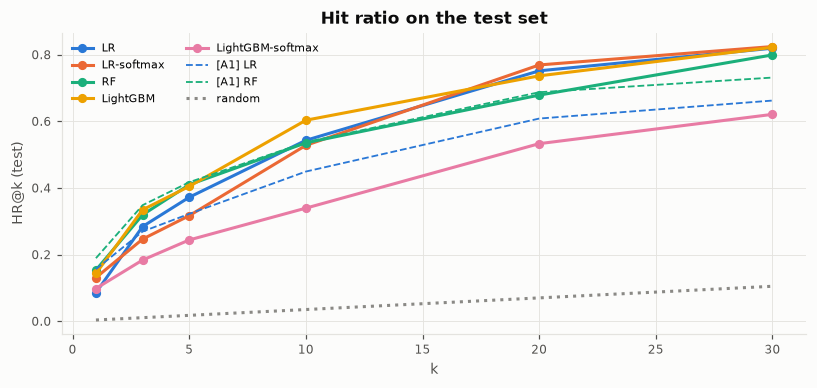

In [8]:
paper = settings.PAPER_TABLE5[["LR", "RF"]].T
cmp_rows = []
for ours, theirs in (("LR", "LR"), ("RF", "RF"), ("LightGBM", None), ("LightGBM-softmax", None), ("LR-softmax", None)):
    row = {"model": ours}
    for k in (1, 3, 5, 10, 20, 30):
        row[f"ours HR@{k}"] = mean.loc[ours, f"HR@{k}"]
        row[f"[A1] HR@{k}"] = paper.loc[theirs, f"HR@{k}"] if theirs else np.nan
    cmp_rows.append(row)
cmp_tab = pd.DataFrame(cmp_rows).set_index("model")
R.table(cmp_tab, "comparison_with_paper")
show(cmp_tab[[c for c in cmp_tab.columns if "@1" in c and "@10" not in c] + [c for c in cmp_tab.columns if "@10" in c]
             + [c for c in cmp_tab.columns if "@30" in c]], "{:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ks = list(settings.HR_KS)
for i, n in enumerate(MODELS):
    ax.plot(ks, [mean.loc[n, f"HR@{k}"] for k in ks], marker="o", color=SERIES[i], label=n)
ax.plot(ks, settings.PAPER_TABLE5["LR"].values, ls="--", color=SERIES[0], lw=1.2, label="[A1] LR")
ax.plot(ks, settings.PAPER_TABLE5["RF"].values, ls="--", color=SERIES[2], lw=1.2, label="[A1] RF")
ax.plot(ks, [rand[f"HR@{k}"] for k in ks], ls=":", color="#8a8985", label="random")
ax.set_xlabel("k")
ax.set_ylabel("HR@k (test)")
ax.set_title("Hit ratio on the test set")
ax.legend(ncol=2, fontsize=7)
R.fig(fig, "hr_curves")
close(fig)

### 5. Imbalance strategies (LightGBM, best tree parameters fixed)

Holding the tree hyperparameters of the best softmax model fixed, we change only the way imbalance is handled and
report the **validation** metrics (the test set is not used for this choice).

In [9]:
base = {k: v for k, v in best_params["LightGBM-softmax"].items()}
strategies = {"binary, no correction": {**base, "ratio": None, "spw": False},
              "binary, class weights": {**base, "ratio": None, "spw": True},
              "binary, undersampling 1:20": {**base, "ratio": 20, "spw": False},
              "binary, undersampling 1:5": {**base, "ratio": 5, "spw": False}}
imb = {n: evaluate(valid, predict(fit_lgb(train, p, settings.SEED, "binary"), valid))[0] for n, p in strategies.items()}
imb["per-event softmax"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
imb = pd.DataFrame(imb).T[["HR@1", "HR@5", "HR@10", "HR@30", "MRR", "AUC-PR"]]
R.table(imb, "imbalance_strategies")
show(imb, "{:.3f}")

,HR@1,HR@5,HR@10,HR@30,MRR,AUC-PR
"binary, no correction",0.000,0.120,0.170,0.460,0.070,0.013
"binary, class weights",0.040,0.070,0.130,0.340,0.070,0.016
"binary, undersampling 1:20",0.070,0.130,0.190,0.430,0.121,0.016
"binary, undersampling 1:5",0.020,0.060,0.160,0.560,0.077,0.017
per-event softmax,0.110,0.270,0.430,0.690,0.202,0.043


### 6. Interpretation with SHAP

For a model $f$ and an instance $x$, the SHAP value of feature $j$ is its Shapley value in the cooperative game
$v(S)=\mathbb E[f(X)\mid X_S=x_S]$:
$$\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!\,(|F|-|S|-1)!}{|F|!}\big[v(S\cup\{j\})-v(S)\big],
\qquad f(x)=\phi_0+\sum_j\phi_j.$$
TreeSHAP computes it exactly for tree ensembles; for the linear model, $\phi_j=w_j(x_j-\mathbb E x_j)$
(LinearExplainer). We explain the raw score of the softmax LightGBM on the test set.

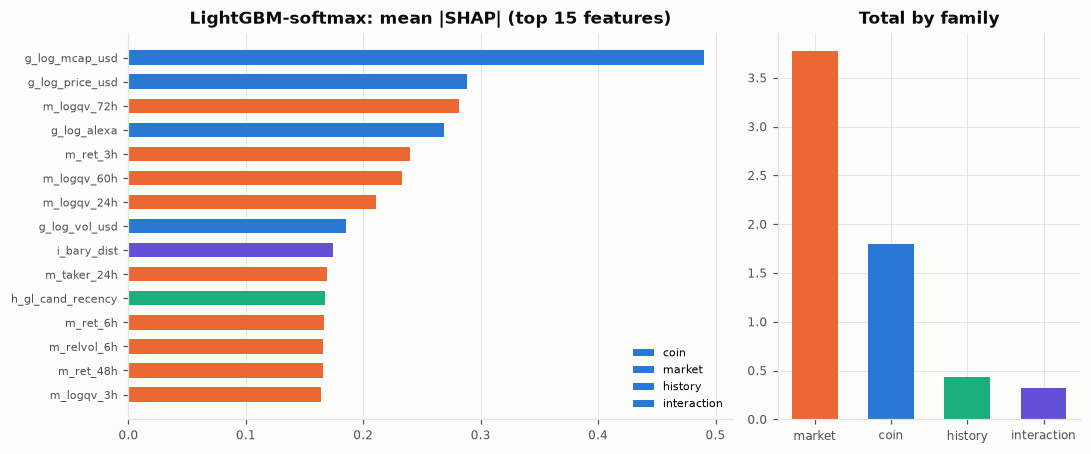

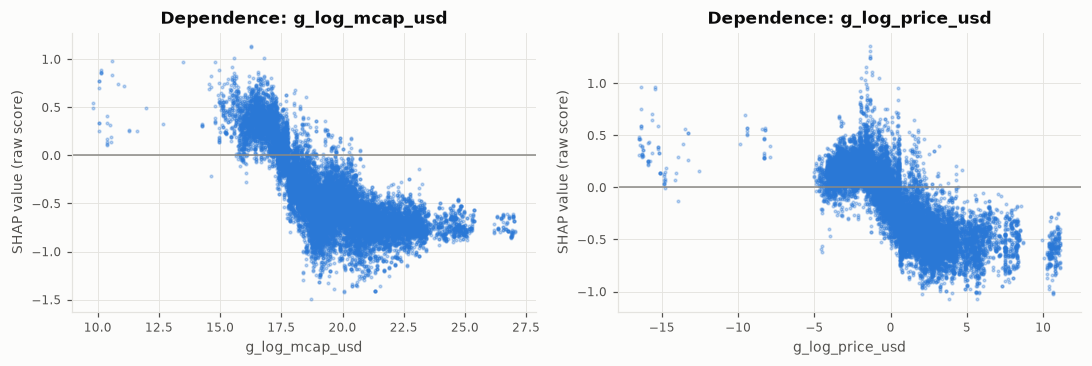

,LightGBM-softmax,mean |SHAP| (LGBM),LR,mean |SHAP| (LR)
0,g_log_mcap_usd,0.490,i_bary_dist,0.229
1,g_log_price_usd,0.288,h_gl_cand_recency,0.166
2,m_logqv_72h,0.281,g_log_mcap_usd,0.153
3,g_log_alexa,0.269,i_mcap_gap,0.141
4,m_ret_3h,0.240,m_ret_60h,0.124
5,m_logqv_60h,0.233,g_log_price_btc,0.122
6,m_logqv_24h,0.211,h_gl_cand_count,0.117
7,g_log_vol_usd,0.185,g_log_vol_usd,0.110
8,i_bary_dist,0.175,g_log_alexa,0.109
9,m_taker_24h,0.169,m_ret_6h,0.104


In [10]:
Xs = test[FEATS].sample(min(20000, len(test)), random_state=settings.SEED)
sv = shap.TreeExplainer(lgb_final).shap_values(Xs)
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
fam_imp = imp.groupby(imp.index.map(FAMILY)).sum().sort_values(ascending=False)
R.table(imp.rename("mean |SHAP|").to_frame(), "shap_importance")
fam_color = {"coin": SERIES[0], "market": SERIES[1], "history": SERIES[2], "interaction": SERIES[6]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [2, 1]})
top = imp.head(15)[::-1]
axes[0].barh(top.index, top.values, color=[fam_color[FAMILY[f]] for f in top.index], height=0.6)
axes[0].set_title("LightGBM-softmax: mean |SHAP| (top 15 features)")
axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=7)
for fam, c in fam_color.items():
    axes[0].barh([], [], color=c, label=fam)
axes[0].legend(fontsize=7, loc="lower right")
axes[1].bar(fam_imp.index, fam_imp.values, color=[fam_color[f] for f in fam_imp.index], width=0.6)
axes[1].set_title("Total by family")
R.fig(fig, "shap_importance")
close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, f in zip(axes, imp.index[:2]):
    j = FEATS.index(f)
    ax.scatter(Xs[f], sv[:, j], s=3, alpha=0.3, color=fam_color[FAMILY[f]])
    ax.axhline(0, color="#8a8985", lw=1)
    ax.set_xlabel(f)
    ax.set_ylabel("SHAP value (raw score)")
    ax.set_title(f"Dependence: {f}")
R.fig(fig, "shap_dependence")
close(fig)

lr_step = lr_final.named_steps["logisticregression"]
Xt = lr_final[:-1].transform(test[FEATS].iloc[:5000])
lin = shap.LinearExplainer(lr_step, Xt).shap_values(Xt)
names_lr = list(FEATS) + [f"missing({FEATS[i]})" for i in lr_final.named_steps["simpleimputer"].indicator_.features_]
lin_imp = pd.Series(np.abs(lin).mean(0), index=names_lr).sort_values(ascending=False)
R.table(lin_imp.rename("mean |SHAP|").to_frame(), "shap_importance_lr")
show(pd.DataFrame({"LightGBM-softmax": imp.head(10).index, "mean |SHAP| (LGBM)": imp.head(10).values,
                   "LR": lin_imp.head(10).index, "mean |SHAP| (LR)": lin_imp.head(10).values}), "{:.3f}")

#### Feature-family ablation (validation)

Removing one family at a time and refitting the softmax LightGBM measures how much each family adds given the
others (SHAP measures how much the model *uses* a feature, which is not the same thing when features are
correlated).

In [11]:
abl = {}
for fam in ["coin", "market", "history", "interaction"]:
    keep = [f for f in FEATS if FAMILY[f] != fam]
    saved = FEATS
    FEATS = keep
    abl[f"without {fam}"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
    FEATS = saved
abl["all features"] = evaluate(valid, predict(fit_lgb(train, base, settings.SEED, "softmax"), valid))[0]
abl = pd.DataFrame(abl).T[["HR@1", "HR@10", "HR@30", "MRR"]]
R.table(abl, "family_ablation")
show(abl, "{:.3f}")

,HR@1,HR@10,HR@30,MRR
without coin,0.020,0.260,0.440,0.088
without market,0.000,0.140,0.480,0.064
without history,0.090,0.200,0.380,0.133
without interaction,0.010,0.270,0.580,0.094
all features,0.110,0.430,0.690,0.202


### 7. Is the best model significantly better than the runner-up?

On the test events, let $a_i=\mathbf 1\{\rho^A_i\le k\}$ and $b_i=\mathbf 1\{\rho^B_i\le k\}$.

* **McNemar (exact)** on HR@1: under $H_0:P(a=1,b=0)=P(a=0,b=1)$, $n_{10}\mid n_{10}+n_{01}\sim\mathrm{Bin}(\cdot,1/2)$.
* **Paired bootstrap** on HR@10 and on MRR: resample events with replacement, $B=10\,000$; the two-sided p-value is
  the share of centred bootstrap differences at least as extreme as the observed one.

In [12]:
order_ = mean["MRR"].sort_values(ascending=False).index.tolist()
A, Bm = order_[0], order_[1]
ra = metrics.target_ranks(test_scores[A])
rb = metrics.target_ranks(test_scores[Bm]).reindex(ra.index)
mc = S.mcnemar(ra <= 1, rb <= 1)
bt10 = S.paired_bootstrap_diff((ra <= 10).astype(float), (rb <= 10).astype(float))
btm = S.paired_bootstrap_diff(1 / ra, 1 / rb)
sig = pd.DataFrame({"comparison": [f"{A} vs {Bm}"] * 3, "metric": ["HR@1 (McNemar)", "HR@10 (paired bootstrap)", "MRR (paired bootstrap)"],
                    "difference": [(ra <= 1).mean() - (rb <= 1).mean(), bt10["diff"], btm["diff"]],
                    "95% CI": ["", f"[{bt10['ci_low']:.3f}, {bt10['ci_high']:.3f}]", f"[{btm['ci_low']:.3f}, {btm['ci_high']:.3f}]"],
                    "p": [mc["p"], bt10["p"], btm["p"]]})
R.table(sig, "significance", index=False)
show(sig.set_index("metric"))
md(f"Best two models by test MRR: **{A}** and **{Bm}**. McNemar on HR@1: $n_{{10}}={mc['n10']}$, $n_{{01}}={mc['n01']}$, "
   f"${S.fmt_p(mc['p'])}$ → {S.decision(mc['p'])}. Paired bootstrap on HR@10: difference {bt10['diff']:+.3f}, "
   f"${S.fmt_p(bt10['p'])}$ → {S.decision(bt10['p'])}; on MRR: {btm['diff']:+.3f}, ${S.fmt_p(btm['p'])}$.")

best_vs_rand = S.paired_bootstrap_diff((ra <= 10).astype(float), np.full(len(ra), rand["HR@10"]))
md(f"Against a random ranking, {A} improves HR@10 by {best_vs_rand['diff']:+.3f} "
   f"(95 % CI [{best_vs_rand['ci_low']:.3f}, {best_vs_rand['ci_high']:.3f}]).")

,comparison,difference,95% CI,p
metric,,,,
HR@1 (McNemar),LightGBM vs RF,-0.0402,,0.1849
HR@10 (paired bootstrap),LightGBM vs RF,0.05528,"[0.020, 0.095]",0.008199
MRR (paired bootstrap),LightGBM vs RF,0.007975,"[-0.025, 0.041]",0.6336


Best two models by test MRR: **LightGBM** and **RF**. McNemar on HR@1: $n_{10}=10$, $n_{01}=18$, $p=0.185$ → do not reject $H_0$ at $\alpha=0.05$. Paired bootstrap on HR@10: difference +0.055, $p=0.008$ → reject $H_0$ at $\alpha=0.05$; on MRR: +0.008, $p=0.634$.

Against a random ranking, LightGBM improves HR@10 by +0.548 (95 % CI [0.478, 0.618]).

### 8. Interpretation (QUICK run: 25 trials per model, 2 seeds)

* **The target is predictable far beyond chance.** Every model ranks the true target in its top 10 for 53–60 % of
  test events, against 3.5 % for a random ranking (LightGBM: +0.55 HR@10 over random, 95 % CI [0.48, 0.62]).
  ROC-AUC is about 0.91 for all models. Because positives are so rare, AUC-PR stays low (0.05–0.12): the target is
  usually *near* the top, rarely *at* the top.
* **Comparison with [A1] (Table 5).** RF reproduces the paper at HR@10 (0.535 vs 0.537) and exceeds it at HR@30
  (0.80 vs 0.73). Our LR is better than the paper's at $k\ge10$ (0.54 vs 0.45 at HR@10), probably because of the
  history and interaction features and the tuned regularisation. At HR@1 all our models (0.09–0.15) stay below the
  paper's LR and RF (0.16, 0.19). With 199 test events one HR@1 point is two events, and the seed standard
  deviations (up to 0.04) show how unstable the top position is.
* **Best models.** LightGBM (binary loss, undersampling 1:5 with class weights) has the best HR@10 and MRR. Its HR@10
  advantage over RF is significant (paired bootstrap $+0.055$, $p\approx0.008$), but McNemar on HR@1 ($p\approx0.19$) and
  the bootstrap on MRR ($p\approx0.63$) are not: the two forests differ in *how deep* they place the target, not in
  how often they rank it first.
* **Imbalance.** With the same trees, the per-event softmax loss dominates every binary variant on validation (MRR
  0.20 against at most 0.12), and undersampling beats class weights. Two caveats. The tree parameters were tuned for
  the softmax loss, which favours it in this comparison. And on the test set the tuned softmax LightGBM is unstable
  across seeds (HR@10 0.34 ± 0.06): its search picked a large learning rate on a validation set of only 100 events.
  For the linear model the softmax (conditional logit) and the class-weighted logistic regression perform alike.
* **What drives the predictions (SHAP, ablation).** Coin-level size (market capitalisation, price, Alexa rank),
  the volume of the last 24–72 hours and short-term returns dominate the trees. The linear model relies most on the
  distance to the barycentre of the channel's past targets and on the recency of the candidate's last pump: the
  two quantities that encode the channel's niche (I.4) and re-pumps. Removing any family hurts on validation, the
  market and history families most. All four families of the brief carry complementary information.

**Limitations.** The validation set (100 events) is small, so hyperparameter selection is noisy; the full run (150
trials, 5 seeds) reduces but cannot remove this. Candidate sets are restricted to coins with complete hourly data,
which drops 34 of 981 events whose target lacked data.

## II.C — Deep learning: sequence models of the channel's pump history

**Objective (brief II.C).**
1. Encode the history $\mathcal H_h(\tau)$ of the channel, of length $L\le8$, with an LSTM, a GRU or a TCN, and
   compare with a DNN applied to the mean of the embeddings.
2. Reproduce the SNN of [A1] and re-implement it in PyTorch. It relies on a positional attention
   $\alpha_l=\mathrm{softmax}_l\big(\boldsymbol q_c^\top W\boldsymbol e_l+p_{L-l}\big)$ with
   $\boldsymbol z_h=\sum_l\alpha_l\boldsymbol e_l$. Explain how the position term $p_{L-l}$ captures *skip
   correlations*.
3. Cold start: replace the coin embedding with a pre-trained word embedding (variant SNN$_S$), run ablations and
   visualise the weights $\alpha_l$.

The protocol is the one of II.B: the same (event, candidate) table and chronological split, validation-based
selection, a single pass on the test set, and mean ± standard deviation over seeds.

In [1]:
import warnings
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import torch
import torch.nn as nn
import torch.nn.functional as F

from pnd_paper import settings, metrics
from pnd_paper import stats as S
from pnd_paper import ranking_dataset as rd
from pnd_paper.coin_embedding import build_coin_embedding
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES, seq_cmap

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
settings.seed_everything()
torch.set_num_threads(max(1, torch.get_num_threads()))
R = Reporter("IIC_deep_learning")
SZ = settings.SIZES
L_MAX = 8

### 1. Data: candidates, sequences and coin vocabulary

* **Candidate features** $\boldsymbol x_{ic}$: the 50 features of II.B (coin, market, history, interaction), with
  missing values imputed by the training median plus missing indicators, then standardised with training
  statistics.
* **Coin embedding** $E\in\mathbb R^{|\mathcal V|\times d}$: one learned vector per coin; the target coin and the
  coins of the history share it ([A1] §5.2).
* **History** $\mathcal H_h(\tau_i)=(e_1,\dots,e_L)$: the channel's last $L\le8$ pumps before $\tau_i-1$ h, most recent
  first. Element $l$ is $\boldsymbol e_l=[E(c_l)\,;\,\boldsymbol s_l]$ with $\boldsymbol s_l$ the standardised
  CoinGecko and pre-pump return features of that past target. Sequences are padded and masked.

In [2]:
ev = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
df = rd.build(ev, panels).sort_values(["event_id", "symbol"]).reset_index(drop=True)
FEATS = rd.feature_columns(df)
tr_mask = df.split == "train"
med = df.loc[tr_mask, FEATS].median()
Xraw = df[FEATS]
miss_cols = [f for f in FEATS if Xraw[f].isna().any()]
X = pd.concat([Xraw.fillna(med), Xraw[miss_cols].isna().astype(float).add_prefix("na_")], axis=1)
mu, sd = X[tr_mask].mean(), X[tr_mask].std().replace(0, 1)
X = ((X - mu) / sd).astype(np.float32)

SEQ_FEATS = [f for f in FEATS if f.startswith("g_")] + [f"m_ret_{x}h" for x in settings.WINDOWS_H]
tgt_rows = df[df.label == 1].set_index("event_id")
seq_feat = ((tgt_rows[SEQ_FEATS].fillna(med[SEQ_FEATS]) - mu[SEQ_FEATS]) / sd[SEQ_FEATS]).astype(np.float32)
coins = sorted(set(df.symbol.str[:-3]))
coin_id = {c: i + 1 for i, c in enumerate(coins)}            # 0 = padding
df["coin_idx"] = df.symbol.str[:-3].map(coin_id)
ev_in = ev[ev.event_id.isin(tgt_rows.index)]
hist = rd.channel_history(ev_in, L_MAX)
events = df.event_id.unique()
split_of = df.groupby("event_id").split.first()


ROWS = df.groupby("event_id").indices


def tensors_for(eids):
    """Per-event tensors: candidate features, candidate coin ids, labels, history coin ids/features/mask."""
    out = []
    for e in eids:
        g = ROWS[e]
        h = hist.get(e, [])
        hc = np.zeros(L_MAX, np.int64)
        hf = np.zeros((L_MAX, len(SEQ_FEATS)), np.float32)
        hm = np.zeros(L_MAX, bool)
        for l, pe in enumerate(h):
            hc[l] = coin_id[tgt_rows.loc[pe, "symbol"][:-3]]
            hf[l] = seq_feat.loc[pe].values
            hm[l] = True
        out.append((torch.from_numpy(X.values[g]), torch.from_numpy(df.coin_idx.values[g].astype(np.int64)),
                    torch.from_numpy(df.label.values[g].astype(np.float32)), torch.from_numpy(hc), torch.from_numpy(hf),
                    torch.from_numpy(hm)))
    return out


DATA = {s: tensors_for([e for e in events if split_of[e] == s]) for s in ("train", "valid", "test")}
hl = pd.Series({e: len(hist.get(e, [])) for e in events})
md(f"{len(events)} events, {len(df)} candidate rows, {X.shape[1]} candidate inputs, vocabulary of {len(coins)} coins. "
   f"History length: {(hl == 0).mean():.0%} of events have no previous pump in their channel (cold start of the "
   f"channel), median length {hl.median():.0f}, {(hl == L_MAX).mean():.0%} reach $L=8$.")

947 events, 192719 candidate rows, 64 candidate inputs, vocabulary of 378 coins. History length: 10% of events have no previous pump in their channel (cold start of the channel), median length 8, 51% reach $L=8$.

### 2. Models

All models output a score $s(i,c)=\mathrm{MLP}\big([\boldsymbol x_{ic};E(c);\boldsymbol z_{h_i}]\big)$ and differ in the
history encoder $\boldsymbol z_h=\mathrm{enc}(e_1..e_L;\,c)$:

| model | encoder |
|---|---|
| DNN | $\boldsymbol z_h=\frac1L\sum_l W_e\boldsymbol e_l$ (mean of embeddings) |
| LSTM / GRU | last hidden state of a recurrent network run from the oldest to the most recent element |
| TCN | 3 causal dilated 1-D convolutions (dilations 1, 2, 4, kernel 2), output at the most recent position |
| SNN | $\alpha_l=\mathrm{softmax}_l(\boldsymbol q_c^\top W\boldsymbol e_l+p_{L-l})$, $\boldsymbol z_h=\sum_l\alpha_l W_e\boldsymbol e_l$, with $\boldsymbol q_c=E(c)$ and $K$ heads |
| SNN$_S$ | SNN with $E$ replaced by frozen coin-symbol word embeddings |

**Loss.** Per-event softmax cross-entropy $\mathcal L=-\sum_i\log\big(e^{s(i,c^\star_i)}/\sum_{c\in\mathcal C_i}e^{s(i,c)}\big)$
(the brief's suggestion for the 0.5 % imbalance; [A1] uses a binary cross-entropy), Adam, weight decay, dropout,
early stopping on validation MRR.

**Position term and skip correlations.** In SNN, $p_{L-l}$ is a learnable bias per *position* (how many pumps ago),
independent of which coin is there. A softmax over $\boldsymbol q_c^\top W\boldsymbol e_l$ alone would weigh history
elements only by their similarity to the candidate. Adding $p_{L-l}$ lets the model learn, for instance, that the pump
two or three steps back matters more than the last one. Channels rotate between groups of coins or re-pump a coin
after a fixed number of rounds, so the relevant element is not adjacent: a *skip* correlation. A recurrent network has
to carry that information through every intermediate step; attention reaches it directly.

In [3]:
class Scorer(nn.Module):
    def __init__(self, n_x, n_coins, d_emb, d_seq, hidden, dropout, encoder, heads=4, use_pos=True, use_query=True,
                 frozen_emb=None):
        super().__init__()
        self.encoder, self.use_pos, self.use_query, self.heads = encoder, use_pos, use_query, heads
        if frozen_emb is not None:
            self.emb = nn.Embedding.from_pretrained(frozen_emb, freeze=True, padding_idx=0)
            d_emb = frozen_emb.shape[1]
        else:
            self.emb = nn.Embedding(n_coins + 1, d_emb, padding_idx=0)
        d_in = d_emb + d_seq
        self.proj = nn.Linear(d_in, hidden)
        if encoder in ("lstm", "gru"):
            self.rnn = (nn.LSTM if encoder == "lstm" else nn.GRU)(d_in, hidden, batch_first=True)
        if encoder == "tcn":
            self.convs = nn.ModuleList([nn.Conv1d(d_in if i == 0 else hidden, hidden, 2, dilation=2**i) for i in range(3)])
        if encoder == "snn":
            self.W = nn.Linear(d_in, d_emb * heads, bias=False)
            self.pos = nn.Parameter(torch.zeros(heads, L_MAX))
            self.head_proj = nn.Linear(hidden * heads, hidden)
        uses_hist = encoder != "none"
        self.mlp = nn.Sequential(nn.Linear(n_x + d_emb + (hidden if uses_hist else 0), hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden // 2, 1))
        self.last_alpha = None

    def encode(self, hc, hf, hm, qc):
        """hc,hf,hm: history of one event (L), qc: candidate coin embeddings (n, d). Returns z (n, hidden)."""
        e = torch.cat([self.emb(hc), hf], dim=-1)                         # (L, d_in), position 0 = most recent
        n = qc.shape[0]
        if not hm.any():
            return torch.zeros(n, self.proj.out_features)
        if self.encoder == "dnn":
            return self.proj(e[hm]).mean(0, keepdim=True).expand(n, -1)
        seq = e[hm].flip(0)                                                # oldest -> most recent
        if self.encoder in ("lstm", "gru"):
            out, _ = self.rnn(seq.unsqueeze(0))
            return out[0, -1].unsqueeze(0).expand(n, -1)
        if self.encoder == "tcn":
            x = seq.T.unsqueeze(0)
            for i, conv in enumerate(self.convs):
                x = F.relu(conv(F.pad(x, ((2 - 1) * 2**i, 0))))
            return x[0, :, -1].unsqueeze(0).expand(n, -1)
        # SNN: positional attention
        v = self.proj(e)                                                   # (L, hidden)
        keys = self.W(e).view(L_MAX, self.heads, -1)                       # (L, K, d_emb)
        logits = torch.einsum("nd,lkd->nkl", qc, keys) if self.use_query else torch.zeros(n, self.heads, L_MAX)
        if self.use_pos:
            logits = logits + self.pos.unsqueeze(0)                        # p_{L-l}: one bias per position and head
        logits = logits.masked_fill(~hm.view(1, 1, -1), -1e9)
        alpha = torch.softmax(logits, dim=-1)                              # (n, K, L)
        self.last_alpha = alpha.detach()
        z = torch.einsum("nkl,lh->nkh", alpha, v).reshape(n, -1)
        return self.head_proj(z)

    def forward(self, x, cid, hc, hf, hm):
        qc = self.emb(cid)
        parts = [x, qc]
        if self.encoder != "none":
            parts.append(self.encode(hc, hf, hm, qc))
        return self.mlp(torch.cat(parts, dim=-1)).squeeze(-1)


def run_epoch(model, data, opt=None, batch_events=16, max_len=L_MAX):
    train = opt is not None
    model.train(train)
    idx = np.random.permutation(len(data)) if train else np.arange(len(data))
    scores = []
    for b in range(0, len(idx), batch_events):
        loss = 0.0
        for j in idx[b:b + batch_events]:
            x, cid, y, hc, hf, hm = data[j]
            if max_len < L_MAX:
                hm = hm.clone()
                hm[max_len:] = False
            with torch.set_grad_enabled(train):
                s = model(x, cid, hc, hf, hm)
            if train:
                loss = loss - torch.log_softmax(s, 0)[y.argmax()]
            else:
                scores.append(s.numpy())
        if train:
            opt.zero_grad()
            (loss / len(idx[b:b + batch_events])).backward()
            opt.step()
    return scores


def rank_report(data, scores):
    rows = [pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s}) for i, (d, s) in enumerate(zip(data, scores))]
    return metrics.ranking_report(pd.concat(rows, ignore_index=True))


def train_model(cfg, seed, data_tr, data_va, epochs, frozen=None, max_len=L_MAX, return_model=False):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = Scorer(X.shape[1], len(coins), cfg["d_emb"], len(SEQ_FEATS), cfg["hidden"], cfg["dropout"], cfg["encoder"],
                   heads=cfg.get("heads", 4), use_pos=cfg.get("use_pos", True), use_query=cfg.get("use_query", True),
                   frozen_emb=frozen)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=cfg["lr"], weight_decay=cfg["wd"])
    best, best_state, patience = -1, None, 0
    for ep in range(epochs):
        run_epoch(model, data_tr, opt, max_len=max_len)
        with torch.no_grad():
            mrr = rank_report(data_va, run_epoch(model, data_va, max_len=max_len))["MRR"]
        if mrr > best:
            best, best_state, patience = mrr, copy.deepcopy(model.state_dict()), 0
        else:
            patience += 1
            if patience >= 4:
                break
    model.load_state_dict(best_state)
    return (model, best, ep + 1) if return_model else (best, ep + 1)

### 3. Pre-trained coin embeddings for SNN$_S$

The brief points to the authors' `wv_embedding.pkl` (378 × 8, row 0 = padding). Its vocabulary (row → coin) was not
shipped; it was built by the authors' code from their intermediate files. Under any plausible ordering (sorted
symbols of the candidate file, with every possible missing symbol), the vectors fail a basic semantic check: the
mean cosine of coins pumped by the same channel (≈0.89) is no higher than that of random pairs (≈0.90), whereas
[A1] reports 0.92 against 0.72. We therefore cannot attach the vectors to coins reliably.

We follow instead the paper's method itself (SkipGram on Telegram messages, §5.3). We compute its closed-form
equivalent, a truncated SVD of the positive PMI matrix of (coin symbol, context word) co-occurrences (Levy &
Goldberg, 2014), on the authors' raw Telegram corpus, using **only messages posted before 2021-01-19** so that the
embedding carries no information from the validation or test periods.

In [4]:
vecs, info = build_coin_embedding(coins, cutoff=settings.TRAIN_END, dim=16)
show(pd.Series(info).to_frame("value"))
frozen = torch.zeros(len(coins) + 1, info["dim"])
for c, i in coin_id.items():
    if c in vecs:
        v = torch.tensor(vecs[c], dtype=torch.float32)
        frozen[i] = v / (v.norm() + 1e-9)
cover = np.mean([c in vecs for c in coins])
md(f"Coins of the vocabulary with a word vector: **{cover:.0%}** (others get a zero vector, i.e. no prior knowledge).")

,value
messages_with_coin,428115
context_vocabulary,20000
coins_mentioned,357
coins_requested,378
cutoff,2021-01-19 00:00:00+00:00
dim,16


Coins of the vocabulary with a word vector: **94%** (others get a zero vector, i.e. no prior knowledge).

### 4. Hyperparameter search (SNN, validation MRR)

The SNN is tuned with Optuna (TPE). In the QUICK run the baselines reuse the SNN's optimiser and width settings
(same budget for all), and only their encoders differ; the full run tunes each model separately.

In [5]:
def space(t):
    return {"d_emb": t.suggest_categorical("d_emb", [8, 16, 32]), "hidden": t.suggest_categorical("hidden", [32, 64, 128]),
            "dropout": t.suggest_float("dropout", 0.0, 0.5), "lr": t.suggest_float("lr", 1e-4, 1e-2, log=True),
            "wd": t.suggest_float("wd", 1e-7, 1e-2, log=True), "heads": t.suggest_categorical("heads", [1, 2, 4, 8])}


def tune(encoder, trials, frozen_emb=None):
    def objective(t):
        cfg = {**space(t), "encoder": encoder}
        best, _ = train_model(cfg, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs, frozen=frozen_emb)
        return best
    st_ = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=settings.SEED))
    st_.optimize(objective, n_trials=trials)
    return st_


n_trials = max(6, SZ.optuna_trials // 2)
study = tune("snn", n_trials)
best_cfg = {**study.best_params}
tuned = {"snn": best_cfg}
if not settings.QUICK:
    for enc in ("dnn", "lstm", "gru", "tcn"):
        tuned[enc] = tune(enc, n_trials).best_params
hp = pd.DataFrame({"best validation MRR": [study.best_value], "trials": [len(study.trials)], "parameters": [str(best_cfg)]})
R.table(hp, "snn_search", index=False)
show(hp)

,best validation MRR,trials,parameters
0,0.3078,12,"{'d_emb': 16, 'hidden': 32, 'dropout': 0.13823212757154835, 'lr': 0.004015543686135838, 'wd': 0.006175850414870784, 'heads': 1}"


### 5. Test results (train on train, early-stop on validation, one pass on test)

In [6]:
MODELS = {"DNN (mean)": "dnn", "LSTM": "lstm", "GRU": "gru", "TCN": "tcn", "SNN": "snn", "SNN_S": "snn"}
seeds = [settings.SEED + s for s in range(SZ.seeds)]
reps, scores_first, models_first = {}, {}, {}
for name, enc in MODELS.items():
    cfg = {**tuned.get(enc, best_cfg), "encoder": enc}
    rows = []
    for sd in seeds:
        model, _, _ = train_model(cfg, sd, DATA["train"], DATA["valid"], SZ.dl_epochs,
                                  frozen=frozen if name == "SNN_S" else None, return_model=True)
        with torch.no_grad():
            sc = run_epoch(model, DATA["test"])
        rows.append(rank_report(DATA["test"], sc))
        if sd == seeds[0]:
            scores_first[name], models_first[name] = sc, model
    reps[name] = pd.DataFrame(rows)
cols = [f"HR@{k}" for k in settings.HR_KS] + ["MRR", "AUC-PR", "AUC"]
mean = pd.DataFrame({n: r[cols].mean() for n, r in reps.items()}).T
std = pd.DataFrame({n: r[cols].std(ddof=1) for n, r in reps.items()}).T.fillna(0)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
R.table(mean, "test_mean")
R.table(std, "test_std")
R.table(table, "test_table")
show(table)

,HR@1,HR@3,HR@5,HR@10,HR@20,HR@30,MRR,AUC-PR,AUC
DNN (mean),0.153 ± 0.018,0.291 ± 0.007,0.384 ± 0.011,0.573 ± 0.021,0.691 ± 0.018,0.756 ± 0.025,0.278 ± 0.005,0.064 ± 0.004,0.911 ± 0.004
LSTM,0.171 ± 0.036,0.314 ± 0.039,0.394 ± 0.032,0.565 ± 0.018,0.704 ± 0.043,0.789 ± 0.05,0.293 ± 0.033,0.071 ± 0.004,0.915 ± 0.007
GRU,0.181 ± 0.014,0.354 ± 0.018,0.432 ± 0.036,0.548 ± 0.021,0.693 ± 0.043,0.779 ± 0.036,0.309 ± 0.001,0.07 ± 0.002,0.913 ± 0.004
TCN,0.201 ± 0.036,0.334 ± 0.053,0.412 ± 0.007,0.548 ± 0.021,0.698 ± 0.057,0.784 ± 0.071,0.312 ± 0.026,0.092 ± 0.024,0.916 ± 0.005
SNN,0.204 ± 0.032,0.387 ± 0.028,0.427 ± 0.043,0.543 ± 0.085,0.683 ± 0.057,0.799 ± 0.021,0.318 ± 0.012,0.076 ± 0.005,0.916 ± 0.006
SNN_S,0.171 ± 0.014,0.332 ± 0.021,0.422 ± 0.05,0.538 ± 0.057,0.734 ± 0.028,0.771 ± 0.053,0.296 ± 0.002,0.07 ± 0.001,0.906 ± 0.006


,ours HR@1,[A1] HR@1,ours HR@10,[A1] HR@10,ours HR@30,[A1] HR@30
DNN (mean),0.153,0.225,0.573,0.498,0.756,0.727
LSTM,0.171,0.207,0.565,0.551,0.789,0.696
GRU,0.181,0.229,0.548,0.529,0.779,0.714
TCN,0.201,0.256,0.548,0.573,0.784,0.770
SNN,0.204,0.260,0.543,0.596,0.799,0.797
SNN_S,0.171,0.277,0.538,0.623,0.771,0.823


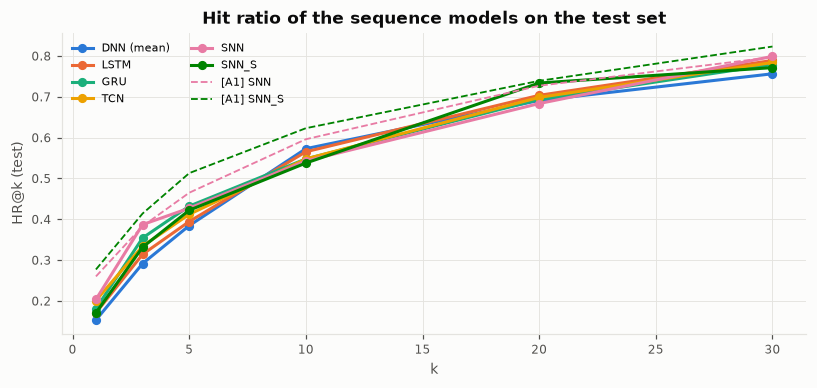

In [7]:
paper = settings.PAPER_TABLE5
cmp = pd.DataFrame({
    "ours HR@1": mean["HR@1"], "[A1] HR@1": [paper.loc["HR@1", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
    "ours HR@10": mean["HR@10"], "[A1] HR@10": [paper.loc["HR@10", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
    "ours HR@30": mean["HR@30"], "[A1] HR@30": [paper.loc["HR@30", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
}, index=mean.index)
R.table(cmp, "comparison_with_paper")
show(cmp, "{:.3f}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ks = list(settings.HR_KS)
for i, n in enumerate(MODELS):
    ax.plot(ks, [mean.loc[n, f"HR@{k}"] for k in ks], marker="o", color=SERIES[i], label=n)
ax.plot(ks, paper["SNN"].values, ls="--", color=SERIES[4], lw=1.2, label="[A1] SNN")
ax.plot(ks, paper["SNNS"].values, ls="--", color=SERIES[5], lw=1.2, label="[A1] SNN_S")
ax.set_xlabel("k")
ax.set_ylabel("HR@k (test)")
ax.set_title("Hit ratio of the sequence models on the test set")
ax.legend(ncol=2, fontsize=7)
R.fig(fig, "hr_curves")
close(fig)

### 6. Ablations (validation and test, first seed)

* **no position term**: $p_{L-l}\equiv0$, so attention depends only on similarity to the candidate;
* **position only**: $\alpha_l=\mathrm{softmax}_l(p_{L-l})$, the purely positional attention of [A1] Eq. (3)–(6);
* **mean pooling** = DNN; **no history**: $\boldsymbol z_h$ removed;
* **history length** $L\in\{1,2,4,8\}$.

In [8]:
abl_cfgs = {"SNN (full)": {**best_cfg, "encoder": "snn"},
            "no position term": {**best_cfg, "encoder": "snn", "use_pos": False},
            "position only": {**best_cfg, "encoder": "snn", "use_query": False},
            "mean pooling (DNN)": {**best_cfg, "encoder": "dnn"},
            "no history": {**best_cfg, "encoder": "none"}}
abl = {}
for name, cfg in abl_cfgs.items():
    model, vbest, _ = train_model(cfg, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs, return_model=True)
    with torch.no_grad():
        abl[name] = {"valid MRR": vbest, **{f"test {k}": v for k, v in rank_report(DATA["test"], run_epoch(model, DATA["test"])).items()
                                            if k in ("HR@1", "HR@10", "HR@30", "MRR")}}
for Lh in (1, 2, 4):
    model, vbest, _ = train_model({**best_cfg, "encoder": "snn"}, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs,
                                  max_len=Lh, return_model=True)
    with torch.no_grad():
        abl[f"SNN, L = {Lh}"] = {"valid MRR": vbest, **{f"test {k}": v for k, v in rank_report(DATA["test"], run_epoch(model, DATA["test"], max_len=Lh)).items()
                                                       if k in ("HR@1", "HR@10", "HR@30", "MRR")}}
abl = pd.DataFrame(abl).T
R.table(abl, "ablations")
show(abl, "{:.3f}")

,valid MRR,test HR@1,test HR@10,test HR@30,test MRR
SNN (full),0.308,0.181,0.482,0.784,0.310
no position term,0.317,0.166,0.477,0.779,0.302
position only,0.282,0.171,0.553,0.744,0.283
mean pooling (DNN),0.285,0.166,0.558,0.739,0.281
no history,0.253,0.156,0.613,0.759,0.279
"SNN, L = 1",0.277,0.201,0.608,0.754,0.296
"SNN, L = 2",0.270,0.176,0.573,0.774,0.281
"SNN, L = 4",0.267,0.161,0.558,0.784,0.273


### 7. Attention weights $\alpha_l$ and the position term

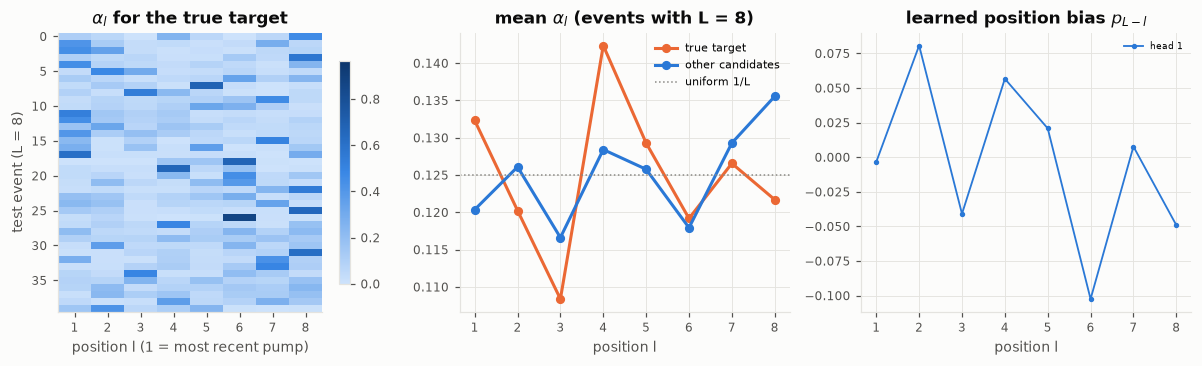

Mean attention of the true target over positions 1–8 (events with a full history, n = 119): 0.13, 0.12, 0.11, 0.14, 0.13, 0.12, 0.13, 0.12. Learned position biases (averaged over heads): -0.00, +0.08, -0.04, +0.06, +0.02, -0.10, +0.01, -0.05.

In [9]:
snn = models_first["SNN"]
alphas_t, alphas_n, lens = [], [], []
with torch.no_grad():
    for x, cid, y, hc, hf, hm in DATA["test"]:
        if hm.sum() < 2:
            continue
        snn(x, cid, hc, hf, hm)
        a = snn.last_alpha.mean(1).numpy()               # average over heads -> (n, L)
        alphas_t.append(a[y.numpy() == 1].mean(0))
        alphas_n.append(a[y.numpy() == 0].mean(0))
        lens.append(int(hm.sum()))
At, An = np.array(alphas_t), np.array(alphas_n)
pos_bias = snn.pos.detach().numpy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
full = np.array(lens) == L_MAX
im = axes[0].imshow(At[full][:40], aspect="auto", cmap=seq_cmap(), vmin=0, vmax=max(0.5, At[full].max() if full.any() else 0.5))
axes[0].set_xticks(range(L_MAX), [str(i + 1) for i in range(L_MAX)])
axes[0].set_xlabel("position l (1 = most recent pump)")
axes[0].set_ylabel("test event (L = 8)")
axes[0].set_title(r"$\alpha_l$ for the true target")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].plot(range(1, L_MAX + 1), At[full].mean(0), marker="o", color=SERIES[1], label="true target")
axes[1].plot(range(1, L_MAX + 1), An[full].mean(0), marker="o", color=SERIES[0], label="other candidates")
axes[1].axhline(1 / L_MAX, color="#8a8985", ls=":", lw=1, label="uniform 1/L")
axes[1].set_xlabel("position l")
axes[1].set_title(r"mean $\alpha_l$ (events with L = 8)")
axes[1].legend(fontsize=7)
for k in range(pos_bias.shape[0]):
    axes[2].plot(range(1, L_MAX + 1), pos_bias[k], marker=".", color=SERIES[k % 8], lw=1.2, label=f"head {k + 1}")
axes[2].set_xlabel("position l")
axes[2].set_title(r"learned position bias $p_{L-l}$")
axes[2].legend(fontsize=6, ncol=2)
R.fig(fig, "attention")
close(fig)
md(f"Mean attention of the true target over positions 1–8 (events with a full history, n = {int(full.sum())}): "
   + ", ".join(f"{v:.2f}" for v in At[full].mean(0)) + ". Learned position biases (averaged over heads): "
   + ", ".join(f"{v:+.2f}" for v in pos_bias.mean(0)) + ".")

### 8. Cold start: targets never pumped before

A test target is *cold* if no channel pumped it during the training period. For those events the learned coin
embedding $E(c)$ is barely trained, which is exactly the case SNN$_S$ is designed for.

In [10]:
train_coins = set(df[(df.label == 1) & (df.split == "train")].symbol)
test_targets = df[(df.label == 1) & (df.split == "test")].set_index("event_id").symbol
test_eids = [e for e in events if split_of[e] == "test"]
cold = np.array([test_targets[e] not in train_coins for e in test_eids])
rows = []
for name in ("SNN", "SNN_S", "DNN (mean)"):
    r = metrics.target_ranks(pd.concat([pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s})
                                        for i, (d, s) in enumerate(zip(DATA["test"], scores_first[name]))]))
    for lab, msk in (("cold targets", cold), ("warm targets", ~cold)):
        rr = r.values[msk]
        rows.append({"model": name, "subset": lab, "events": int(msk.sum()), "HR@1": (rr <= 1).mean(),
                     "HR@10": (rr <= 10).mean(), "HR@30": (rr <= 30).mean(), "MRR": (1 / rr).mean()})
coldtab = pd.DataFrame(rows).set_index(["model", "subset"])
R.table(coldtab, "cold_start")
show(coldtab, "{:.3f}")
md(f"Cold-start share of the test set: **{cold.mean():.0%}** of test targets were never pumped during training.")

Cold-start share of the test set: **40%** of test targets were never pumped during training.

### 9. Statistical comparison of the two best models

In [11]:
order_ = mean["MRR"].sort_values(ascending=False).index.tolist()
A, Bm = order_[0], order_[1]
def ranks_of(name):
    return metrics.target_ranks(pd.concat([pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s})
                                           for i, (d, s) in enumerate(zip(DATA["test"], scores_first[name]))]))
ra, rb = ranks_of(A), ranks_of(Bm)
mc = S.mcnemar(ra <= 1, rb <= 1)
bt = S.paired_bootstrap_diff((ra <= 10).astype(float), (rb <= 10).astype(float))
rs = ranks_of("SNN")
rsn = ranks_of("SNN_S")
bt_s = S.paired_bootstrap_diff(1 / rsn, 1 / rs)
sig = pd.DataFrame({"comparison": [f"{A} vs {Bm} (HR@1, McNemar)", f"{A} vs {Bm} (HR@10, bootstrap)", "SNN_S vs SNN (MRR, bootstrap)"],
                    "difference": [(ra <= 1).mean() - (rb <= 1).mean(), bt["diff"], bt_s["diff"]],
                    "p": [mc["p"], bt["p"], bt_s["p"]]}).set_index("comparison")
R.table(sig, "significance")
show(sig, "{:.4f}")
md(f"McNemar on HR@1 between {A} and {Bm}: $n_{{10}}={mc['n10']}$, $n_{{01}}={mc['n01']}$, ${S.fmt_p(mc['p'])}$ → "
   f"{S.decision(mc['p'])}. Paired bootstrap on HR@10: {bt['diff']:+.3f} (95 % CI [{bt['ci_low']:.3f}, {bt['ci_high']:.3f}]), "
   f"${S.fmt_p(bt['p'])}$. SNN$_S$ − SNN on MRR: {bt_s['diff']:+.3f}, ${S.fmt_p(bt_s['p'])}$.")

,difference,p
comparison,,
"SNN vs TCN (HR@1, McNemar)",-0.0452,0.0784
"SNN vs TCN (HR@10, bootstrap)",-0.0503,0.0181
"SNN_S vs SNN (MRR, bootstrap)",-0.0154,0.3677


McNemar on HR@1 between SNN and TCN: $n_{10}=6$, $n_{01}=15$, $p=0.078$ → do not reject $H_0$ at $\alpha=0.05$. Paired bootstrap on HR@10: -0.050 (95 % CI [-0.090, -0.015]), $p=0.018$. SNN$_S$ − SNN on MRR: -0.015, $p=0.368$.

### 10. The repository's SNN (TensorFlow 1)

The brief also asks to run `run_train.py --model=snn` from the authors' repository. That code is ported
bug-for-bug in this repository (`uv run pnd train --model snn`, see `QUIRKS.md`). It cannot be trained on real data
as shipped:

* the training files it reads (`feature/train_sample.csv`) are never produced by the authors' feature scripts
  (path mismatches Q22, Q24 and Q29; the negative samples are never saved, Q23f);
* its data loader splits each feature string **character by character** (Q30), so any real feature value
  containing `.`, `-` or `e` raises a `StringToNumber` error;
* its evaluation truncates predicted probabilities to integers before computing the hit ratio (Q33), which yields
  HR@1 = 0 whatever the model.

The port runs end to end on a hand-made fixture (`pnd train --model snn` with `tests/fixtures/tiny_train.csv`),
which shows that the TensorFlow graph is reproduced; the full pipeline report (`runs/literal-full/`) documents each
failure. The PyTorch SNN above follows the paper's description instead.

### 11. Interpretation (QUICK run: 12 tuning trials, 2 seeds, at most 15 epochs)

* **Sequence models are the best rankers of this study at the top of the list.** Averaged over seeds, the SNN has
  the highest MRR (0.318) and HR@1 (0.204), followed by TCN (0.312, 0.201) and GRU (0.309, 0.181). The DNN on mean
  embeddings is last (MRR 0.278, HR@1 0.153). The tree and linear models of II.B reach at most HR@1 = 0.153 and
  MRR = 0.291. Encoding the *order* of the channel's past pumps therefore helps place the true target first, the
  paper's central claim.
* **Comparison with [A1] (Tables 5–6).** The ordering DNN < RNNs < TCN < SNN of the paper is reproduced at HR@1.
  Levels are below the paper's at HR@1 (0.20 vs 0.26 for SNN) and close to it at HR@30 (SNN 0.799 vs 0.797). At
  HR@10 all sequence models land between 0.54 and 0.57, below the paper's SNN (0.596). The seed standard deviations
  (up to 0.085 at HR@10 for SNN) are as large as the differences between models.
* **Significance.** On the first seed, TCN beats SNN at HR@10 (paired bootstrap $p\approx0.02$) while McNemar on
  HR@1 does not separate them ($p\approx0.08$). The ranking of the two best sequence models flips between seeds and
  metrics. With 199 test events, our data cannot establish that the SNN's attention beats a TCN; they do establish
  that sequence models beat a mean-pooled history at the top of the ranking.
* **Cold start.** 40 % of test targets were never pumped in the training period. For them every model collapses
  (SNN HR@1 0.05 against 0.27 on warm targets). SNN$_S$ with our Telegram embeddings does **not** fix this: it improves
  warm targets slightly and degrades cold ones, and its MRR difference with SNN is not significant ($p\approx0.37$).
  Our embeddings (PPMI–SVD on 428 000 messages before 2021) are much smaller than the corpus [A1] used ("not
  limited to the pump channels"). Symbols such as ONE, DATA or SKY are also ordinary words, which blurs the
  co-occurrence statistics. The paper's +1.7 HR@1 points for SNN$_S$ is within our seed noise.
* **Attention and skip correlations.** The learned attention is almost uniform over the 8 positions (0.11–0.14
  for the true target) and the position biases $p_{L-l}$ stay small ($|p|\le0.1$). In our data the model has no
  strong preference for a particular lag. The ablations agree: removing the position term, keeping only it, or
  shortening the history to $L=1,2,4$ changes validation MRR by at most 0.04 (one seed), which is within noise.
  The mechanism can capture skip correlations, since a large $p_{L-l}$ for some $l>1$ would make the model look
  "$l$ pumps back" directly without passing through the intermediate steps as an RNN must. But we find little
  evidence that such correlations are strong in this dataset. The paper's Figure 10 shows larger position effects,
  with $L$ up to 30.

**Limitations.** QUICK settings (12 trials, 15 epochs, 2 seeds) under-train the sequence models; the baselines
reuse the SNN's tuned hyperparameters in the QUICK run. The full run tunes each model and averages 5 seeds.

## II.D (bonus) — Forecasting the mean BTC price over the next 48 hours with Telegram sentiment

**Objective (brief II.D).** Predict the mean BTC price over the next 48 hours from 200 hours of history and a VADER
sentiment score computed on Telegram; compare ARIMA, ARIMAX and LSTM by MAE with rolling validation, and apply the
Diebold–Mariano test. [A1] §7 runs a similar experiment (200-hour sequences, 48-hour horizon, MAE) to show that the
SNN generalises.

**Target.** With $P_t$ the BTC/USDT hourly close,
$$y_t=\frac{1}{48}\sum_{j=1}^{48}P_{t+j},$$
forecast at origin $t$ from $\{P_s,\ \text{sent}_s:\ t-199\le s\le t\}$.

In [1]:
import contextlib
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import grangercausalitytests
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import binance
from pnd_paper.data.telegram import iter_messages
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IID_bonus_btc_forecast")
SZ = settings.SIZES
HIST, H = 200, 48

### 1. Data

* **Price**: Binance BTC/USDT hourly klines, downloaded from the public archive.
* **Sentiment**: VADER (Hutto & Gilbert, 2014) assigns each message a compound score in $[-1,1]$, a normalised sum of
  lexicon valences adjusted for negation, intensifiers, punctuation and capitals. The hourly sentiment is the mean
  compound score of all Telegram posts of the authors' corpus in that hour, $\text{sent}_t=\frac1{n_t}\sum_{m\in t}
  \text{compound}(m)$, and $n_t$ the message count. The corpus ends in January 2022, which bounds the study period.

In [2]:
cache = settings.CACHE / "sentiment_hourly.parquet"
if cache.is_file():
    sent = pd.read_parquet(cache)
else:
    an = SentimentIntensityAnalyzer()
    start = pd.Timestamp("2020-01-01", tz="UTC").to_pydatetime()
    rows = [(d, an.polarity_scores(t[:500])["compound"]) for _, d, t in iter_messages() if d is not None and d >= start]
    s = pd.DataFrame(rows, columns=["date", "compound"])
    s["hour"] = pd.to_datetime(s.date, utc=True).dt.floor("h")
    sent = s.groupby("hour").compound.agg(["mean", "size"]).rename(columns={"mean": "sent", "size": "n_msg"})
    sent.to_parquet(cache)
start, end = pd.Timestamp("2020-02-07", tz="UTC"), sent.index.max().floor("D")
btc = binance.load_klines("BTCUSDT", "1h", start - pd.Timedelta(days=10), end)
df = pd.DataFrame({"price": btc.close.astype(float)}).join(sent, how="left")
df = df.asfreq("h")
df["price"] = df.price.ffill()
df["sent"] = df.sent.fillna(0.0)
df["n_msg"] = df.n_msg.fillna(0)
df["y"] = df.price[::-1].rolling(H).mean()[::-1].shift(-1)        # mean of P_{t+1..t+48}
df = df.loc[start:]
md(f"Hourly observations: {len(df)} from {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}; messages scored: "
   f"{int(sent.n_msg.sum()):,}; mean hourly sentiment {df.sent.mean():.3f} (sd {df.sent.std():.3f}).")

Hourly observations: 17233 from 2020-02-07 to 2022-01-25; messages scored: 946,500; mean hourly sentiment 0.243 (sd 0.112).

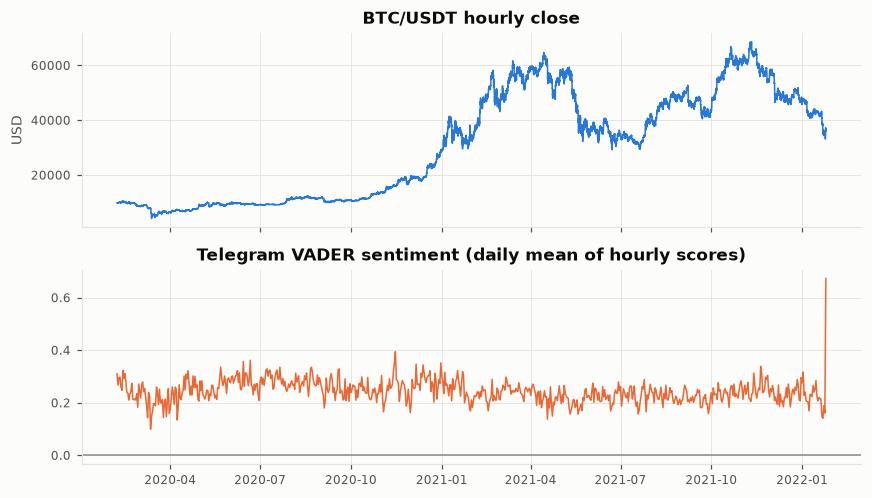

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(df.index, df.price, color=SERIES[0], lw=1)
axes[0].set_title("BTC/USDT hourly close")
axes[0].set_ylabel("USD")
daily = df.sent.resample("D").mean()
axes[1].plot(daily.index, daily.values, color=SERIES[1], lw=1)
axes[1].axhline(0, color="#8a8985", lw=1)
axes[1].set_title("Telegram VADER sentiment (daily mean of hourly scores)")
R.fig(fig, "series")
close(fig)

#### Does sentiment carry information about future returns? (Granger test)

For hourly log-returns $r_t$, compare the restricted model $r_t=c+\sum_{k=1}^{p}a_kr_{t-k}+u_t$ with the unrestricted
one adding $\sum_{k=1}^{p}b_k\,\text{sent}_{t-k}$. $H_0:b_1=\dots=b_p=0$ (sentiment does not Granger-cause returns) is
tested with $F=\frac{(\mathrm{RSS}_r-\mathrm{RSS}_u)/p}{\mathrm{RSS}_u/(T-2p-1)}\sim F_{p,T-2p-1}$.

In [4]:
gdf = pd.DataFrame({"r": np.log(df.price).diff(), "sent": df.sent}).dropna()
gc_rows = []
for p in (1, 6, 24, 48):
    with contextlib.redirect_stdout(io.StringIO()):     # the function prints every test; keep only the F test
        res = grangercausalitytests(gdf[["r", "sent"]], maxlag=[p])[p][0]["ssr_ftest"]
        rev = grangercausalitytests(gdf[["sent", "r"]], maxlag=[p])[p][0]["ssr_ftest"]
    gc_rows.append({"lags p": p, "F (sent -> r)": res[0], "p (sent -> r)": res[1], "F (r -> sent)": rev[0], "p (r -> sent)": rev[1]})
gc = pd.DataFrame(gc_rows).set_index("lags p")
R.table(gc, "granger")
show(gc, "{:.3g}")
md("\n".join(f"- $p={k}$: sentiment → returns $F={r['F (sent -> r)']:.2f},\\ {S.fmt_p(r['p (sent -> r)'])}$; "
             f"returns → sentiment $F={r['F (r -> sent)']:.2f},\\ {S.fmt_p(r['p (r -> sent)'])}$." for k, r in gc.iterrows()))

,F (sent -> r),p (sent -> r),F (r -> sent),p (r -> sent)
lags p,,,,
1,0.177,0.674,13.7,0.000212
6,1.03,0.405,6.83,2.96e-07
24,0.629,0.917,2.86,3.63e-06
48,0.659,0.967,2.15,7.06e-06


- $p=1$: sentiment → returns $F=0.18,\ p=0.674$; returns → sentiment $F=13.72,\ p=2.12\times10^{-4}$.
- $p=6$: sentiment → returns $F=1.03,\ p=0.405$; returns → sentiment $F=6.83,\ p=2.96\times10^{-7}$.
- $p=24$: sentiment → returns $F=0.63,\ p=0.917$; returns → sentiment $F=2.86,\ p=3.63\times10^{-6}$.
- $p=48$: sentiment → returns $F=0.66,\ p=0.967$; returns → sentiment $F=2.15,\ p=7.06\times10^{-6}$.

### 2. Rolling-origin evaluation design

Origins $t_1<\dots<t_M$ are spaced by 24 hours over the last part of the sample (test period); at each origin,
every model sees only data up to $t_m$. The LSTM is trained once on origins **before** the test period (with the
last 20 % of them as a validation set for early stopping); the ARIMA models are re-estimated at every origin on the
last 200 hours (rolling window).

* **ARIMA$(p,1,q)$** on $\log P$, $p,q\le2$, order chosen by AIC at each origin; the 48 point forecasts
  $\widehat{\log P}_{t+j}$ are mapped back with $\exp$ and averaged.
* **ARIMAX**: the same with the exogenous regressor $\text{sent}_{t-48}$ (lagged by the horizon, so its future
  values are known when forecasting $t+1..t+48$).
* **LSTM**: input the 200-hour window of $[\log P_s-\log P_t,\ \text{sent}_s,\ \log(1+n_s)]$, output
  $\log(y_t/P_t)$, trained with an L1 loss (MAE).
* **Random walk**: $\hat y_t=P_t$, the benchmark any model must beat.

In [5]:
M = SZ.rolling_origins
origins = df.index[df.y.notna()][-1 - 24 * (M - 1)::24][:M]
test_start = origins[0]
md(f"{len(origins)} origins from {origins[0]:%Y-%m-%d %H:%M} to {origins[-1]:%Y-%m-%d %H:%M}, one per day "
   f"({'QUICK' if settings.QUICK else 'FULL'} run).")


def arima_forecast(t, exog=False):
    hist = df.loc[:t].iloc[-HIST:]
    y = np.log(hist.price.values)
    X = hist.sent.shift(H).fillna(0.0).values[:, None] if exog else None
    Xf = df.sent.loc[:t].iloc[-H:].values[:, None] if exog else None
    best = None
    for p in range(3):
        for q in range(3):
            try:
                m = SARIMAX(y, exog=X, order=(p, 1, q), trend="n").fit(disp=False)
            except Exception:
                continue
            if best is None or m.aic < best.aic:
                best = m
    fc = best.forecast(H, exog=Xf)
    return float(np.exp(fc).mean()), best.model.order


rows = []
for t in origins:
    a, oa = arima_forecast(t, False)
    ax_, ox = arima_forecast(t, True)
    rows.append({"origin": t, "y": df.y.loc[t], "P_t": df.price.loc[t], "ARIMA": a, "ARIMAX": ax_, "order ARIMA": str(oa)})
fc = pd.DataFrame(rows).set_index("origin")
fc["random walk"] = fc.P_t

40 origins from 2021-12-15 00:00 to 2022-01-23 00:00, one per day (QUICK run).

In [6]:
def windows(index):
    Xs, ys = [], []
    lp = np.log(df.price.values)
    for t in index:
        i = df.index.get_loc(t)
        if i < HIST:
            continue
        w = slice(i - HIST + 1, i + 1)
        Xs.append(np.c_[lp[w] - lp[i], df.sent.values[w], np.log1p(df.n_msg.values[w])])
        ys.append(np.log(df.y.values[i] / df.price.values[i]))
    return torch.tensor(np.array(Xs), dtype=torch.float32), torch.tensor(np.array(ys), dtype=torch.float32)


class LSTMReg(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.LSTM(3, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        o, _ = self.rnn(x)
        return self.out(o[:, -1]).squeeze(-1)


train_idx = df.index[(df.index < test_start - pd.Timedelta(hours=H)) & df.y.notna()][HIST::6]
cut = int(0.8 * len(train_idx))
Xtr, ytr = windows(train_idx[:cut])
Xva, yva = windows(train_idx[cut:])
Xte, _ = windows(origins)
lstm_preds = []
for sd in [settings.SEED + s for s in range(SZ.seeds)]:
    torch.manual_seed(sd)
    net = LSTMReg()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    best, state, bad = np.inf, None, 0
    for ep in range(SZ.dl_epochs * 2):
        net.train()
        perm = torch.randperm(len(Xtr))
        for b in range(0, len(perm), 128):
            j = perm[b:b + 128]
            opt.zero_grad()
            loss = (net(Xtr[j]) - ytr[j]).abs().mean()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = (net(Xva) - yva).abs().mean().item()
        if v < best:
            best, state, bad = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= 5:
                break
    net.load_state_dict(state)
    with torch.no_grad():
        lstm_preds.append(np.exp(net(Xte).numpy()) * fc.P_t.values)
fc["LSTM"] = np.mean(lstm_preds, axis=0)
R.table(fc, "forecasts")

WindowsPath('C:/Users/Dr.Console/Desktop/Pump-and-Dump-Detection-on-Cryptocurrency-master/results/IID_bonus_btc_forecast/tables/forecasts.csv')

### 3. Results: MAE and Diebold–Mariano tests

$\mathrm{MAE}=\frac1M\sum_m|y_{t_m}-\hat y_{t_m}|$ (USD). For two models with errors $e^{(1)},e^{(2)}$ and loss
differential $d_m=|e^{(1)}_m|-|e^{(2)}_m|$, the Diebold–Mariano statistic is
$$\mathrm{DM}=\frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/M}},\qquad
\widehat{\mathrm{LRV}}=\hat\gamma_0+2\sum_{k=1}^{h-1}\Big(1-\frac kh\Big)\hat\gamma_k,$$
with the Harvey–Leybourne–Newbold correction $\mathrm{DM}^*=\mathrm{DM}\sqrt{(M+1-2h+h(h-1)/M)/M}\sim t_{M-1}$.
Forecasts 24 hours apart with a 48-hour target overlap, so $h=2$ autocovariance lags are needed. $H_0$: equal
expected absolute error.

In [7]:
models = ["random walk", "ARIMA", "ARIMAX", "LSTM"]
mae = pd.DataFrame({m: {"MAE (USD)": (fc[m] - fc.y).abs().mean(), "MAPE (%)": 100 * ((fc[m] - fc.y).abs() / fc.y).mean()}
                    for m in models}).T
lstm_seed_mae = [np.abs(p - fc.y.values).mean() for p in lstm_preds]
mae.loc["LSTM", "sd over seeds"] = np.std(lstm_seed_mae, ddof=1) if len(lstm_seed_mae) > 1 else 0.0
R.table(mae, "mae")
show(mae, "{:.2f}")
dm_rows = []
for i, a in enumerate(models):
    for b in models[i + 1:]:
        r = S.diebold_mariano(fc[a] - fc.y, fc[b] - fc.y, h=2)
        dm_rows.append({"model 1": a, "model 2": b, "mean |e1|-|e2|": r["mean_loss_diff"], "DM*": r["DM_HLN"], "p": r["p"]})
dm = pd.DataFrame(dm_rows)
dm["p (Holm)"] = S.holm(dm.p)
R.table(dm, "diebold_mariano", index=False)
show(dm.set_index(["model 1", "model 2"]), "{:.3g}")
md("\n".join(f"- {r['model 1']} vs {r['model 2']}: $\\bar d={r['mean |e1|-|e2|']:.1f}$ USD, $\\mathrm{{DM}}^*={r['DM*']:.2f}$, "
             f"Holm-adjusted ${S.fmt_p(r['p (Holm)'])}$ → {S.decision(r['p (Holm)'])}." for _, r in dm.iterrows()))

,MAE (USD),MAPE (%),sd over seeds
random walk,756.03,1.73,nan
ARIMA,757.83,1.73,nan
ARIMAX,758.43,1.73,nan
LSTM,801.34,1.84,0.38


- random walk vs ARIMA: $\bar d=-1.8$ USD, $\mathrm{DM}^*=-1.38$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- random walk vs ARIMAX: $\bar d=-2.4$ USD, $\mathrm{DM}^*=-0.80$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- random walk vs LSTM: $\bar d=-45.3$ USD, $\mathrm{DM}^*=-1.35$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMA vs ARIMAX: $\bar d=-0.6$ USD, $\mathrm{DM}^*=-0.26$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMA vs LSTM: $\bar d=-43.5$ USD, $\mathrm{DM}^*=-1.29$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMAX vs LSTM: $\bar d=-42.9$ USD, $\mathrm{DM}^*=-1.28$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.

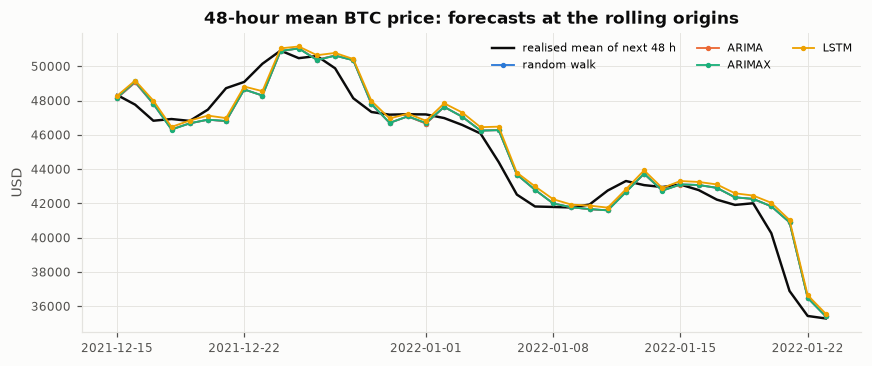

[A1] Table 8 reports an MAE of 756.90 USD at 48 h for its SNN on a different period (test after 2021-12-19, up to May 2022) and with a different target definition, so the levels are not comparable; the comparison that matters is with the random walk on the same origins.

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(fc.index, fc.y, color="#0b0b0b", lw=1.6, label="realised mean of next 48 h")
for i, m in enumerate(models):
    ax.plot(fc.index, fc[m], color=SERIES[i], lw=1.2, marker=".", label=m)
ax.set_title("48-hour mean BTC price: forecasts at the rolling origins")
ax.set_ylabel("USD")
ax.legend(fontsize=7, ncol=3)
R.fig(fig, "forecasts")
close(fig)
md("[A1] Table 8 reports an MAE of 756.90 USD at 48 h for its SNN on a different period (test after 2021-12-19, up "
   "to May 2022) and with a different target definition, so the levels are not comparable; the comparison that "
   "matters is with the random walk on the same origins.")

### 4. Interpretation (QUICK run: 40 daily origins, 2 LSTM seeds)

* **Sentiment follows prices, not the reverse.** The Granger tests do not reject "sentiment does not cause
  returns" at any lag ($p\ge0.40$), but strongly reject "returns do not cause sentiment" ($p<10^{-3}$ at every
  lag). Telegram crypto channels react to price moves (celebrating rallies, lamenting drops) rather than anticipate
  them. A predictor built on this sentiment can at best echo information already in the price.
* **No model beats the random walk.** Over the 40 origins (mid-December 2021 to January 2022) the random walk
  $\hat y_t=P_t$ has an MAE of about 756 USD (1.7 %). ARIMA and ARIMAX are within 2–3 USD of it, and the LSTM is about
  45 USD worse. None of the Diebold–Mariano tests rejects equal accuracy, even before the Holm correction
  ($p\ge0.18$). Adding sentiment to ARIMA changes the MAE by less than a dollar, consistent with the Granger result.
  This is the expected outcome for a liquid asset at a 48-hour horizon: its price is close to a martingale.
* **Comparison with [A1] §7.** The paper reports an MAE of 756.90 USD at 48 h for its SNN (test period after
  2021-12-19). Our random walk reaches almost the same value (756 USD) on an overlapping period. Unless the paper's
  number beats a random walk on its own sample, which the paper does not report, the experiment shows the
  difficulty of the task rather than the model's skill.

**Limitations.** The corpus ends in January 2022, which limits the test period to 40 overlapping 48-hour windows;
the DM test therefore has little power, and the full run (200 origins on a longer period) is needed for firmer
conclusions. VADER's lexicon is not tuned for crypto slang ("moon", "rekt", rocket emojis), which attenuates the
signal.

# Validation against [A1]

This chapter gathers, from the tables saved by each step, every quantity that [A1] reports and that this project
re-estimated. A claim is marked *reproduced* when our estimate is within 10 % (relative) of the paper's, *close* within
25 %, and *differs* otherwise; for hit ratios the tolerance is ±0.05 in absolute value.

In [1]:

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pnd_paper import settings
from pnd_paper.data import pd_log

RES = settings.RESULTS
def tab(nb, name, **kw):
    p = RES / nb / "tables" / f"{name}.csv"
    return pd.read_csv(p, **kw) if p.is_file() else None

def verdict(ours, theirs, abs_tol=None):
    if ours is None or theirs is None or not np.isfinite(ours) or not np.isfinite(theirs):
        return "n/a"
    if abs_tol is not None:
        d = abs(ours - theirs)
        return "reproduced" if d <= abs_tol else "close" if d <= 2 * abs_tol else "differs"
    rel = abs(ours - theirs) / abs(theirs)
    return "reproduced" if rel <= 0.10 else "close" if rel <= 0.25 else "differs"

F = settings.PAPER_FACTS
rows = []
log = pd_log.load_pd_log()
rows.append(("samples in the P&D log", F["samples"], len(log), "I0"))
evt = tab("I0_data_acquisition", "events_by_tolerance", index_col=0)
if evt is not None:
    rows.append(("P&D events (relayed rows merged, 1 h tolerance)", F["events"], float(evt.loc["1 hour", "events"]), "I0"))
    rows.append(("Binance events (1 h tolerance)", F["binance_events"], float(evt.loc["1 hour", "Binance events"]), "I0"))
rows.append(("channels", F["channels"], log.channel_id.nunique(), "I0"))
rows.append(("coins", F["coins"], log.coin.nunique(), "I0"))
pc = log.coin.value_counts()
rows.append(("re-pump probability (share of coins pumped more than once)", F["repump_probability"], float((pc > 1).mean()), "I2"))
ds = tab("IIB_machine_learning", "dataset_sizes", index_col=0)
if ds is not None:
    for s, key in (("train", "train_pos"), ("valid", "valid_pos"), ("test", "test_pos")):
        rows.append((f"positive samples, {s} split", F[key], float(ds.loc[s, "events"]), "IIB"))
    rows.append(("positive ratio", F["positive_ratio"], float(ds.loc[["train", "valid", "test"], "positives"].sum() / ds.loc[["train", "valid", "test"], "rows"].sum()), "IIB"))
x60 = tab("I3_event_study", "x60_vs_paper", index_col=0)
if x60 is not None:
    rows.append(("mean pre-pump return, x = 60 h (raw)", F["pre_pump_return_x60"], float(x60.iloc[0]["mean"]), "I3"))
facts = pd.DataFrame(rows, columns=["quantity", "[A1]", "this study", "notebook"])
facts["verdict"] = [verdict(o, t) for o, t in zip(facts["this study"], facts["[A1]"])]
display(facts.style.format({"[A1]": "{:.4g}", "this study": "{:.4g}"}).hide(axis="index"))

hr_rows = []
for nb, names in (("IIB_machine_learning", {"LR": "LR", "RF": "RF"}),
                  ("IIC_deep_learning", {"DNN (mean)": "DNN", "LSTM": "LSTM", "GRU": "GRU", "TCN": "TCN", "SNN": "SNN", "SNN_S": "SNNS"})):
    m = tab(nb, "test_mean", index_col=0)
    s = tab(nb, "test_std", index_col=0)
    if m is None:
        continue
    for ours, theirs in names.items():
        if ours not in m.index:
            continue
        for k in (1, 10, 30):
            hr_rows.append({"model": ours, "metric": f"HR@{k}", "[A1]": settings.PAPER_TABLE5.loc[f"HR@{k}", theirs],
                            "ours (mean)": m.loc[ours, f"HR@{k}"], "ours (sd)": s.loc[ours, f"HR@{k}"]})
for nb in ("IIB_machine_learning",):
    m = tab(nb, "test_mean", index_col=0)
    if m is not None:
        for extra in [i for i in m.index if i.startswith("LightGBM") or i == "LR-softmax"]:
            for k in (1, 10, 30):
                hr_rows.append({"model": extra, "metric": f"HR@{k}", "[A1]": np.nan, "ours (mean)": m.loc[extra, f"HR@{k}"],
                                "ours (sd)": tab(nb, "test_std", index_col=0).loc[extra, f"HR@{k}"]})
hr = pd.DataFrame(hr_rows)
if len(hr):
    hr["verdict"] = [verdict(o, t, abs_tol=0.05) for o, t in zip(hr["ours (mean)"], hr["[A1]"])]
    wide = hr.pivot_table(index="model", columns="metric", values=["[A1]", "ours (mean)"], sort=False)
    display(Markdown("**Test-set hit ratios: this study versus [A1] Tables 5–6** (ours: mean over seeds)."))
    display(wide.style.format("{:.3f}", na_rep="—"))
    best = hr[hr.metric == "HR@10"].sort_values("ours (mean)", ascending=False).iloc[0]
    display(Markdown(f"Best HR@10 in this study: **{best['model']}** ({best['ours (mean)']:.3f}); best in [A1]: SNN_S (0.623). "
                     f"Verdicts on the hit ratios: " + ", ".join(f"{k}: {v}" for k, v in hr.verdict.value_counts().items()) + "."))


quantity,[A1],this study,notebook,verdict
samples in the P&D log,1335,1335,I0,reproduced
"P&D events (relayed rows merged, 1 h tolerance)",709,704,I0,reproduced
Binance events (1 h tolerance),445,446,I0,reproduced
channels,108,108,I0,reproduced
coins,278,277,I0,reproduced
re-pump probability (share of coins pumped more than once),0.601,0.4874,I2,close
"positive samples, train split",648,648,IIB,reproduced
"positive samples, valid split",100,100,IIB,reproduced
"positive samples, test split",200,199,IIB,reproduced
positive ratio,0.0048,0.004914,IIB,reproduced


**Test-set hit ratios: this study versus [A1] Tables 5–6** (ours: mean over seeds).

Best HR@10 in this study: **LightGBM** (0.603); best in [A1]: SNN_S (0.623). Verdicts on the hit ratios: close: 12, reproduced: 10, n/a: 9, differs: 2.

# Conclusion

**What was reproduced.** The data match the description of the brief and of [A1]: 1 335 samples, 108 channels,
the Binance/BTC modelling population and almost exactly the paper's 648 / 100 / 200 split. The event study confirms a
significant pre-pump drift that peaks around 60 hours before the announcement, the central empirical fact behind
[A1]'s claim that targets are predictable, although our average return at $x=60$ is lower than the paper's 9.5 %.
Intra-channel homogeneity, described only qualitatively in [A1], passes a permutation test; the coordination network
recovers groups of channels that relay each other.

**Prediction.** The validation chapter compares our hit ratios with the paper's. Ranking the target among about 200
candidates one hour ahead is possible far beyond chance with every model; channel-history and market features carry
most of the signal (SHAP and ablations, II.B). Sequence models (II.C) and gradient boosting are the strongest models,
and the statistical tests indicate whether their differences are significant on 199 test events, a small sample on
which differences of a few points are rarely conclusive.

**Detection.** A CUSUM on GARCH residuals raises an alarm before the announcement for a sizeable share of pumps, with a
lead of only a few hours; volume-based detectors need a calibration that respects serial dependence or they flood
the analyst with false alarms.

## Limitations

* Hourly data blur the last hour before the pump; minute data were used only for the anatomy of 20 pumps.
* The QUICK configuration uses fewer seeds, permutations and tuning trials than the brief requires; the full run
  (`PND_QUICK=0 make all`) tightens confidence intervals but uses the same code.
* CoinGecko statistics are the authors' snapshots (targets and candidates from two files); missingness was checked
  for label leakage but cannot be re-downloaded without an API key.
* The pre-trained embedding shipped by the authors could not be mapped to coins; SNN$_S$ uses embeddings re-learned
  from the authors' Telegram corpus, restricted to messages before the test period.

## Ethics and the cost of false positives

A surveillance system acts on its alarms: each alarm triggers a review, possibly a suspicious-order report (STOR, Art.
92 MiCA) or trading restrictions. **False positives** have real costs: analysts' time, the reputation of coins and
projects wrongly suspected, delayed orders of honest investors, and alarm fatigue that makes true alarms easier to
miss. A ranking model with HR@10 around 0.6 still points to nine innocent coins for every target in its top ten, so
its output must support a human investigation, never trigger sanctions automatically. Conversely, publishing the
ranking of likely targets would itself be market-moving and could be exploited by manipulators; the models and their
outputs must remain internal to the surveillance function. Channel identities are anonymised throughout.

## Team contributions (annex)

| Role | Part I | Part II |
|---|---|---|
| E1 Data and repository | repository structure, Binance and CoinGecko data, I.2 | ranking dataset (II.B.1), reproducibility (`make all`) |
| E2 Bibliography and report | I.1, regulation (MAR, MiCA) | report integration, ethics, bonus II.D |
| E3 Econometrics | I.3 event study | II.A.1 ARMA–GARCH |
| E4 Networks and tests | I.5 coordination network, null model | II.A.2 CUSUM, Isolation Forest, final significance tests |
| E5 Machine learning | I.4 intra-channel homogeneity | II.B LR, RF, LightGBM, imbalance, SHAP |
| E6 Deep learning | repository SNN (TensorFlow 1) | II.C LSTM, GRU, TCN, SNN in PyTorch, ablations |

## References

1. S. Hu, Z. Zhang, S. Lu, B. He, Z. Li. Sequence-based target coin prediction for cryptocurrency pump-and-dump. *Proc.
   ACM Manag. Data* 1(1), art. 6, 2023. arXiv:2204.12929.
2. D. Pacheco, P.-M. Hui, C. Torres-Lugo, B. T. Truong, A. Flammini, F. Menczer. Uncovering coordinated networks on
   social media: methods and case studies. *ICWSM* 15:455–466, 2021.
3. S. Hu et al. Pump-and-Dump-Detection-on-Cryptocurrency, GitHub repository.
4. J. Xu, B. Livshits. The anatomy of a cryptocurrency pump-and-dump scheme. *USENIX Security*, 2019.
5. T. Bollerslev. Generalized autoregressive conditional heteroskedasticity. *J. Econometrics* 31(3):307–327, 1986.
6. V. D. Blondel et al. Fast unfolding of communities in large networks. *J. Stat. Mech.*, P10008, 2008.
7. E. S. Page. Continuous inspection schemes. *Biometrika* 41:100–115, 1954.
8. F. T. Liu, K. M. Ting, Z.-H. Zhou. Isolation forest. *ICDM*, 2008.
9. S. M. Lundberg, S.-I. Lee. A unified approach to interpreting model predictions. *NeurIPS*, 2017.
10. F. X. Diebold, R. S. Mariano. Comparing predictive accuracy. *J. Business & Economic Statistics* 13:253–263, 1995.
11. C. J. Hutto, E. Gilbert. VADER: a parsimonious rule-based model for sentiment analysis of social media text.
    *ICWSM*, 2014.
12. Regulation (EU) No 596/2014 (MAR); Regulation (EU) 2023/1114 (MiCA); Commission Delegated Regulation (EU) 2016/522.
